# Classificação de imagens de satélite (EuroSAT RGB): MLP × CNN × Transfer Learning em CPU

**Disciplina:** Desenvolvimento de Aplicação para Reconhecimento e Interpretação de Imagens
**Alunos:** Eric Costa Ciciliotti e Yuri Martinelli · **Professor:** Humberto Tozetti

> 📄 **Leitura principal:** o relatório com as decisões, as tabelas de resultados e a recomendação está no arquivo [`relatorio.ipynb`](relatorio.ipynb), entregue junto com este notebook. Aqui está a implementação completa e as evidências.

### Resultado em resumo

- **Dataset:** EuroSAT RGB (Sentinel-2): 27.000 imagens 64×64 em 10 classes de uso do solo, com classes parecidas (agrícolas; rodovia × rio) e desbalanceamento leve (razão 1,5). Usamos um subconjunto estratificado de 5.000 / 1.000 / 2.000 (treino / validação / teste) para caber em CPU (A2, A3).
- **Decisões:** pré-processamento dentro de cada modelo; **F1-macro** como métrica principal; early stopping e data augmentation (flips e rotações); escolha de cada variante **só pela validação**, com o teste apenas reportado; tudo em CPU.
- **Limitação da MLP:** o `Flatten` descarta a vizinhança entre pixels. Ela fica em underfitting (~56% de accuracy no treino), e nenhuma regularização tira o F1 de ~0,5 (A5, A6).

| Abordagem (variante escolhida pela validação) | F1-macro (teste) | Accuracy (teste) | Tempo de treino em CPU | Parâmetros (totais / treinados) |
|---|---|---|---|---|
| MLP (MLP + ES + augmentation) | 0,498 | 0,518 | ~80 s | 3.180.170 / 3.180.170 |
| CNN própria (CNN + ES + augmentation) | 0,778 | 0,791 | ~190 s | 111.050 / 111.050 |
| **Transfer Learning** (MobileNetV2 congelada + `Dense(10)`) | **0,902** | **0,906** | ~160 s | 2.270.794 / **12.810** |

**Recomendação:** Transfer Learning com feature extraction. Ganha 12 pontos de F1 da CNN e treina na mesma ordem de tempo (nesta execução, até um pouco mais rápido). O fine-tuning empatou com custo ~40–50% maior, e a MLP não serve para imagens porque perde a vizinhança entre pixels. A análise completa está na seção B4 e no [`relatorio.ipynb`](relatorio.ipynb).

**Objetivo:** classificar as 10 classes de uso do solo do EuroSAT comparando três abordagens sob o **mesmo protocolo** (mesmo split, mesma perda, mesmo otimizador, mesmo batch e o mesmo critério de parada: early stopping na `val_loss`, exceto no baseline da MLP, que é o "antes" do diagnóstico) e escolher a que vale mais a pena considerando desempenho, custo em CPU e tamanho do dataset.

### Como executar
- **Colab:** `Ambiente de execução → Alterar o tipo → CPU` e depois `Executar tudo`. O dataset é baixado automaticamente.
- **Local:** `uv sync` e abrir o notebook com o kernel do `.venv`. Os números e tempos reportados vêm da execução local (Intel Core i5-10400F, só CPU).
- **Modo smoke** (opcional, só para validar o código em ~2–3 min): definir `SMOKE_TEST=1` antes de rodar (no Colab: uma célula com `%env SMOKE_TEST=1` no topo). O código é o mesmo; só os tamanhos e as épocas diminuem.

### Sumário
| Parte | Seção | Conteúdo |
|---|---|---|
| A — Dados e MLP | A1 | Setup: imports, constantes, CPU forçada, reprodutibilidade |
| | A2 | Dataset e análise exploratória |
| | A3 | Subconjunto, split estratificado e pré-processamento |
| | A4 | Funções utilitárias (treino, curvas, avaliação) |
| | A5 | MLP baseline e métricas |
| | A6 | Diagnóstico de overfitting e regularização |
| B — CNN e Transfer Learning | B1 | CNN própria (do zero) |
| | B2 | Transfer Learning: feature extraction (MobileNetV2) |
| | B3 | Transfer Learning: fine-tuning |
| | B4 | Comparação final e recomendação |

# PARTE A — Dados e MLP

## A1. Setup

**O que:** imports, constantes do experimento, sementes e configuração de hardware, tudo num único lugar.

**Por quê:**
- **CPU forçada:** o enunciado compara o custo computacional em CPU. Escondemos qualquer GPU (`CUDA_VISIBLE_DEVICES=-1`) **antes** de importar o TensorFlow; depois do import, a configuração já não tem efeito.
- **Reprodutibilidade:** uma única semente (`SEED`) fixa o split, a inicialização dos pesos e a ordem dos lotes. Em CPU com várias threads, ainda podem surgir pequenas variações numéricas entre execuções (e entre máquinas), sem mudar as conclusões.
- **Modo smoke:** com `SMOKE_TEST=1` o notebook roda o **mesmo código** com poucos dados e 1–2 épocas, só para validar que tudo executa antes da execução completa.

In [1]:
import os

# Precisam ser definidas ANTES de importar o TensorFlow/Keras.
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"   # esconde GPUs: todos os tempos são de CPU
os.environ["KERAS_BACKEND"] = "tensorflow"  # Keras 3 é multi-backend; fixamos o TensorFlow
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"    # silencia os logs informativos do TF em C++

import hashlib
import io
import platform
import time
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split

import tensorflow as tf
import keras
from keras import layers

tf.get_logger().setLevel("ERROR")  # esconde avisos do TF que não afetam os resultados

### Constantes do experimento

Todas as escolhas que afetam a comparação ficam aqui, valendo **igualmente para todos os modelos**. Nenhuma outra seção redefine esses valores.

| Decisão | Escolha | Por quê |
|---|---|---|
| Subconjunto | 5.000 treino · 1.000 validação · 2.000 teste | Limite de ~5.000 imagens de treino sugerido para CPU; teste maior reduz o ruído das métricas |
| Resolução | 64×64 (nativa); 96×96 só dentro do modelo de TL | Todos recebem o mesmo array; 96 é o menor tamanho com pesos ImageNet na MobileNetV2 |
| Lote (**batch size**) | 64 | ~79 atualizações de pesos por época; bom equilíbrio entre velocidade e estabilidade em CPU |
| Orçamento de épocas | 40 (MLP/CNN) · 15 por etapa (TL) | Espaço para o overfitting aparecer nas curvas; a MobileNetV2 já parte de pesos treinados, converge rápido e cada época dela custa mais |
| **Early stopping** | paciência 8 (MLP/CNN) · 4 (TL) | Cerca de 1/4 do orçamento de cada modelo: tolera oscilações da `val_loss` sem desperdiçar épocas |
| Taxa de aprendizado | Adam 1e-3 · fine-tuning 1e-5 | Padrão do Adam; no fine-tuning, 100× menor para não destruir os pesos pré-treinados |
| Regularização da MLP (A6) | dropout 0,3 · L2 1e-4 | Leve de propósito: o baseline tem underfitting (A5), e regularização forte pioraria o ajuste |

O critério de parada é o mesmo para todos (early stopping na `val_loss`, restaurando a melhor época); o que muda no TL é só o teto de épocas, porque ele parte de pesos já treinados.

In [2]:
# --- Reprodutibilidade e modo de execução ---
SEED = 42
SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"

# --- Caminhos ---
DATA_DIR = Path("data")
ZIP_PATH = DATA_DIR / "eurosat_rgb.zip"  # as imagens são lidas direto do zip (sem extrair)
DATA_URL = "https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip?download=1"
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
# Arquivo separado no smoke: uma validação rápida nunca sobrescreve os resultados reais.
RESULTS_CSV = OUTPUT_DIR / ("resultados_eurosat_smoke.csv" if SMOKE_TEST else "resultados_eurosat.csv")
F1_CLASSES_CSV = OUTPUT_DIR / ("f1_por_classe_eurosat_smoke.csv" if SMOKE_TEST else "f1_por_classe_eurosat.csv")
EXECUCAO_CSV = OUTPUT_DIR / ("execucao_eurosat_smoke.csv" if SMOKE_TEST else "execucao_eurosat.csv")  # de qual execução vieram os CSVs

# --- Dados ---
IMG_SIZE = 64      # resolução nativa do EuroSAT; entrada de todos os modelos
TL_IMG_SIZE = 96   # Resizing dentro do modelo de TL (menor tamanho com pesos ImageNet)
N_TRAIN, N_VAL, N_TEST = 5_000, 1_000, 2_000

# --- Treino (iguais para todos os modelos) ---
BATCH_SIZE = 64
MAX_EPOCHS = 40     # MLP e CNN
TL_EPOCHS = 15      # cada etapa do TL (feature extraction e fine-tuning)
PATIENCE = 8        # early stopping em val_loss (MLP e CNN)
TL_PATIENCE = 4     # early stopping em val_loss (TL)
LR = 1e-3           # Adam
LR_FINE_TUNE = 1e-5 # etapa 2 do TL
FINE_TUNE_FROM = "block_14_expand"  # camadas da MobileNetV2 a partir desta são descongeladas

# --- Regularização da MLP (A6) ---
DROPOUT_MLP = 0.3   # após cada camada oculta
L2_MLP = 1e-4       # penalidade nos pesos das camadas ocultas

# Modo smoke: mesmo código, só tamanhos e épocas menores (~10 imagens/classe em val e teste,
# proporcional ao tamanho de cada classe).
if SMOKE_TEST:
    N_TRAIN, N_VAL, N_TEST = 300, 100, 100
    MAX_EPOCHS, TL_EPOCHS = 2, 1

keras.utils.set_random_seed(SEED)  # semeia Python, NumPy e TensorFlow de uma vez

pd.Series({
    "Modo": "SMOKE (validação rápida)" if SMOKE_TEST else "completo",
    "Treino / validação / teste": f"{N_TRAIN} / {N_VAL} / {N_TEST}",
    "Batch size": BATCH_SIZE,
    "Épocas máx. (MLP/CNN · TL por etapa)": f"{MAX_EPOCHS} · {TL_EPOCHS}",
    "Paciência do early stopping (MLP/CNN · TL)": f"{PATIENCE} · {TL_PATIENCE}",
    "Taxa de aprendizado (Adam · fine-tuning)": f"{LR:g} · {LR_FINE_TUNE:g}",
    "Fine-tuning a partir de": FINE_TUNE_FROM,
    "Regularização da MLP (dropout · L2)": f"{DROPOUT_MLP:g} · {L2_MLP:g}",
    "Semente": SEED,
}, name="valor").to_frame()


,valor
Modo,completo
Treino / validação / teste,5000 / 1000 / 2000
Batch size,64
Épocas máx. (MLP/CNN · TL por etapa),40 · 15
Paciência do early stopping (MLP/CNN · TL),8 · 4
Taxa de aprendizado (Adam · fine-tuning),0.001 · 1e-05
Fine-tuning a partir de,block_14_expand
Regularização da MLP (dropout · L2),0.3 · 0.0001
Semente,42


### Estilo dos gráficos

**O que:** um estilo global do matplotlib e uma paleta fixa.
**Por quê:** a mesma cor significa a mesma coisa em todo o notebook (**treino = azul**, **validação = laranja**), o que facilita comparar as curvas dos diferentes modelos.

In [3]:
CORES = {
    "treino": "#2a78d6",     # azul
    "validacao": "#eb6834",  # laranja
    "destaque": "#1baf7a",   # verde
    "neutro": "#898781",     # cinza
}

plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.dpi": 100,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linestyle": "--",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "lines.linewidth": 2,
    "legend.frameon": False,
    "image.cmap": "Blues",   # matrizes de confusão e heatmaps
})

### Ambiente de execução

**O que:** versões das bibliotecas, processador e dispositivos visíveis ao TensorFlow.
**Por quê:** os **tempos de treino** da comparação final só fazem sentido junto com o hardware em que foram medidos. A lista de GPUs deve sair **vazia**, confirmando que tudo roda em CPU.

In [4]:
def nome_do_processador():
    """Nome comercial da CPU; platform.processor() sozinho é vago (Windows) ou vazio (Linux/Colab)."""
    if platform.system() == "Windows":
        import winreg
        chave = winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE, r"HARDWARE\DESCRIPTION\System\CentralProcessor\0")
        return winreg.QueryValueEx(chave, "ProcessorNameString")[0].strip()
    cpuinfo = Path("/proc/cpuinfo")
    if cpuinfo.exists():
        for linha in cpuinfo.read_text().splitlines():
            if linha.startswith("model name"):
                return linha.split(":", 1)[1].strip()
    return platform.processor() or "desconhecido"

pd.Series({
    "Sistema": f"{platform.system()} {platform.release()}",
    "Processador": nome_do_processador(),
    "Núcleos lógicos": os.cpu_count(),
    "Python": platform.python_version(),
    "TensorFlow": tf.__version__,
    "Keras": keras.__version__,
    "Backend do Keras": keras.backend.backend(),
    "GPUs visíveis": len(tf.config.list_physical_devices("GPU")),
}, name="valor").to_frame()

,valor
Sistema,Windows 11
Processador,Intel(R) Core(TM) i5-10400F CPU @ 2.90GHz
Núcleos lógicos,12
Python,3.12.14
TensorFlow,2.21.0
Keras,3.15.1
Backend do Keras,tensorflow
GPUs visíveis,0


## A2. Dataset e análise exploratória

**EuroSAT RGB** ([Helber et al., 2019](https://doi.org/10.1109/JSTARS.2019.2918242)): recortes de imagens do satélite **Sentinel-2** (programa Copernicus, da agência espacial europeia) cobrindo 34 países europeus. São **27.000 imagens de 64×64 pixels** (10 m por pixel), rotuladas em **10 classes de uso do solo**. Usamos a versão RGB (3 bandas visíveis) publicada no [Zenodo (registro 7711810)](https://zenodo.org/records/7711810).

| Classe | Significado |
|---|---|
| AnnualCrop · PermanentCrop | Lavoura temporária · lavoura permanente (pomares, vinhedos) |
| Forest · HerbaceousVegetation · Pasture | Floresta · vegetação rasteira · pastagem |
| Highway · Industrial · Residential | Rodovia · área industrial · área residencial |
| River · SeaLake | Rio · mar ou lago |

**Por que atende aos critérios do enunciado:**
- Classificação de imagens com **10 classes**, no limite superior pedido.
- Imagens pequenas: viável em CPU com o subconjunto de 5.000 imagens de treino.
- **Dificuldade real:** classes parecidas entre si (as três classes agrícolas; rodovia × rio, que têm a mesma forma linear), variação de iluminação, estação do ano e país, e um desbalanceamento leve. Os itens a seguir mostram cada um desses pontos.
- Com CNNs profundas treinadas no dataset inteiro, o artigo original passa de 98% de accuracy. A dificuldade aqui está no **nosso protocolo**: uma MLP que não enxerga estrutura espacial, só 5.000 imagens de treino e tudo em CPU.

### Download e leitura

**O que:** baixar o zip (~95 MB) só se ele ainda não existir e ler as 27.000 imagens **direto do zip**, guardando para cada uma a classe (nome da pasta), o tamanho, o modo de cor e o **hash MD5** dos bytes.
**Por quê:**
- **Idempotente:** reexecutar o notebook não baixa de novo. O download vai para um arquivo temporário, então uma queda no meio não deixa um zip corrompido para trás.
- **Sem extrair:** ler direto do zip leva segundos; extrair 27.000 arquivos pequenos em disco é bem mais lento.
- O **MD5** serve para encontrar imagens duplicadas mais adiante.

In [5]:
if not ZIP_PATH.exists():
    DATA_DIR.mkdir(exist_ok=True)
    print(f"Baixando {DATA_URL} ...")
    temporario = ZIP_PATH.with_suffix(".part")  # só vira o zip final se o download terminar
    urllib.request.urlretrieve(DATA_URL, temporario)
    temporario.replace(ZIP_PATH)
assert zipfile.is_zipfile(ZIP_PATH), f"{ZIP_PATH} está corrompido: apague o arquivo e rode de novo."

inicio = time.perf_counter()
registros, imagens = [], []
with zipfile.ZipFile(ZIP_PATH) as arquivo_zip:
    # Ordem alfabética: a mesma lista em qualquer máquina (base para o split reprodutível).
    nomes = sorted(n for n in arquivo_zip.namelist() if n.lower().endswith(".jpg"))
    for nome in nomes:
        conteudo = arquivo_zip.read(nome)
        img = Image.open(io.BytesIO(conteudo))
        registros.append({
            "arquivo": nome,
            "classe": nome.split("/")[-2],  # EuroSAT_RGB/<classe>/<arquivo>.jpg
            "largura": img.width,
            "altura": img.height,
            "modo": img.mode,
            "md5": hashlib.md5(conteudo).hexdigest(),
        })
        imagens.append(np.asarray(img.convert("RGB")))

df_imagens = pd.DataFrame(registros)
# Sanidade: confirma que o zip é o EuroSAT RGB esperado (e não outra versão do dataset).
assert len(df_imagens) == 27_000 and df_imagens["classe"].nunique() == 10, "Zip inesperado."
print(f"{len(df_imagens):,} imagens de {df_imagens['classe'].nunique()} classes lidas em "
      f"{time.perf_counter() - inicio:.1f} s".replace(",", "."))

Baixando https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip?download=1 ...


27.000 imagens de 10 classes lidas em 7.5 s


### Distribuição de classes

**O que:** quantidade e proporção de imagens por classe no dataset completo, em tabela e em gráfico de barras.
**Por quê:** se as classes forem desbalanceadas, a **accuracy** sozinha engana (acertar a classe grande "vale mais"), e isso define a métrica principal e o tipo de split.

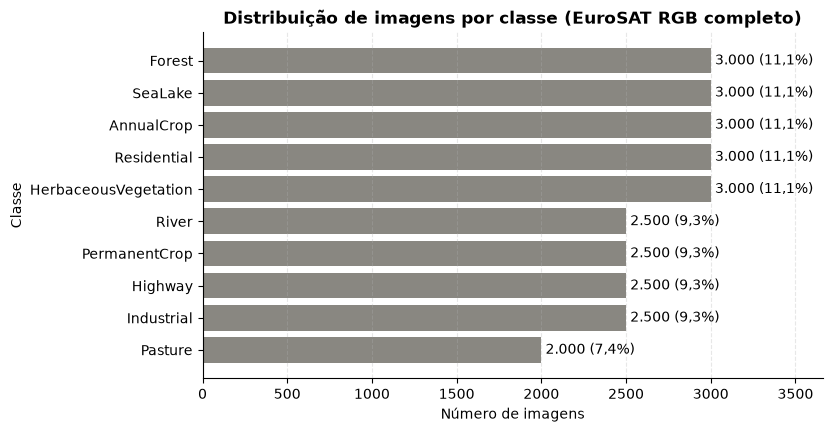

In [6]:
contagem = df_imagens["classe"].value_counts().sort_values()
proporcao = 100 * contagem / contagem.sum()

fig, ax = plt.subplots(figsize=(8, 4.5))
barras = ax.barh(contagem.index, contagem.values, color=CORES["neutro"])
rotulos = [f"{n:,} ({p:.1f}%)".replace(",", "X").replace(".", ",").replace("X", ".")
           for n, p in zip(contagem.values, proporcao.values)]
ax.bar_label(barras, labels=rotulos, padding=3)
ax.set_title("Distribuição de imagens por classe (EuroSAT RGB completo)")
ax.set_xlabel("Número de imagens")
ax.set_ylabel("Classe")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, contagem.max() * 1.22)
plt.show()

**Interpretação:**
- O desbalanceamento é **leve**: as maiores classes têm 3.000 imagens e a menor (Pasture) tem 2.000, uma razão de **1,5**.
- Mesmo leve, ele justifica duas escolhas do protocolo:
  - **Split estratificado**, para que treino, validação e teste tenham as mesmas proporções.
  - **F1-macro** como métrica principal, porque ela dá o mesmo peso a cada classe; a accuracy favorece as classes grandes.
- Não aplicamos `class_weight` nem reamostragem por enquanto. Só faremos isso se as métricas por classe mostrarem a classe menor prejudicada.

### Dimensões e formato

**O que:** conferir o tamanho (largura × altura) e o modo de cor de todas as imagens e, se forem uniformes, empilhá-las num único array `uint8` de forma `(N, 64, 64, 3)`, com os rótulos como inteiros de 0 a 9.
**Por quê:** redes neurais exigem entradas de **tamanho fixo**. Se houvesse tamanhos diferentes, precisaríamos redimensionar antes. O array `uint8` (0–255) é a entrada única de **todos** os modelos; a normalização acontece dentro de cada modelo.

In [7]:
formatos = (
    df_imagens.groupby(["largura", "altura", "modo"]).size()
    .rename("imagens").reset_index()
)
display(formatos)

assert (df_imagens["largura"] == IMG_SIZE).all() and (df_imagens["altura"] == IMG_SIZE).all(), \
    "Há imagens fora de 64×64: seria preciso redimensionar antes de empilhar."

CLASSES = sorted(df_imagens["classe"].unique())        # ordem alfabética → rótulos 0..9
indice_da_classe = {classe: i for i, classe in enumerate(CLASSES)}

# A lista `imagens` foi preenchida no mesmo laço que df_imagens: mesma ordem, mesmo tamanho.
assert len(imagens) == len(df_imagens)
X_todas = np.stack(imagens)                             # (N, 64, 64, 3), uint8, valores 0–255
y_todas = df_imagens["classe"].map(indice_da_classe).to_numpy()
del imagens  # evita cópia duplicada na memória (para refazer, rode a célula de leitura)

print(f"X_todas: {X_todas.shape}, {X_todas.dtype}, {X_todas.nbytes / 1e6:.0f} MB · "
      f"pixels de {X_todas.min()} a {X_todas.max()}")
print(f"y_todas: {y_todas.shape} · classes: {dict(enumerate(CLASSES))}")

,largura,altura,modo,imagens
0,64,64,RGB,27000


X_todas: (27000, 64, 64, 3), uint8, 332 MB · pixels de 0 a 255
y_todas: (27000,) · classes: {0: 'AnnualCrop', 1: 'Forest', 2: 'HerbaceousVegetation', 3: 'Highway', 4: 'Industrial', 5: 'Pasture', 6: 'PermanentCrop', 7: 'Residential', 8: 'River', 9: 'SeaLake'}


### Duplicatas

**O que:** procurar imagens **idênticas byte a byte** (mesmo hash MD5) e remover as cópias, mantendo a primeira ocorrência.
**Por quê:** se a mesma imagem caísse no treino e no teste, o modelo seria avaliado numa imagem que já "viu", o que é **vazamento de dados** e infla as métricas. A remoção acontece **antes** do split (A3), e lá um `assert` confirma que nenhum hash aparece em dois conjuntos. Também verificamos se alguma duplicata aparece com **rótulos diferentes**, o que indicaria erro de rotulagem.

In [8]:
copias = df_imagens["md5"].duplicated(keep="first")      # True a partir da 2ª ocorrência
rotulos_por_hash = df_imagens.groupby("md5")["classe"].nunique()
hashes_conflitantes = rotulos_por_hash[rotulos_por_hash > 1].index
# Imagem com rótulos diferentes: não sabemos qual está certo, então saem todas as cópias.
conflitantes = df_imagens["md5"].isin(hashes_conflitantes)
remover = (copias | conflitantes).to_numpy()

display(pd.Series({
    "Imagens lidas": len(df_imagens),
    "Hashes que aparecem mais de uma vez": int((df_imagens["md5"].value_counts() > 1).sum()),
    "Hashes com rótulos conflitantes": len(hashes_conflitantes),
    "Imagens removidas": int(remover.sum()),
    "Imagens únicas mantidas": int((~remover).sum()),
}, name="quantidade").to_frame())

# Filtra os três objetos juntos para manter tabela, imagens e rótulos alinhados.
df_imagens = df_imagens[~remover].reset_index(drop=True)
X_todas, y_todas = X_todas[~remover], y_todas[~remover]
assert df_imagens["md5"].is_unique and len(df_imagens) == len(X_todas) == len(y_todas)

,quantidade
Imagens lidas,27000
Hashes que aparecem mais de uma vez,0
Hashes com rótulos conflitantes,0
Imagens removidas,0
Imagens únicas mantidas,27000


### Exemplos visuais

**O que:** 6 imagens sorteadas de cada classe (uma classe por linha).
**Por quê:** ver os dados antes de modelar mostra quais classes são fáceis de distinguir pela cor e quais só se separam pela **textura** ou pela **forma**, que é justamente o que uma MLP tem dificuldade de capturar.

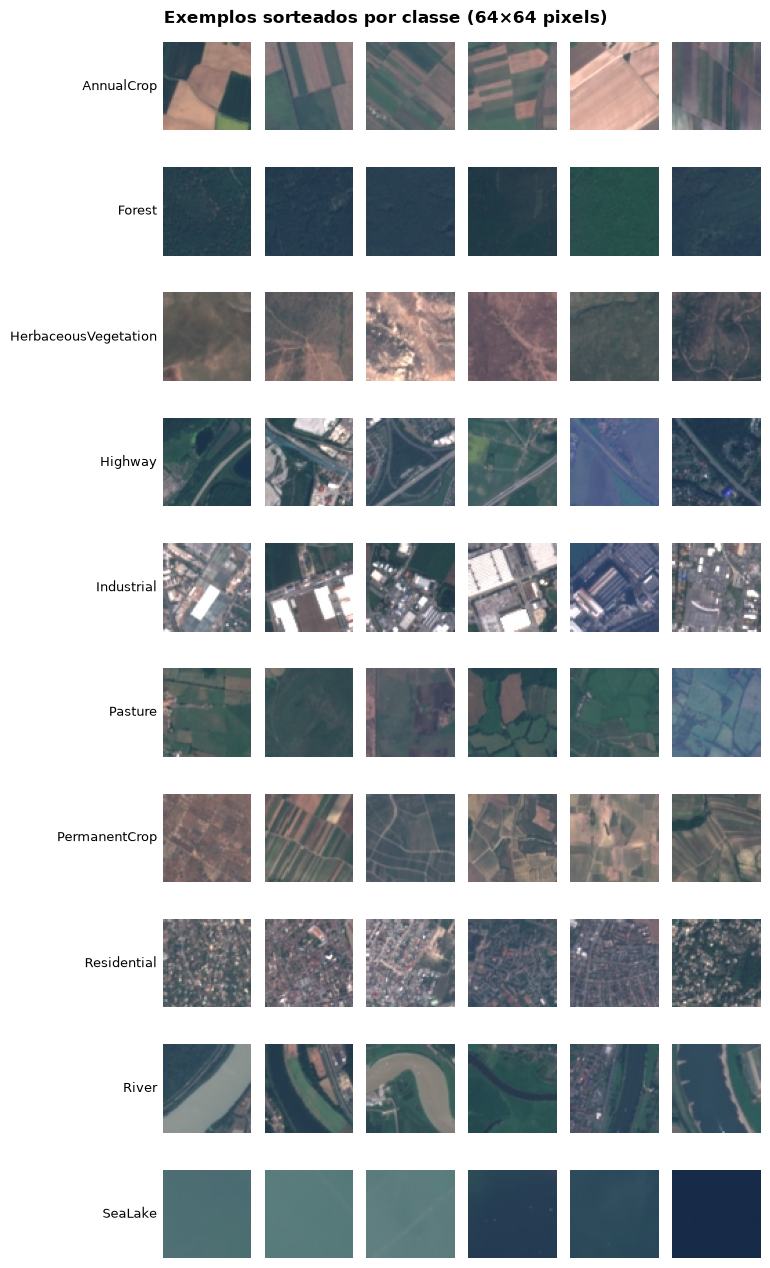

In [9]:
exemplos_por_classe = 6
gerador = np.random.default_rng(SEED)  # sorteio próprio: não altera a semente global

fig, eixos = plt.subplots(len(CLASSES), exemplos_por_classe,
                          figsize=(exemplos_por_classe * 1.3, len(CLASSES) * 1.3))
for linha, classe in enumerate(CLASSES):
    sorteados = gerador.choice(np.flatnonzero(y_todas == linha), exemplos_por_classe, replace=False)
    for coluna, indice in enumerate(sorteados):
        ax = eixos[linha, coluna]
        ax.imshow(X_todas[indice])
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for borda in ax.spines.values():
            borda.set_visible(False)
    eixos[linha, 0].set_ylabel(classe, rotation=0, ha="right", va="center", fontsize=9)

fig.suptitle("Exemplos sorteados por classe (64×64 pixels)", fontweight="bold")
fig.tight_layout()
plt.show()

**Interpretação:**
- **Classes fáceis:** SeaLake e Forest são cenas **homogêneas**, quase sem textura (água lisa, copa contínua). Já as classes urbanas têm uma textura densa e característica.
- **Classes parecidas pela forma e pela textura:**
  - **AnnualCrop, PermanentCrop e Pasture** são mosaicos de parcelas agrícolas, e o que as diferencia é sutil: tamanho dos talhões, fileiras de plantio, tom da vegetação.
  - **Highway × River** compartilham a mesma estrutura: uma faixa linear cortando a imagem.
- **Variação dentro da mesma classe:** a mesma cena aparece com brilho e tom bem diferentes (SeaLake vai do verde-claro ao azul-marinho), por causa de iluminação, estação do ano, país e condições atmosféricas.
- **Sem orientação fixa:** rodovias, rios e talhões aparecem em qualquer ângulo e posição. Por isso, **flips e rotações** são augmentations válidos aqui: uma imagem de satélite girada continua sendo da mesma classe.

### Imagem média por classe

**O que:** a média, pixel a pixel, das imagens de cada classe, e o brilho médio de cada canal (R, G, B).
**Por quê:** mostra se a **posição** dos elementos se repete entre as imagens de uma classe e qual é a "assinatura de cor" de cada uma. São estatísticas **apenas descritivas**: nenhuma entra nos modelos, cuja normalização usa constantes fixas.

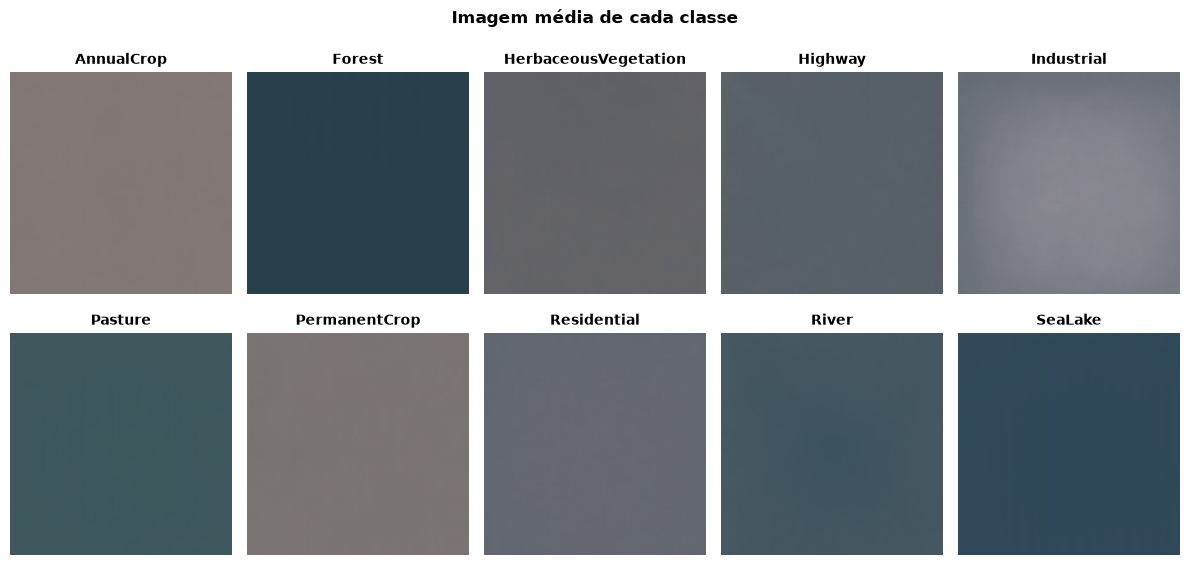

,R médio,G médio,B médio
AnnualCrop,129.6,120.0,117.2
Forest,39.4,64.5,76.0
HerbaceousVegetation,98.2,98.7,103.9
Highway,88.0,96.7,103.4
Industrial,123.4,125.4,134.3
Pasture,61.9,88.5,94.2
PermanentCrop,122.1,116.0,114.0
Residential,100.1,103.8,113.0
River,67.0,86.6,96.9
SeaLake,48.1,72.8,89.1


In [10]:
medias = np.stack([X_todas[y_todas == i].mean(axis=0, dtype=np.float32) for i in range(len(CLASSES))])

fig, eixos = plt.subplots(2, 5, figsize=(12, 6))
for i, ax in enumerate(eixos.flat):
    ax.imshow(medias[i] / 255)
    ax.set_title(CLASSES[i], fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for borda in ax.spines.values():
        borda.set_visible(False)
fig.suptitle("Imagem média de cada classe", fontweight="bold")
fig.tight_layout()
plt.show()

# Brilho médio de cada canal (0–255): resume a "assinatura de cor" de cada classe.
cores_medias = medias.mean(axis=(1, 2)).astype(float)
pd.DataFrame(cores_medias, index=CLASSES, columns=["R médio", "G médio", "B médio"]).round(1)

**Interpretação:**
- As imagens médias são **manchas quase uniformes**: estradas, rios e talhões aparecem em posições diferentes em cada foto e se anulam na média. Só Industrial (centro mais claro) e River (mancha escura fraca no centro) mantêm algum vestígio de estrutura.
- **Consequência para a MLP:** depois do `Flatten`, cada pixel vira uma entrada com peso próprio. A mesma rodovia deslocada 10 pixels ativa entradas totalmente diferentes, e a MLP precisa aprender cada posição separadamente. Uma **CNN** aplica os mesmos filtros em toda a imagem e reconhece o padrão onde quer que ele esteja.
- **Cor média:** alguns pares de classes têm assinaturas próximas.
  - **AnnualCrop × PermanentCrop:** RGB ≈ 130/120/117 × 122/116/114.
  - **Pasture × River:** ≈ 62/89/94 × 67/87/97.
  - **HerbaceousVegetation, Highway e Residential:** cinzas com R entre 88 e 100.
- Média próxima **não implica** confusão: a variação dentro de cada classe é grande. Forest e SeaLake, por exemplo, também têm médias vizinhas, mas a homogeneidade das duas deve bastar para separá-las das demais.

**Hipótese a conferir nas matrizes de confusão (A5, B1 e B4):** as confusões principais devem ficar entre as classes agrícolas (AnnualCrop, PermanentCrop, Pasture, HerbaceousVegetation) e entre Highway × River. Se isso se confirmar, a MLP deve sofrer mais nesses pares, porque separá-los exige **textura e forma**, não só cor.

### Síntese da análise exploratória

| Achado | Consequência no protocolo |
|---|---|
| 27.000 imagens, todas 64×64 RGB, sem duplicatas exatas | Nenhum redimensionamento para MLP/CNN; o array `uint8` é a entrada única de todos os modelos |
| Desbalanceamento leve (razão 1,5) | Split **estratificado** e **F1-macro** como métrica principal |
| Classes agrícolas e Highway × River parecidas na forma/textura | Hipótese de confusões a conferir nas matrizes; vantagem esperada para CNN e TL |
| Cenas sem orientação canônica | Flips horizontal/vertical e rotação como **data augmentation** (A6 em diante) |

**Por que esta análise sobre o dataset inteiro não causa vazamento de dados.** Existe vazamento quando informação da validação ou do teste é usada para **ajustar** algo no modelo ou para **escolher** algo com base em desempenho. Por exemplo: um normalizador ajustado com todos os dados, uma reamostragem antes do split, ou features escolhidas olhando o conjunto todo. Aqui:
- Inventário, dimensões e contagens são **metadados**. As contagens por classe estão publicadas no próprio artigo do dataset.
- A remoção de duplicatas só compara bytes e **precisa** vir antes do split: é ela que impede a mesma imagem de cair no treino e no teste.
- A imagem média e a cor média são **apenas descritivas**. Nenhuma estatística daqui entra nos modelos: a normalização usa constantes fixas (`1/255` ou `[-1, 1]`).
- As decisões da tabela acima (estratificação, F1-macro, flips e rotação) vêm do domínio do problema, não do desempenho em validação ou teste.

**Daqui em diante:**
- Tudo o que for **calculado a partir dos dados** para o treino (por exemplo, pesos de classe, se forem necessários) usa **só o treino**.
- O data augmentation é aplicado **só durante o treino** (camadas dentro do modelo, inativas na avaliação).
- As escolhas entre modelos e regularizações usam **só a validação**.
- O teste serve apenas para reportar os números finais.

## A3. Subconjunto, split e pré-processamento

### Por que um subconjunto, e como ele é criado

Das 27.000 imagens únicas, sorteamos **8.000**:

| Conjunto | Imagens | Papel |
|---|---|---|
| Treino | 5.000 | Ajustar os pesos dos modelos |
| Validação | 1.000 | Early stopping e todas as escolhas (regularização, qual MLP vai para a comparação) |
| Teste | 2.000 | Só para reportar os números finais; não influencia nenhuma decisão |

**Por que um subconjunto:**
- **Custo em CPU:** com o dataset inteiro, o treino teria cerca de 4× mais imagens, e cada época custaria cerca de 4× mais. O peso maior cairia no Transfer Learning, que processa imagens de 96×96 numa rede bem mais profunda. Nossa estimativa para o TL com 5.000 imagens era de ~10 min na máquina local, e o medido foi ~8 min para treinar as quatro variantes (B2 e B3, ver B4). No Colab, estimamos 20–30 min ✍️ (conferir na entrega).
- **Regime de poucos dados:** com 5.000 exemplos, fica visível o que cada abordagem extrai de um conjunto pequeno. É aí que a comparação entre aprender do zero (MLP, CNN) e reaproveitar conhecimento pré-treinado (TL) é mais informativa.
- O limite de ~5.000 do enunciado vale para o **treino**. Validação e teste só passam por inferência, que é barata.

**Por que o teste é o dobro da validação:** o teste dá a estimativa final, então vale reduzir o ruído dela. No pior caso (accuracy de 50%), o erro-padrão √(p·(1−p)/n) é de cerca de **1,1 ponto percentual** com 2.000 imagens, contra **1,6** com 1.000.

**Como:** sorteio **estratificado** por classe com `train_test_split` (semente 42), em duas etapas: primeiro treino × resto, depois o resto em validação × teste. O split usa os rótulos só para estratificar e não ajusta nada; um `assert` confirma que nenhuma imagem cai em dois conjuntos. As ~19.000 imagens restantes não são usadas.

In [11]:
indices = np.arange(len(y_todas))

# Etapa 1: treino × resto (o restante das 27 mil imagens é descartado pelo próprio split).
idx_treino, idx_resto = train_test_split(
    indices, train_size=N_TRAIN, test_size=N_VAL + N_TEST,
    stratify=y_todas, random_state=SEED,
)
# Etapa 2: o resto vira validação × teste, de novo estratificado.
idx_val, idx_teste = train_test_split(
    idx_resto, train_size=N_VAL, test_size=N_TEST,
    stratify=y_todas[idx_resto], random_state=SEED,
)

X_train, y_train = X_todas[idx_treino], y_todas[idx_treino]
X_val, y_val = X_todas[idx_val], y_todas[idx_val]
X_test, y_test = X_todas[idx_teste], y_todas[idx_teste]
# Daqui em diante só existem os três conjuntos: apagar X_todas impede que alguém avalie
# um modelo, por engano, num array que contém as imagens de treino.
del X_todas

# Sem vazamento: nenhuma imagem (pelo hash MD5) aparece em dois conjuntos.
hashes = {nome: set(df_imagens.loc[idx, "md5"])
          for nome, idx in [("treino", idx_treino), ("validação", idx_val), ("teste", idx_teste)]}
assert hashes["treino"].isdisjoint(hashes["validação"])
assert hashes["treino"].isdisjoint(hashes["teste"])
assert hashes["validação"].isdisjoint(hashes["teste"])

# "Impressão digital" do split: se der igual em outra máquina (ex.: Colab), o split é idêntico.
assinatura = hashlib.md5(np.concatenate([idx_treino, idx_val, idx_teste]).astype(np.int64).tobytes())
print(f"Assinatura do split: {assinatura.hexdigest()[:12]}")

pd.DataFrame({
    "forma de X": [X_train.shape, X_val.shape, X_test.shape],
    "tipo": [X_train.dtype] * 3,
    "memória (MB)": [round(X.nbytes / 1e6, 1) for X in (X_train, X_val, X_test)],
}, index=["treino", "validação", "teste"])

Assinatura do split: 25d314761ce3


,forma de X,tipo,memória (MB)
treino,"(5000, 64, 64, 3)",uint8,61.4
validação,"(1000, 64, 64, 3)",uint8,12.3
teste,"(2000, 64, 64, 3)",uint8,24.6


### Proporções de classe em cada conjunto

**O que:** número e proporção de imagens de cada classe no treino, na validação e no teste, comparados com o dataset completo. É uma etapa **descritiva**: só confere o split, sem ajustar nada.
**Por quê:** confirma que a estratificação funcionou. Se uma classe ficasse sub-representada no teste, as métricas dela seriam ruidosas e o F1-macro distorcido.

In [12]:
conjuntos = {"treino": y_train, "validação": y_val, "teste": y_test}

tabela_split = pd.DataFrame(
    {"dataset (%)": 100 * np.bincount(y_todas, minlength=len(CLASSES)) / len(y_todas)}, index=CLASSES
)
for nome, y in conjuntos.items():
    tabela_split[nome] = np.bincount(y, minlength=len(CLASSES))
    tabela_split[f"{nome} (%)"] = 100 * tabela_split[nome] / len(y)

colunas_pct = [c for c in tabela_split.columns if c.endswith("(%)")]
desvio_max = tabela_split[colunas_pct].sub(tabela_split["dataset (%)"], axis=0).abs().max().max()
print(f"Maior diferença de proporção em relação ao dataset: {desvio_max:.2f} ponto percentual".replace(".", ","))

tabela_split.loc["total"] = tabela_split.sum()
tabela_split[list(conjuntos)] = tabela_split[list(conjuntos)].astype(int)
tabela_split.round({c: 2 for c in colunas_pct})

Maior diferença de proporção em relação ao dataset: 0,06 ponto percentual


,dataset (%),treino,treino (%),validação,validação (%),teste,teste (%)
AnnualCrop,11.11,556,11.12,111,11.1,222,11.10
Forest,11.11,556,11.12,111,11.1,222,11.10
HerbaceousVegetation,11.11,555,11.10,111,11.1,222,11.10
Highway,9.26,463,9.26,93,9.3,185,9.25
Industrial,9.26,463,9.26,93,9.3,185,9.25
Pasture,7.41,370,7.40,74,7.4,148,7.40
PermanentCrop,9.26,463,9.26,92,9.2,186,9.30
Residential,11.11,555,11.10,111,11.1,223,11.15
River,9.26,463,9.26,93,9.3,185,9.25
SeaLake,11.11,556,11.12,111,11.1,222,11.10


**Interpretação:**
- A estratificação funcionou: em todos os conjuntos, a proporção de cada classe fica a no máximo **0,06 ponto percentual** da proporção no dataset completo.
- A classe menor (Pasture) tem 370 imagens no treino, 74 na validação e 148 no teste. Isso basta, mas impõe um limite à leitura das métricas por classe. Com recall em torno de 80%, por exemplo, o erro-padrão é de cerca de **4,6 pontos percentuais** na validação e **3,3** no teste. Diferenças por classe menores que uns 5 pontos entre dois modelos não devem ser tratadas como conclusivas.
- Os três arrays somam cerca de 98 MB (`uint8`) e cabem na memória; o `fit` os recebe diretamente, como um `X` do sklearn.

### Pré-processamento: redimensionamento, normalização e flatten

Todos os modelos recebem **o mesmo array** `uint8` (0–255). O pré-processamento é feito por **camadas dentro de cada modelo**, e não por transformações aplicadas aos arrays por fora:

| Etapa | MLP | CNN | Transfer Learning (MobileNetV2) |
|---|---|---|---|
| **Redimensionamento** | não precisa: as 27.000 imagens são 64×64 (conferido por `assert` no A2) | não precisa | `Resizing(96, 96)` |
| **Normalização** | `Rescaling(1/255)` → [0, 1] | `Rescaling(1/255)` → [0, 1] | `Rescaling(1/127.5, offset=-1)` → [−1, 1], a escala em que a MobileNetV2 foi pré-treinada |
| **Flatten** | `Flatten()` → vetor de 64·64·3 = **12.288** valores | não (a convolução usa a grade 2D) | não |

**Por quê:**
- **Normalizar** deixa as entradas numa escala pequena e parecida. Com valores de 0 a 255, os gradientes ficam grandes e o treino instável.
- **Constantes fixas** (1/255, 1/127,5) em vez de média e desvio-padrão: pixels já têm um intervalo conhecido, então não há nada a ajustar nos dados.
- **Dentro do modelo**, como num `Pipeline` do sklearn: o mesmo pré-processamento é aplicado automaticamente no `fit`, no `evaluate` e no `predict`, sem chance de esquecer um passo no teste.
- **Flatten na MLP:** uma camada densa só aceita vetores. Achatar a imagem joga fora a informação de vizinhança entre pixels; essa é a limitação estrutural da MLP que a CNN resolve.
- **96×96 no TL:** é o menor tamanho com pesos ImageNet publicados para a MobileNetV2. Usar 224×224 (o tamanho original do ImageNet) custaria cerca de (224/96)² ≈ 5,4× mais por imagem em CPU. Ampliar de 64 para 96 não acrescenta informação; só leva a imagem à escala que a rede espera.

A célula abaixo aplica essas camadas a 8 imagens de treino só para mostrar o efeito de cada uma. Elas não têm parâmetros e não aprendem nada.

In [13]:
amostra = X_train[:8]  # lote de 8 imagens, (8, 64, 64, 3) uint8
# Dentro dos modelos, o keras.Input (dtype padrão float32; não passar dtype="uint8") converte
# a entrada para float32 antes das camadas. Reproduzimos isso aqui: sem a conversão,
# o Resizing arredondaria a interpolação para uint8.
entrada = keras.ops.cast(amostra, "float32")

normalizada = layers.Rescaling(1 / 255)(entrada)                                # MLP e CNN
achatada = layers.Flatten()(normalizada)                                        # só MLP
redimensionada = layers.Resizing(TL_IMG_SIZE, TL_IMG_SIZE)(entrada)             # só TL
normalizada_tl = layers.Rescaling(1 / 127.5, offset=-1)(redimensionada)         # só TL

etapas = [
    ("Array de entrada (todos os modelos)", amostra),
    ("Rescaling(1/255): MLP e CNN", normalizada),
    ("+ Flatten: MLP", achatada),
    (f"Resizing({TL_IMG_SIZE}): TL", redimensionada),
    ("+ Rescaling para [-1, 1]: TL", normalizada_tl),
]
pd.DataFrame(
    [(nome, tuple(t.shape), str(keras.ops.convert_to_numpy(t).dtype),
      float(keras.ops.min(t)), float(keras.ops.max(t))) for nome, t in etapas],
    columns=["etapa", "forma do lote", "tipo", "mínimo", "máximo"],
).round(3)

,etapa,forma do lote,tipo,mínimo,máximo
0,Array de entrada (todos os modelos),"(8, 64, 64, 3)",uint8,19.000,255.0
1,Rescaling(1/255): MLP e CNN,"(8, 64, 64, 3)",float32,0.075,1.0
2,+ Flatten: MLP,"(8, 12288)",float32,0.075,1.0
3,Resizing(96): TL,"(8, 96, 96, 3)",float32,20.083,255.0
4,"+ Rescaling para [-1, 1]: TL","(8, 96, 96, 3)",float32,-0.842,1.0


**Interpretação:**
- O `Rescaling(1/255)` leva os pixels para [0, 1] e o da MobileNetV2 para [−1, 1], sem mudar a forma do lote.
- O `Flatten` transforma cada imagem 64×64×3 num vetor de **12.288** números. É isso que a MLP recebe: para ela, a imagem é uma "linha de tabela" com 12.288 colunas, e o pixel (10, 20) não tem nenhuma relação especial com o vizinho (10, 21).
- Esse tamanho já antecipa o custo da MLP. Uma primeira camada densa de 256 neurônios, por exemplo, teria 12.288 × 256 + 256 = **3.145.984 parâmetros**. Uma camada convolucional 3×3 com 32 filtros tem 3·3·3·32 + 32 = **896**, porque reaproveita os mesmos pesos em todas as posições da imagem.
- O `Resizing(96)` só existe no modelo de TL. MLP e CNN trabalham na resolução nativa, então nenhuma informação é inventada nem perdida para elas.

## A4. Funções utilitárias

**O que:** as funções que **todos** os modelos usam para treinar, plotar e avaliar. As seções seguintes só chamam essas funções.
**Por quê:** a comparação só é justa se todos os modelos passarem exatamente pelo mesmo procedimento. É a mesma ideia de usar um único `cross_validate`, com os mesmos folds e o mesmo `scoring`, para comparar SVM, Random Forest e AdaBoost.

| Função | O que faz | O que garante |
|---|---|---|
| `make_augmentation` | Camadas de data augmentation (flips + rotação) | Mesmo augmentation sempre que for usado; ativo só no treino |
| `train_model` | Compila e treina; mede o tempo de treino | Mesma perda, otimizador, batch e critério de parada |
| `plot_history` | Curvas de loss e accuracy (treino × validação) | Mesmo gráfico para diagnosticar todos os modelos |
| `evaluate_model` | Métricas de validação e teste, tempo de inferência e parâmetros; grava em `RESULTS` | Mesmas métricas para todos; a tabela final sai daqui |
| `plot_confusion_matrix` · `top_confusions` | Matriz de confusão normalizada e pares mais confundidos | Mesma leitura de erros para todos |

**Decisões de protocolo desta seção:**
- O **baseline da MLP treina sem early stopping**, as 40 épocas inteiras, para que o comportamento completo de um modelo sem nenhuma regularização apareça nas curvas e sirva de "antes" no diagnóstico (A6). Todos os demais modelos usam early stopping.
- Cada modelo é avaliado na validação e no teste; as escolhas usam só a validação.

### Data augmentation

`make_augmentation` gera, a cada época, versões aleatórias das imagens de treino: espelhadas na horizontal e/ou na vertical e giradas em até ±90°. O preenchimento `reflect` espelha a própria imagem nos cantos que a rotação deixa vazios, em vez de pintá-los de preto.
- **Por quê:** cenas de satélite não têm "lado de cima" (A2), então uma imagem girada continua sendo da mesma classe. O modelo vê variações novas a cada época e decora menos o treino. É uma técnica de **regularização** e não mexe nas proporções das classes.
- **Vazamento:** as camadas `Random*` só agem no `fit` (`training=True`). No `evaluate` e no `predict`, elas devolvem a imagem intacta, então validação e teste nunca são aumentados. Como no `Pipeline` do sklearn, o passo existe dentro do modelo e se comporta certo em cada fase.

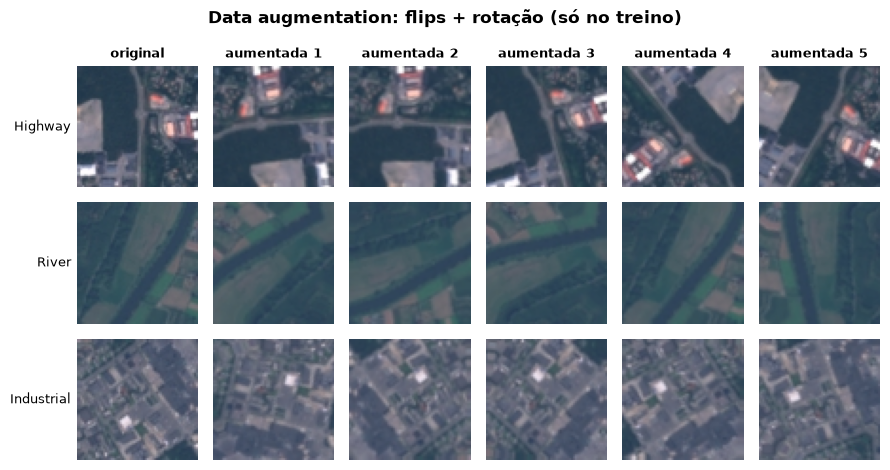

In [14]:
def make_augmentation():
    """Augmentation para cenas de satélite: flip H, flip V e rotação de até ±90° (ativo só no treino)."""
    # Flips em camadas separadas e uma semente diferente por camada: uma única
    # RandomFlip("horizontal_and_vertical") sorteia um só valor para os dois eixos (só gera 2 das
    # 4 orientações), e camadas com a mesma semente sorteiam números iguais, o que correlaciona
    # o flip com o ângulo da rotação. Ambos foram conferidos empiricamente.
    return keras.Sequential([
        layers.RandomFlip("horizontal", seed=SEED),
        layers.RandomFlip("vertical", seed=SEED + 1),
        layers.RandomRotation(0.25, fill_mode="reflect", seed=SEED + 2),  # 0.25 de volta = ±90°
    ], name="augmentation")


# Demonstração: a 1ª imagem de treino de 3 classes com estrutura visível (coluna 1)
# e 5 versões aumentadas de cada uma.
classes_demo = ["Highway", "River", "Industrial"]
indices_demo = [int(np.flatnonzero(y_train == CLASSES.index(c))[0]) for c in classes_demo]
augmentation_demo = make_augmentation()
originais = keras.ops.cast(X_train[indices_demo], "float32")
fig, eixos = plt.subplots(3, 6, figsize=(9, 4.8))
for coluna in range(6):
    lote = originais if coluna == 0 else augmentation_demo(originais, training=True)
    for linha in range(3):
        ax = eixos[linha, coluna]
        ax.imshow(np.clip(keras.ops.convert_to_numpy(lote[linha]), 0, 255).astype("uint8"))
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for borda in ax.spines.values():
            borda.set_visible(False)
    eixos[0, coluna].set_title("original" if coluna == 0 else f"aumentada {coluna}", fontsize=9)
for linha, classe in enumerate(classes_demo):
    eixos[linha, 0].set_ylabel(classe, rotation=0, ha="right", va="center", fontsize=9)
fig.suptitle("Data augmentation: flips + rotação (só no treino)", fontweight="bold")
fig.tight_layout()
plt.show()

# Fora do treino (training=False), as camadas devolvem a imagem intacta.
assert np.allclose(keras.ops.convert_to_numpy(augmentation_demo(originais, training=False)),
                   keras.ops.convert_to_numpy(originais))

### Treino

`train_model` compila o modelo e chama o `fit` com o protocolo comum, medindo o tempo. As escolhas valem para todos os modelos e são as mesmas que o `MLPClassifier` do sklearn usa por padrão (log-loss + `solver="adam"`):
- **Perda: entropia cruzada** (`sparse_categorical_crossentropy`). Com a saída `softmax`, minimizar essa perda é maximizar a verossimilhança das classes corretas. Ela pune fortemente as previsões erradas feitas com confiança e, ao contrário do erro quadrático, mantém gradientes úteis mesmo quando o modelo erra muito. O "sparse" é porque os rótulos são inteiros (0–9), sem one-hot.
- **Otimizador: Adam.** Ajusta o tamanho do passo de cada peso a partir do histórico dos gradientes. Converge em poucas épocas e é pouco sensível à taxa de aprendizado inicial, o que importa num orçamento curto em CPU. O SGD puro exigiria ajustar taxa e momentum.
- **Early stopping** na `val_loss`, restaurando os pesos da melhor época, com a mesma ideia do `n_iter_no_change` do `MLPClassifier`. Monitoramos a `val_loss` e não a `val_accuracy` porque ela reage antes: o modelo começa a ficar confiante demais nos erros antes de a accuracy cair. Desligado só no baseline da MLP.
- **Tempo de treino:** `time.perf_counter()` em volta do `fit`, incluindo o cálculo da validação a cada época.

`epochs` e `patience` são obrigatórios em cada chamada, para que nenhum modelo herde por engano o orçamento de outro. Cada chamada recompila o modelo e zera o otimizador, o que a etapa 2 do TL precisa.

In [15]:
def train_model(model, *, epochs, patience, lr=LR, early_stopping=True):
    """Compila e treina com o protocolo comum. Devolve histórico, tempo e épocas."""
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    callbacks = []
    if early_stopping:
        callbacks.append(keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=patience, restore_best_weights=True))

    inicio = time.perf_counter()
    historico = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs, batch_size=BATCH_SIZE,
        callbacks=callbacks, verbose=2,
    )
    tempo = time.perf_counter() - inicio

    val_loss = historico.history["val_loss"]
    melhor = int(np.argmin(val_loss)) + 1  # épocas contadas a partir de 1
    epocas = len(val_loss)
    # Com ES, o modelo final tem os pesos da melhor época; sem ES, os da última.
    pesos_da_epoca = melhor if early_stopping else epocas
    print(f"→ {epocas} épocas em {tempo:.1f} s · menor val_loss na época {melhor} "
          f"({val_loss[melhor - 1]:.4f}) · pesos finais da época {pesos_da_epoca}")
    return {"historico": historico, "tempo_treino_s": tempo, "epocas": epocas,
            "melhor_epoca": melhor, "pesos_da_epoca": pesos_da_epoca}

### Curvas de treino

`plot_history` desenha, lado a lado, a **loss** e a **accuracy** por época (treino em azul, validação em laranja). A linha verde marca a época cujos pesos o modelo final usa, e a faixa cinza mostra as épocas descartadas pelo early stopping. No Transfer Learning, que treina em duas etapas, as curvas são concatenadas e a troca de etapa aparece como linha pontilhada. A etapa 2 parte dos pesos marcados na etapa 1, não da última época dela.

**Por quê:** é a **learning curve** do deep learning, em função das épocas em vez do tamanho do treino, e é a base do diagnóstico:
- **Overfitting:** a loss de treino continua caindo enquanto a de validação para de cair ou sobe. O vão entre as curvas cresce com as épocas.
- **Underfitting:** o erro é alto **no próprio treino**. A loss de treino estaciona num patamar alto e a accuracy de treino fica longe de 100%, mesmo com épocas sobrando.
- **Leitura das curvas de treino:** a métrica de treino de cada época é a média ao longo da época, calculada com dropout e augmentation ativos quando existirem. A de validação é calculada no fim da época, sem eles. Por isso, em modelos regularizados, a accuracy de treino pode ficar **abaixo** da de validação (e a loss de treino, acima) sem que isso seja um erro.

In [16]:
def plot_history(treinos, titulo):
    """Curvas de loss e accuracy (treino × validação). `treinos`: um retorno de train_model ou uma lista (etapas)."""
    treinos = treinos if isinstance(treinos, list) else [treinos]
    curvas = {chave: sum((t["historico"].history[chave] for t in treinos), [])
              for chave in ["loss", "val_loss", "accuracy", "val_accuracy"]}
    epocas = np.arange(1, len(curvas["loss"]) + 1)

    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4.2))
    for ax, metrica, nome in [(ax_loss, "loss", "Loss"), (ax_acc, "accuracy", "Accuracy")]:
        ax.plot(epocas, curvas[metrica], color=CORES["treino"], label="treino")
        ax.plot(epocas, curvas[f"val_{metrica}"], color=CORES["validacao"], label="validação")
        inicio_etapa, rotulo_descartadas = 0, "épocas descartadas"
        for k, t in enumerate(treinos):
            usada = inicio_etapa + t["pesos_da_epoca"]
            sufixo = f" na etapa {k + 1}" if len(treinos) > 1 else ""
            ax.axvline(usada, color=CORES["destaque"], linestyle="--", linewidth=1.5,
                       label=f"pesos usados{sufixo} (época {usada})")
            fim_etapa = inicio_etapa + t["epocas"]
            if usada < fim_etapa:  # épocas após a melhor, descartadas pelo early stopping
                ax.axvspan(usada + 0.5, fim_etapa + 0.5, color=CORES["neutro"], alpha=0.12,
                           label=rotulo_descartadas)
                rotulo_descartadas = None  # legenda só na primeira faixa cinza desenhada
            if k < len(treinos) - 1:
                ax.axvline(fim_etapa + 0.5, color=CORES["neutro"], linestyle=":", linewidth=1.5,
                           label="troca de etapa")
            inicio_etapa = fim_etapa
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))  # épocas são inteiras
        ax.set_title(nome)
        ax.set_xlabel("Época")
        ax.set_ylabel(nome)
        ax.legend(fontsize=8)
    fig.suptitle(titulo, fontweight="bold")
    fig.tight_layout()
    plt.show()

### Avaliação

`evaluate_model` calcula as métricas na **validação** e no **teste**, mede o custo e grava tudo em `RESULTS`, de onde sai a tabela comparativa da B4. Para o TL, recebe a lista das duas etapas e soma tempo e épocas.

| Métrica | Pergunta que responde | Onde aparece na matriz de confusão |
|---|---|---|
| **Accuracy** | Que fração de todas as imagens o modelo acertou? | soma da diagonal / total (matriz em contagens) |
| **Precision** da classe X | Das imagens que o modelo chamou de X, quantas eram X? | coluna de X (matriz em contagens) |
| **Recall** da classe X | Das imagens que são X, quantas o modelo encontrou? | diagonal da matriz normalizada por linha |
| **F1** da classe X | Equilíbrio entre as duas: média harmônica de precision e recall | — |

- **Macro** = média simples das 10 classes (o `average="macro"` do sklearn). Cada classe pesa igual, então uma classe ruim derruba o **F1-macro**, nossa métrica principal, mesmo que a accuracy continue alta. Com desbalanceamento leve (razão 1,5), accuracy e F1-macro tendem a sair próximas; o valor do F1-macro está em não deixar uma classe ruim escondida na média.
- **Custo:** tempo de inferência (ms por imagem no teste, mediana de 3 medições depois de um aquecimento) e parâmetros totais e treináveis.
- **Por classe:** F1 e matriz de confusão são guardados para os dois conjuntos. Qualquer decisão por classe (por exemplo, usar `class_weight` se a classe menor estiver prejudicada) olha a **validação**. As versões do teste são as reportadas.

In [17]:
RESULTS = {}         # nome do modelo → métricas (uma linha da tabela final)
F1_POR_CLASSE = {}   # nome do modelo → DataFrame com o F1 de cada classe (colunas "val" e "test")
MATRIZES = {}        # nome do modelo → {"val": matriz, "test": matriz}, normalizadas por linha
ROTULOS = np.arange(len(CLASSES))


def evaluate_model(model, nome, treino, relatorio=True):
    """Métricas de validação e teste + custo; grava em RESULTS. `treino`: retorno de train_model ou lista (etapas).
    `relatorio=False` omite o classification_report (usado nas variantes do A6)."""
    treinos = treino if isinstance(treino, list) else [treino]
    model.predict(X_test, batch_size=BATCH_SIZE, verbose=0)  # aquecimento: monta o grafo fora da medição
    tempos = []
    for _ in range(3):  # mediana de 3 medições: menos sensível a ruído do sistema
        inicio = time.perf_counter()
        pred = {"test": model.predict(X_test, batch_size=BATCH_SIZE, verbose=0).argmax(axis=1)}
        tempos.append(time.perf_counter() - inicio)
    pred["val"] = model.predict(X_val, batch_size=BATCH_SIZE, verbose=0).argmax(axis=1)

    linha, f1_classes = {}, {}
    for conjunto, y in [("val", y_val), ("test", y_test)]:
        p, r, f1, _ = precision_recall_fscore_support(y, pred[conjunto], labels=ROTULOS, average="macro", zero_division=0)
        linha |= {f"{conjunto}_accuracy": accuracy_score(y, pred[conjunto]), f"{conjunto}_precision_macro": p,
                  f"{conjunto}_recall_macro": r, f"{conjunto}_f1_macro": f1}
        f1_classes[conjunto] = precision_recall_fscore_support(y, pred[conjunto], labels=ROTULOS, zero_division=0)[2]
    MATRIZES[nome] = {c: confusion_matrix(y, pred[c], labels=ROTULOS, normalize="true")
                      for c, y in [("val", y_val), ("test", y_test)]}
    F1_POR_CLASSE[nome] = pd.DataFrame(f1_classes, index=CLASSES)
    linha |= {
        "tempo_treino_s": sum(t["tempo_treino_s"] for t in treinos),  # TL: etapa 1 + etapa 2
        "tempo_inferencia_ms_por_imagem": 1000 * float(np.median(tempos)) / len(X_test),
        "params_totais": model.count_params(),
        "params_treinaveis": int(sum(np.prod(w.shape) for w in model.trainable_weights)),
        "epocas": sum(t["epocas"] for t in treinos),
        "pesos_da_epoca": sum(t["epocas"] for t in treinos[:-1]) + treinos[-1]["pesos_da_epoca"],
    }
    RESULTS[nome] = linha

    if relatorio:
        print(f"Relatório por classe no TESTE: {nome}\n")
        print(classification_report(y_test, pred["test"], labels=ROTULOS, target_names=CLASSES, digits=3, zero_division=0))
    metricas = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
    return pd.DataFrame({"validação": [linha[f"val_{m}"] for m in metricas],
                         "teste": [linha[f"test_{m}"] for m in metricas]}, index=metricas).round(3)


def tabela_resultados():
    """RESULTS como DataFrame (uma linha por modelo)."""
    return pd.DataFrame.from_dict(RESULTS, orient="index")


def tabelas_comparacao(linhas):
    """Duas tabelas de RESULTS para os modelos pedidos: desempenho (métricas macro, val e teste) e custo."""
    tabela = tabela_resultados().loc[linhas]
    metricas = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
    desempenho = tabela[[f"{c}_{m}" for c in ["val", "test"] for m in metricas]]
    desempenho.columns = pd.MultiIndex.from_product([["validação", "teste"], ["accuracy", "precision", "recall", "F1"]])
    custo = pd.DataFrame({
        "parâmetros": tabela["params_totais"], "treináveis": tabela["params_treinaveis"],
        "épocas rodadas": tabela["epocas"], "pesos da época": tabela["pesos_da_epoca"],
        "tempo de treino (s)": tabela["tempo_treino_s"],
        "tempo por época (s)": tabela["tempo_treino_s"] / tabela["epocas"],
        "inferência (ms/imagem)": tabela["tempo_inferencia_ms_por_imagem"],
    })
    return desempenho.round(3), custo.round(3)


### Matriz de confusão e principais confusões

- `plot_confusion_matrix` desenha a matriz **normalizada por linha** (do teste, por padrão). Cada linha é a classe verdadeira e soma 1, então a diagonal é o **recall** de cada classe e o resto da linha mostra para onde vão os erros.
- `top_confusions` lista os pares (verdadeira → prevista) com maior fração de erro.

**Por quê:** a normalização por linha deixa as classes comparáveis mesmo com tamanhos diferentes (no teste, Pasture tem 148 imagens e as maiores classes têm 222 ou 223). A lista de pares testa a **hipótese do A2**: as confusões principais devem ficar entre as classes agrícolas e entre Highway × River.

In [18]:
NOME_CONJUNTO = {"val": "na validação", "test": "no teste"}


def plot_confusion_matrix(nome, conjunto="test"):
    """Matriz de confusão normalizada por linha (diagonal = recall de cada classe)."""
    matriz = MATRIZES[nome][conjunto]
    fig, ax = plt.subplots(figsize=(8.5, 7))
    imagem = ax.imshow(matriz, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, f"{matriz[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if matriz[i, j] > 0.5 else "black")
    ax.set_xticks(ROTULOS, CLASSES, rotation=45, ha="right")
    ax.set_yticks(ROTULOS, CLASSES)
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe verdadeira")
    ax.set_title(f"Matriz de confusão {NOME_CONJUNTO[conjunto]} (normalizada por linha): {nome}")
    ax.grid(False)
    fig.colorbar(imagem, ax=ax, fraction=0.046, pad=0.04, label="fração da classe verdadeira")
    fig.tight_layout()
    plt.show()


def top_confusions(nome, conjunto="test", k=5):
    """Os k pares (verdadeira → prevista) com maior fração de erro."""
    fora_da_diagonal = MATRIZES[nome][conjunto].copy()
    np.fill_diagonal(fora_da_diagonal, 0)
    maiores = np.argsort(fora_da_diagonal, axis=None)[::-1][:k]
    pares = [np.unravel_index(i, fora_da_diagonal.shape) for i in maiores]
    return pd.DataFrame(
        [(CLASSES[i], CLASSES[j], fora_da_diagonal[i, j]) for i, j in pares],
        columns=["classe verdadeira", "prevista como", "fração da classe verdadeira"],
    ).round(3)

## A5. MLP baseline e métricas

### Arquitetura

| Camada | Saída | Parâmetros | Papel |
|---|---|---|---|
| `Rescaling(1/255)` | 64×64×3 | 0 | normaliza os pixels para [0, 1] |
| `Flatten` | 12.288 | 0 | transforma a imagem num vetor, a "linha de tabela" que a MLP aceita |
| `Dense(256, relu)` | 256 | 3.145.984 | 1ª camada oculta |
| `Dense(128, relu)` | 128 | 32.896 | 2ª camada oculta: combina as features da primeira |
| `Dense(10, softmax)` | 10 | 1.290 | uma probabilidade por classe |

**Justificativa das escolhas:**
- **Duas camadas ocultas, 256 → 128:** o enunciado pede 1 ou 2. Com duas, a segunda pode combinar os padrões detectados pela primeira. Quase todos os ~3,18 milhões de parâmetros estão na primeira camada, porque cada um dos 12.288 pixels se liga a cada um dos 256 neurônios. Com tanta capacidade para 5.000 imagens, **esperávamos overfitting**; as curvas abaixo testam essa expectativa.
- **Ativação ReLU** (`max(0, x)`) nas camadas ocultas: é barata, e não satura para valores positivos, então os gradientes não somem como na sigmoide ou na tanh. É o padrão do `MLPClassifier` e a mesma que a CNN vai usar, o que mantém a comparação limpa.
- **Saída softmax:** transforma os 10 valores da última camada em probabilidades que somam 1. É o par natural da entropia cruzada, a perda justificada na A4, junto com o Adam.
- **Sem regularização e sem early stopping:** nenhum dropout, nenhuma penalidade L2, 40 épocas inteiras. Este é o "antes" do diagnóstico.

A função `construir_mlp` é reaproveitada no A6 para ligar dropout, L2 e augmentation sobre exatamente a mesma arquitetura e a mesma inicialização de pesos.

In [19]:
def construir_mlp(nome, *, dropout=0.0, l2=0.0, augmentation=False):
    """MLP 256 → 128 (ReLU) → 10 (softmax). Os argumentos ligam a regularização do A6."""
    keras.utils.set_random_seed(SEED)  # mesma inicialização de pesos em todas as variantes
    regularizador = keras.regularizers.L2(l2) if l2 > 0 else None
    camadas = [keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))]
    if augmentation:
        camadas.append(make_augmentation())
    camadas += [layers.Rescaling(1 / 255), layers.Flatten()]
    for i, unidades in enumerate([256, 128]):
        camadas.append(layers.Dense(unidades, activation="relu", kernel_regularizer=regularizador))
        if dropout > 0:
            # Semente explícita: o Dropout não consome o gerador global e não altera a inicialização.
            camadas.append(layers.Dropout(dropout, seed=SEED + 10 + i))
    camadas.append(layers.Dense(len(CLASSES), activation="softmax"))
    return keras.Sequential(camadas, name=nome)


mlp_baseline = construir_mlp("mlp_baseline")
mlp_baseline.summary()

Model: "mlp_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     3,145,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,180,170 (12.13 MB)

 Trainable params: 3,180,170 (12.13 MB)

 Non-trainable params: 0 (0.00 B)

### Treino do baseline

**O que:** treinar a MLP por 40 épocas inteiras, **sem early stopping**, com o `train_model` comum (Adam, lr 1e-3, batch 64).
**Por quê:** deixar o treino correr além do ponto ideal mostra nas curvas o comportamento completo do modelo sem nenhuma regularização. Esse é o ponto de partida do diagnóstico (A6). Cada linha abaixo é uma época, com a loss e a accuracy no treino e na validação.

In [20]:
treino_mlp_baseline = train_model(mlp_baseline, epochs=MAX_EPOCHS, patience=PATIENCE, early_stopping=False)

Epoch 1/40


79/79 - 3s - 34ms/step - accuracy: 0.1972 - loss: 2.5477 - val_accuracy: 0.2780 - val_loss: 1.8762


Epoch 2/40


79/79 - 2s - 23ms/step - accuracy: 0.2896 - loss: 1.8628 - val_accuracy: 0.2730 - val_loss: 1.7729


Epoch 3/40


79/79 - 2s - 25ms/step - accuracy: 0.3326 - loss: 1.7779 - val_accuracy: 0.2830 - val_loss: 1.7308


... (71 outputs left out)

79/79 - 2s - 21ms/step - accuracy: 0.5728 - loss: 1.1890 - val_accuracy: 0.4610 - val_loss: 1.6273


Epoch 40/40


79/79 - 2s - 21ms/step - accuracy: 0.5816 - loss: 1.1542 - val_accuracy: 0.4840 - val_loss: 1.5351


→ 40 épocas em 69.4 s · menor val_loss na época 31 (1.4646) · pesos finais da época 40


### Curvas de treino × validação

**O que:** a loss e a accuracy por época no treino e na validação.
**Por quê:** é a evidência para diagnosticar overfitting ou underfitting (critérios na A4).

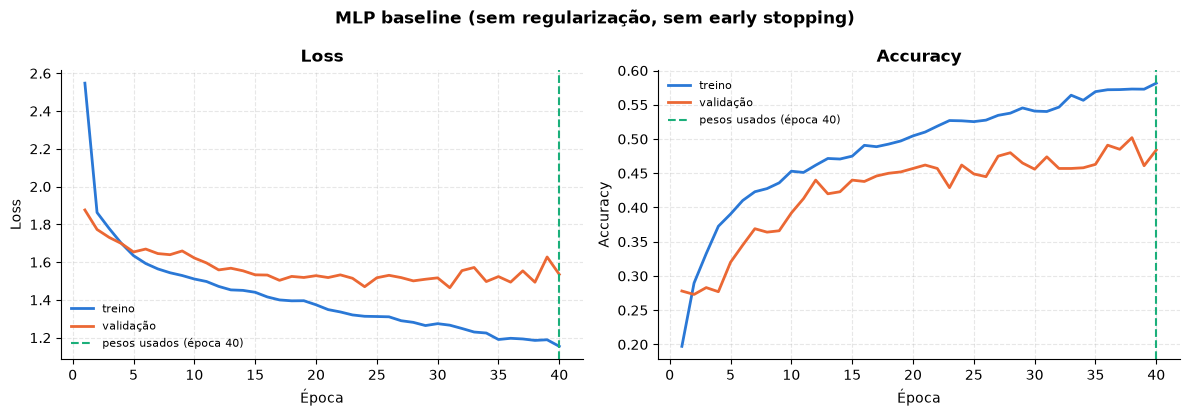

In [21]:
plot_history(treino_mlp_baseline, "MLP baseline (sem regularização, sem early stopping)")

**Médias por janela de 10 épocas.** A validação oscila bastante de uma época para a outra, então o diagnóstico usa médias por janela, e não um ponto isolado. O "vão" é a accuracy de treino menos a de validação, em pontos percentuais.

In [22]:
curvas_baseline = pd.DataFrame(treino_mlp_baseline["historico"].history)
curvas_baseline.index = curvas_baseline.index + 1  # épocas contadas a partir de 1
janelas = np.array_split(curvas_baseline.index, min(4, len(curvas_baseline)))

pd.DataFrame([{
    "épocas": f"{j[0]}–{j[-1]}",
    "accuracy treino": curvas_baseline.loc[j, "accuracy"].mean(),
    "accuracy validação": curvas_baseline.loc[j, "val_accuracy"].mean(),
    "vão (pontos)": 100 * (curvas_baseline.loc[j, "accuracy"] - curvas_baseline.loc[j, "val_accuracy"]).mean(),
    "loss treino": curvas_baseline.loc[j, "loss"].mean(),
    "loss validação": curvas_baseline.loc[j, "val_loss"].mean(),
} for j in janelas]).set_index("épocas").round(3)

,accuracy treino,accuracy validação,vão (pontos),loss treino,loss validação
épocas,,,,,
1–10,0.373,0.327,4.652,1.726,1.697
11–20,0.480,0.438,4.254,1.429,1.542
21–30,0.529,0.458,7.142,1.305,1.513
31–40,0.565,0.473,9.162,1.208,1.532


**Interpretação das curvas: previsto × observado.** Esperávamos overfitting (muita capacidade para poucas imagens). O que as curvas mostram é outra coisa:

- **Underfitting predominante.** Mesmo com 3,18 milhões de parâmetros, a MLP não chega a ajustar o próprio treino no orçamento de 40 épocas. Nas épocas 31–40, a accuracy de treino fica em **~0,56** e a loss de treino em **~1,21**, em média. A loss de treino ainda cai, mas devagar: de 1,27 na época 31 para 1,15 na 40. Para comparação, chutar sempre a classe maior acertaria 11%.
- **Sinal moderado de overfitting no fim.** Até a época 20, o vão entre treino e validação fica estável em ~4,3–4,7 pontos. Depois cresce para 7,1 (épocas 21–30) e 9,2 pontos (31–40), porque o treino melhora 3,6 pontos (0,529 → 0,565) enquanto a validação sobe só 1,5 (0,458 → 0,473) e a `val_loss` média para de cair (1,51 → 1,53). A menor `val_loss` (1,465) acontece na época 31 e a maior `val_accuracy` (0,502) na 38. A época 40, usada pelo baseline, não é a melhor.
- **Validação instável.** A accuracy de validação salta até ~4 pontos entre épocas seguidas (0,502 → 0,461, épocas 38 → 39), e a `val_loss` vai de 1,49 a 1,63 no mesmo passo. Como o conjunto de validação é sempre o mesmo, isso não é ruído de amostragem (o erro-padrão seria ~1,6 ponto com 1.000 imagens): são os **pesos** que oscilam de uma época para a outra, um sinal de otimização instável com taxa de aprendizado 1e-3 sobre 12.288 entradas.

**Por que a MLP não ajusta nem o treino:** depois do `Flatten`, cada pixel em cada posição tem um peso próprio, e a rede não tem nenhuma noção de que pixels vizinhos formam uma estrada ou um talhão. Ela não reaproveita o mesmo detector em posições diferentes. Por isso precisa aprender cada combinação de cor × posição separadamente, e a otimização encontra só padrões globais de **cor**, que separam mal as classes (veja a matriz de confusão abaixo).

**Implicação para o A6:**
- O early stopping deve ajudar, porque escolhe a melhor época em vez da última.
- Dropout e L2 combatem overfitting, que aqui é pequeno, e podem **piorar** um ajuste que já é fraco.
- A comparação "antes × depois" vai mostrar quanto cada técnica realmente vale neste cenário.

### Métricas

**O que:** accuracy, precision, recall e F1 (macro) na validação e no teste, e o relatório por classe do teste (`evaluate_model`, A4). O modelo avaliado é o da **última época** (40), já que não houve early stopping.
**Por quê:** é a medida do baseline que as próximas variantes e modelos precisam superar. As métricas por classe mostram quais classes a MLP acerta e quais erra.

In [23]:
evaluate_model(mlp_baseline, "MLP baseline", treino_mlp_baseline)

Relatório por classe no TESTE: MLP baseline

                      precision    recall  f1-score   support

          AnnualCrop      0.450     0.568     0.502       222
              Forest      0.826     0.536     0.650       222
HerbaceousVegetation      0.384     0.329     0.354       222
             Highway      0.226     0.232     0.229       185
          Industrial      0.786     0.616     0.691       185
             Pasture      0.492     0.608     0.544       148
       PermanentCrop      0.408     0.263     0.320       186
         Residential      0.430     0.413     0.421       223
               River      0.405     0.643     0.497       185
             SeaLake      0.537     0.581     0.558       222

            accuracy                          0.477      2000
           macro avg      0.495     0.479     0.477      2000
        weighted avg      0.497     0.477     0.477      2000



,validação,teste
accuracy,0.484,0.477
precision_macro,0.498,0.495
recall_macro,0.482,0.479
f1_macro,0.482,0.477


**Interpretação das métricas:**
- **Desempenho geral:** F1-macro de **0,482 na validação e 0,477 no teste**. A MLP erra cerca de metade das imagens, e validação e teste concordam: a diferença de 0,5 ponto está bem dentro do ruído esperado para 1.000 e 2.000 imagens (A3).
- **Accuracy × F1-macro:** os dois coincidem no teste (0,477 × 0,477), como previsto para um desbalanceamento leve. Aqui a accuracy não esconde nada **na média**; o que ela esconde está **dentro** das classes.
- **Precision × recall por classe** mostra dois comportamentos opostos:
  - **Industrial** tem precision 0,786 e recall 0,616. Quando a MLP diz "Industrial", quase sempre acerta, mas deixa escapar 38% das áreas industriais. É uma classe "conservadora".
  - **River** tem o contrário: recall 0,643 e precision 0,405. A MLP acha a maior parte dos rios, mas ~60% do que ela chama de River é outra coisa. River funciona como um "ímã" de erros.
- **Pior classe:** Highway, com F1 de 0,229 no teste. A matriz abaixo mostra por quê.

### Matriz de confusão e principais confusões

**O que:** a matriz de confusão do teste, normalizada por linha, e os 5 pares de classes mais confundidos.
**Por quê:** mostra **para onde** vão os erros, coisa que nenhuma métrica agregada mostra. É aqui que conferimos a hipótese do A2: confusões entre as classes agrícolas e entre Highway × River.

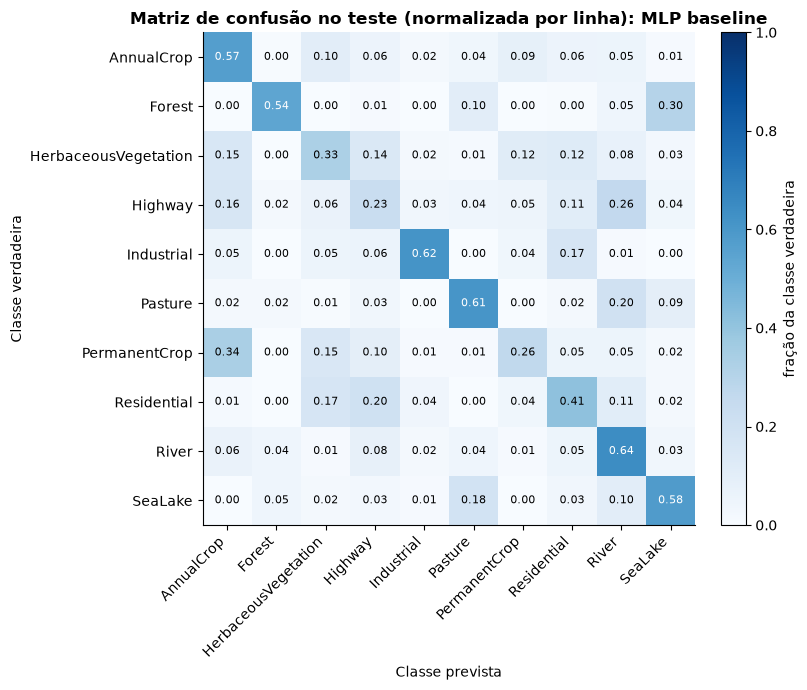

,classe verdadeira,prevista como,fração da classe verdadeira
0,PermanentCrop,AnnualCrop,0.339
1,Forest,SeaLake,0.302
2,Highway,River,0.259
3,Residential,Highway,0.202
4,Pasture,River,0.196


In [24]:
plot_confusion_matrix("MLP baseline")
top_confusions("MLP baseline")

**Conferência da hipótese do A2.** A tabela abaixo lê da matriz do teste a fração de erro de cada par, nos dois sentidos, separando os pares que o A2 previu por **forma/textura** dos pares com **cor média** parecida (também do A2).

In [25]:
pares_a2 = {
    "forma/textura (hipótese do A2)": [
        ("AnnualCrop", "PermanentCrop"), ("PermanentCrop", "HerbaceousVegetation"),
        ("AnnualCrop", "Pasture"), ("Pasture", "HerbaceousVegetation"), ("Highway", "River"),
    ],
    "cor média próxima (tabela RGB do A2)": [
        ("Residential", "HerbaceousVegetation"), ("Residential", "Highway"),
        ("HerbaceousVegetation", "Highway"), ("SeaLake", "Pasture"),
        ("SeaLake", "Forest"), ("Forest", "Pasture"), ("River", "Pasture"),
    ],
}
matriz_teste = MATRIZES["MLP baseline"]["test"]
posicao = {classe: i for i, classe in enumerate(CLASSES)}
pd.DataFrame([
    {"grupo": grupo, "par (A × B)": f"{a} × {b}",
     "A → B": matriz_teste[posicao[a], posicao[b]], "B → A": matriz_teste[posicao[b], posicao[a]]}
    for grupo, pares in pares_a2.items() for a, b in pares
]).set_index(["grupo", "par (A × B)"]).round(3)

A → B  \
grupo                                par (A × B)                                   
forma/textura (hipótese do A2)       AnnualCrop × PermanentCrop            0.086   
                                     PermanentCrop × HerbaceousVegetation  0.151   
                                     AnnualCrop × Pasture                  0.036   
                                     Pasture × HerbaceousVegetation        0.007   
                                     Highway × River                       0.259   
cor média próxima (tabela RGB do A2) Residential × HerbaceousVegetation    0.166   
                                     Residential × Highway                 0.202   
                                     HerbaceousVegetation × Highway        0.144   
                                     SeaLake × Pasture                     0.185   
                                     SeaLake × Forest                      0.045   
                                     Forest × Pasture                      0.104   
                                     River × Pasture                       0.043   

                                                                           B → A  
grupo                                par (A × B)                                  
forma/textura (hipótese do A2)       AnnualCrop × PermanentCrop            0.339  
                                     PermanentCrop × HerbaceousVegetation  0.117  
                                     AnnualCrop × Pasture                  0.020  
                                     Pasture × HerbaceousVegetation        0.014  
                                     Highway × River                       0.081  
cor média próxima (tabela RGB do A2) Residential × HerbaceousVegetation    0.122  
                                     Residential × Highway                 0.108  
                                     HerbaceousVegetation × Highway        0.065  
                                     SeaLake × Pasture                     0.095  
                                     SeaLake × Forest                      0.302  
                                     Forest × Pasture                      0.020  
                                     River × Pasture                       0.196

**Interpretação: a hipótese do A2, previsto × observado**

| Hipótese do A2 (forma/textura) | Observado no teste | Veredito |
|---|---|---|
| Confusão entre as classes agrícolas | PermanentCrop → AnnualCrop 0,34, a maior confusão da matriz; PermanentCrop → HerbaceousVegetation 0,15; HerbaceousVegetation → PermanentCrop 0,12. Mas Pasture quase não se mistura com as lavouras (0,01–0,04) | ✔ parcial |
| Highway × River | Highway → River 0,26; River → Highway 0,08 | ✔ confirmada |

As outras grandes confusões, porém, são pares de **cor média próxima**, que o A2 tinha apontado na tabela de RGB e não como hipótese de forma. Mesmo a maior de todas, PermanentCrop → AnnualCrop, é também um par de cor quase igual (130/120/117 × 122/116/114 no A2):
- **Verdes e azuis escuros:** Forest → SeaLake (0,30), Pasture → River (0,20), SeaLake → Pasture (0,19) e Forest → Pasture (0,10). Forest, SeaLake, Pasture e River são as quatro classes de cor média mais escura no A2.
- **Cinzas urbanos:** Residential → Highway (0,20) e → HerbaceousVegetation (0,17); HerbaceousVegetation → Highway (0,14). No A2, essas três classes tinham R entre 88 e 100.
- **River como destino:** River recebe erros de Highway (0,26) e de Pasture (0,20) e é prevista bem mais vezes do que existe (precision 0,41). É o palpite da MLP para cenas escuras e azuladas.

**Uma previsão do A2 que falhou:** esperávamos que Forest e SeaLake fossem fáceis pela homogeneidade. Para a MLP, as duas ficam com recall de só 0,54 e 0,58: floresta escura é confundida com água escura (Forest → SeaLake 0,30), e água com pastagem.

**Conclusão:** os erros são consistentes com uma classificação **guiada pela cor**, e não pela forma ou pela textura. É exatamente a limitação esperada de um modelo que não enxerga vizinhança entre pixels. A hipótese fica para ser testada na B1: se a CNN, que enxerga textura e forma, reduzir justamente essas confusões, a explicação se confirma.

### Diagnóstico de desbalanceamento (na validação)

**O que:** para cada classe, o tamanho no treino e na validação, quantas vezes ela foi **prevista** na validação, o recall e o F1 na validação, ordenados pelo F1.
**Por quê:** o protocolo só aplica `class_weight` se a classe menor (Pasture, 370 imagens de treino) estiver prejudicada **por ser pequena**. Essa decisão usa só a validação. A pergunta é: as piores classes são as menores, ou são as visualmente difíceis?

In [26]:
matriz_val = MATRIZES["MLP baseline"]["val"]
imagens_val = np.bincount(y_val, minlength=len(CLASSES))
diagnostico_classes = pd.DataFrame({
    "imagens no treino": np.bincount(y_train, minlength=len(CLASSES)),
    "imagens na validação": imagens_val,
    # Matriz normalizada × tamanho de cada classe = quantas vezes cada classe foi prevista.
    "previstas na validação": np.rint(matriz_val.T @ imagens_val).astype(int),
    "recall na validação": np.diag(matriz_val),
    "F1 na validação": F1_POR_CLASSE["MLP baseline"]["val"].to_numpy(),
}, index=CLASSES).sort_values("F1 na validação")
diagnostico_classes.round(3)

,imagens no treino,imagens na validação,previstas na validação,recall na validação,F1 na validação
Highway,463,93,88,0.183,0.188
HerbaceousVegetation,555,111,114,0.378,0.373
PermanentCrop,463,92,59,0.326,0.397
Residential,555,111,97,0.387,0.413
River,463,93,143,0.591,0.466
Pasture,370,74,93,0.541,0.479
AnnualCrop,556,111,139,0.631,0.560
SeaLake,556,111,108,0.604,0.612
Forest,556,111,93,0.586,0.637
Industrial,463,93,66,0.591,0.692


**Interpretação: não há sinal de prejuízo por desbalanceamento** (só números da validação)
- A classe menor, **Pasture** (370 imagens de treino, 74 na validação), está no **meio** do ranking de F1 (0,479), à frente de cinco classes maiores, com recall de 0,541.
- A MLP previu Pasture **93 vezes** para 74 imagens reais. O problema dela não é falta de previsões. Quem é prevista em excesso é River (143 previsões para 93 imagens), uma classe de tamanho médio.
- As piores classes são Highway (0,188), HerbaceousVegetation (0,373) e PermanentCrop (0,397), com 463, 555 e 463 imagens de treino. O que as prejudica é a semelhança visual, não o tamanho.
- **Decisão:** não aplicar `class_weight` nem reamostragem. A classe menor não está prejudicada, e dar mais peso a ela aumentaria um excesso de previsões que já existe.

### Resumo da A5

| Item | Resultado |
|---|---|
| Arquitetura | 12.288 → 256 → 128 → 10, ReLU + softmax, **3.180.170 parâmetros** |
| Treino | 40 épocas sem early stopping, ~70 s em CPU |
| F1-macro | 0,482 (validação) · 0,477 (teste) |
| Diagnóstico (previsto × observado) | esperado: overfitting · observado: **underfitting predominante** (treino ~56%), overfitting moderado após a época ~30 e validação instável |
| Erros | consistentes com classificação guiada pela cor: verdes e azuis escuros, cinzas urbanos, River como destino |
| Desbalanceamento | não prejudica a classe menor (Pasture é prevista até um pouco mais do que existe); sem `class_weight` |

O A6 parte desse diagnóstico para escolher e comparar as técnicas de regularização.

## A6. Diagnóstico de overfitting e regularização

### Ponto de partida: o diagnóstico da A5

| Sinal nas curvas do baseline | Leitura |
|---|---|
| Accuracy de treino de só ~0,56 nas épocas 31–40, com a loss de treino estacionada em ~1,21 | **underfitting predominante** (alto viés) |
| Vão treino × validação: ~4,3–4,7 pontos até a época 20 e 9,2 nas épocas 31–40 | **overfitting moderado** no fim do treino |
| Menor `val_loss` na época 31, mas o baseline usa os pesos da época 40 | o modelo final não é o melhor que o treino produziu |

### O que vamos testar

As quatro variantes usam a **mesma arquitetura e os mesmos pesos iniciais** do baseline (`construir_mlp`) e diferem só na técnica ligada. Assim cada linha da comparação isola um efeito. Dropout e L2 ficam em variantes separadas, e não numa só, justamente para que o efeito de cada um apareça sozinho.

| Variante | Early stopping | Dropout | L2 | Augmentation | O que mede |
|---|---|---|---|---|---|
| MLP baseline (A5) | — | — | — | — | o "antes" |
| **MLP + ES** | ✔ | — | — | — | o ganho de parar na melhor época |
| **MLP + ES + dropout** | ✔ | 0,3 | — | — | o efeito do dropout, somado ao ES |
| **MLP + ES + L2** | ✔ | — | 1e-4 | — | o efeito do L2, somado ao ES |
| **MLP + ES + augmentation** | ✔ | — | — | ✔ | o efeito do augmentation, somado ao ES |

**Como cada técnica age:**
- **Early stopping:** interrompe o treino quando a `val_loss` para de melhorar e devolve os pesos da melhor época. Limita a complexidade efetiva do modelo, como limitar `n_estimators` num boosting.
- **Dropout:** em cada passo de treino, desliga aleatoriamente 30% dos neurônios de cada camada oculta. A rede não pode depender de nenhum neurônio específico, o que lembra um ensemble de sub-redes (como o *bagging*).
- **L2:** soma à perda uma penalidade proporcional ao quadrado dos pesos das camadas ocultas, empurrando-os para valores pequenos. É o mesmo princípio do `alpha` do `MLPClassifier` e da regressão Ridge.
- **Data augmentation:** flips e rotações aleatórios das imagens de treino (A4). Aumenta a variedade dos dados em vez de restringir o modelo.

**O que esperamos (previsto):** com underfitting dominante, o **early stopping** deve ajudar, por escolher uma época melhor que a 40. **Dropout e L2** atacam o overfitting, que aqui é pequeno, e podem **piorar** um ajuste que já é fraco. O **augmentation** obriga a MLP a reconhecer cada classe em posições e orientações novas, justamente o que ela faz mal (A5); pode dificultar ainda mais o ajuste.

**Como comparar:** pelo **F1-macro na validação**, e não pela loss. A tabela mostra a diferença em relação ao baseline (antes × depois) e em relação à MLP + ES (o efeito da técnica além do early stopping). Com L2, a loss do Keras inclui a penalidade dos pesos, então a loss de modelos com e sem L2 não é comparável. A melhor variante pela validação é a MLP que vai para a comparação final (B4).


### Treino das variantes

**O que:** treinar as quatro variantes com o mesmo `train_model` do baseline (Adam, lr 1e-3, batch 64, até 40 épocas), agora **com early stopping** (paciência 8 na `val_loss`).
**Por quê:** a única diferença entre as variantes e o baseline são as técnicas da tabela acima. Qualquer mudança no desempenho vem delas.


In [27]:
VARIANTES_MLP = {
    "MLP + ES": {},
    "MLP + ES + dropout": {"dropout": DROPOUT_MLP},
    "MLP + ES + L2": {"l2": L2_MLP},
    "MLP + ES + augmentation": {"augmentation": True},
}

modelos_mlp, treinos_mlp = {}, {}
for nome, opcoes in VARIANTES_MLP.items():
    print(f"\n===== {nome} =====")
    modelos_mlp[nome] = construir_mlp(nome.lower().replace(" + ", "_").replace(" ", "_"), **opcoes)
    treinos_mlp[nome] = train_model(modelos_mlp[nome], epochs=MAX_EPOCHS, patience=PATIENCE)



===== MLP + ES =====
Epoch 1/40


79/79 - 2s - 31ms/step - accuracy: 0.1972 - loss: 2.5477 - val_accuracy: 0.2780 - val_loss: 1.8762


Epoch 2/40


79/79 - 2s - 21ms/step - accuracy: 0.2896 - loss: 1.8628 - val_accuracy: 0.2730 - val_loss: 1.7729


Epoch 3/40


79/79 - 2s - 21ms/step - accuracy: 0.3326 - loss: 1.7779 - val_accuracy: 0.2830 - val_loss: 1.7308


... (309 outputs left out)

79/79 - 2s - 25ms/step - accuracy: 0.5006 - loss: 1.3627 - val_accuracy: 0.5290 - val_loss: 1.3343


Epoch 40/40


79/79 - 2s - 25ms/step - accuracy: 0.5012 - loss: 1.3754 - val_accuracy: 0.5360 - val_loss: 1.3379


→ 40 épocas em 80.7 s · menor val_loss na época 39 (1.3343) · pesos finais da época 39


### Curvas das variantes

**O que:** as curvas de treino × validação de cada variante, no mesmo formato do baseline. A linha verde marca a época restaurada pelo early stopping e a faixa cinza as épocas descartadas.
**Leitura:** com dropout ou augmentation, a accuracy de **treino** é medida com a regularização ativa e a de validação sem ela, então o treino pode aparecer **abaixo** da validação (A4). Com L2, a loss inclui um termo pequeno de penalidade dos pesos: por isso ela não é comparável à dos outros modelos, e o early stopping dessa variante monitora esse critério um pouco diferente.


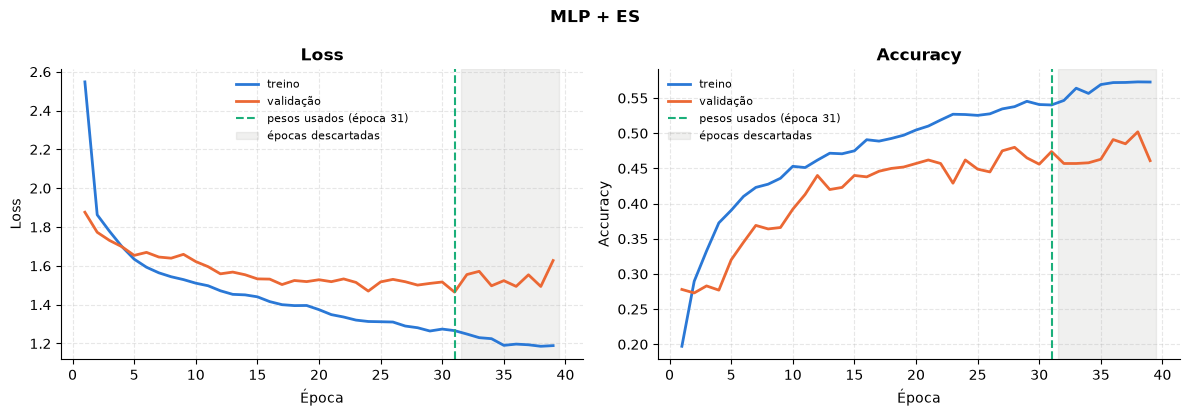

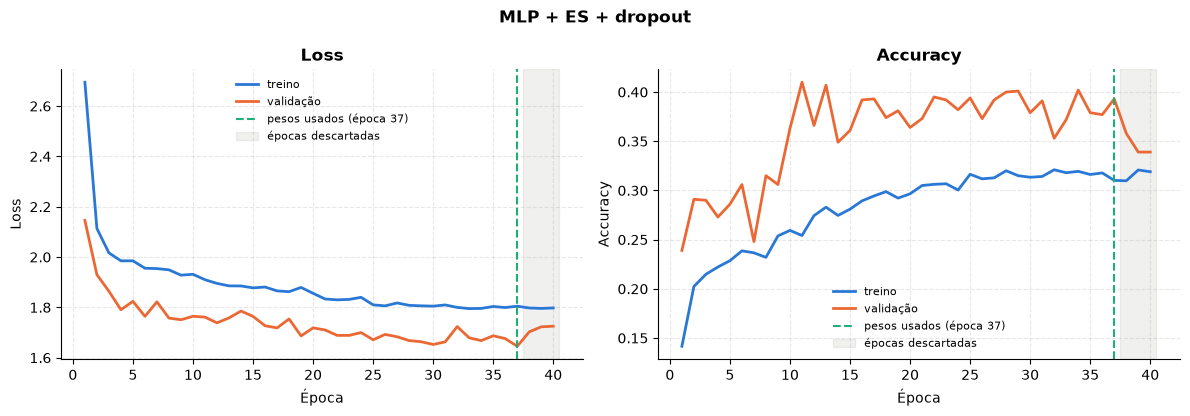

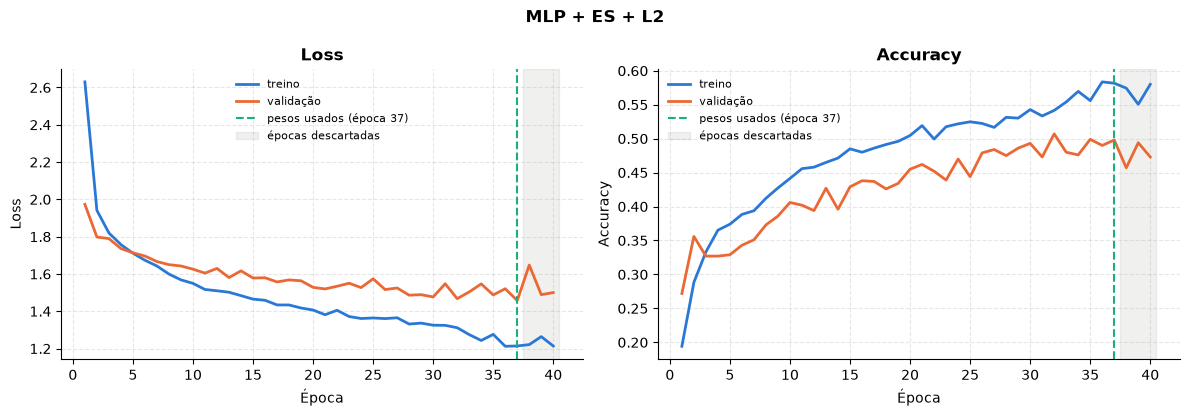

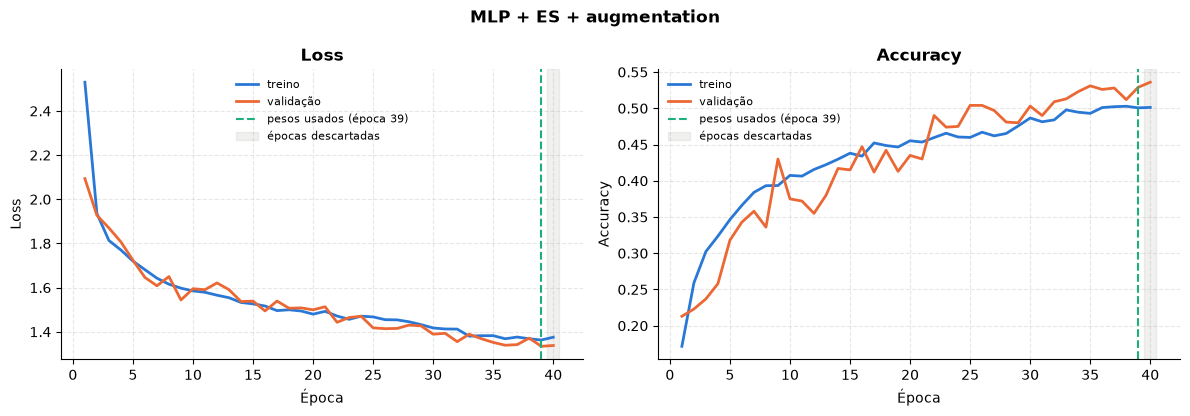

In [28]:
for nome, treino in treinos_mlp.items():
    plot_history(treino, nome)


**Interpretação das curvas:**
- **MLP + ES:** começa dos mesmos pesos e treina com os mesmos lotes do baseline, então percorre **exatamente a mesma trajetória**. O early stopping para na época 39 (8 épocas sem melhora depois da 31) e restaura os pesos da época 31, a de menor `val_loss`. A única mudança em relação ao baseline é a época escolhida.
- **MLP + ES + dropout:** o ajuste piora muito. Nas últimas épocas, a accuracy de treino fica em ~0,31 e a de validação em ~0,37–0,39, contra ~0,56 e ~0,48 no baseline. O treino aparece **abaixo** da validação porque é medido com o dropout ligado (A4). O que importa é que as duas curvas ficaram muito mais baixas. Esta variante também usou as 40 épocas (melhor época: 37) e a `val_loss` ainda caía devagar, então parte da diferença pode ser convergência mais lenta; o patamar, porém, está longe do baseline.
- **MLP + ES + L2:** curvas parecidas com as do baseline, com a mesma validação instável. A melhor época é a 37, e no fim o vão de accuracy entre treino e validação chega a ~9 pontos (~0,57 × ~0,48 nas últimas 5 épocas), o mesmo sinal de overfitting moderado da A5.
- **MLP + ES + augmentation:** as curvas de treino e validação ficam próximas, e a `val_loss` ainda caía nas últimas épocas (melhor época: 39 de 40). **Não há sinal de overfitting dentro do orçamento de 40 épocas**, e é o orçamento que limita este modelo. Ele continua com underfitting (accuracy de treino ~0,50, medida nas imagens aumentadas).


### Antes × depois

**O que:** as métricas das quatro MLPs lado a lado, e a escolha da MLP que vai para a comparação final.
**Por quê:** é a comparação que o enunciado pede. A escolha usa **só o F1-macro da validação**; a coluna do teste aparece apenas para registro e não influencia a decisão.


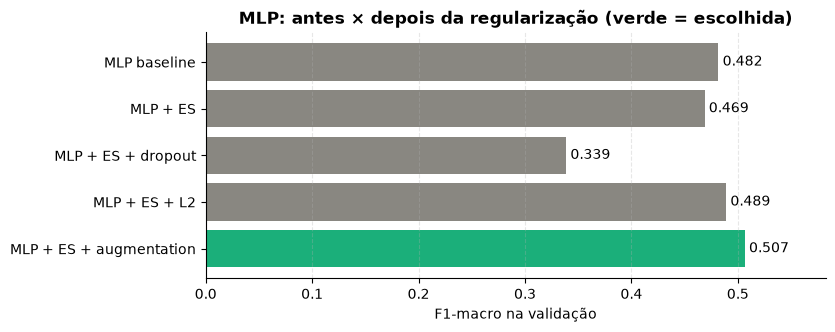

MLP escolhida para a comparação final (maior F1-macro na validação): MLP + ES + augmentation


,accuracy val,F1-macro val,F1-macro teste (só registro),épocas rodadas,pesos da época,tempo de treino (s),Δ F1 val × baseline,Δ F1 val × MLP + ES
MLP baseline,0.484,0.482,0.477,40,40,69.368,0.000,0.013
MLP + ES,0.474,0.469,0.479,39,31,66.303,-0.013,0.000
MLP + ES + dropout,0.393,0.339,0.340,40,37,70.285,-0.143,-0.130
MLP + ES + L2,0.498,0.489,0.496,40,37,90.518,0.007,0.020
MLP + ES + augmentation,0.529,0.507,0.498,40,39,80.660,0.025,0.038


In [29]:
for nome, modelo in modelos_mlp.items():
    evaluate_model(modelo, nome, treinos_mlp[nome], relatorio=False)

NOMES_MLP = ["MLP baseline", *VARIANTES_MLP]
comparacao_mlp = tabela_resultados().loc[NOMES_MLP, ["val_accuracy", "val_f1_macro", "test_f1_macro",
                                                     "epocas", "pesos_da_epoca", "tempo_treino_s"]]
f1_val = comparacao_mlp["val_f1_macro"]
comparacao_mlp["Δ F1 val × baseline"] = f1_val - f1_val["MLP baseline"]
comparacao_mlp["Δ F1 val × MLP + ES"] = f1_val - f1_val["MLP + ES"]  # efeito adicional da técnica
# Escolha só pela validação e só entre as variantes com early stopping (o baseline é o "antes").
MELHOR_MLP = f1_val[list(VARIANTES_MLP)].idxmax()

fig, ax = plt.subplots(figsize=(8, 3.2))
barras = ax.barh(NOMES_MLP[::-1], f1_val[NOMES_MLP[::-1]],
                 color=[CORES["destaque"] if n == MELHOR_MLP else CORES["neutro"] for n in NOMES_MLP[::-1]])
ax.bar_label(barras, fmt="%.3f", padding=3)
ax.set_xlim(0, f1_val.max() * 1.15)
ax.set_xlabel("F1-macro na validação")
ax.set_title("MLP: antes × depois da regularização (verde = escolhida)")
ax.grid(axis="y", visible=False)
plt.show()

print(f"MLP escolhida para a comparação final (maior F1-macro na validação): {MELHOR_MLP}")
comparacao_mlp.rename(columns={
    "val_accuracy": "accuracy val", "val_f1_macro": "F1-macro val", "test_f1_macro": "F1-macro teste (só registro)",
    "epocas": "épocas rodadas", "pesos_da_epoca": "pesos da época", "tempo_treino_s": "tempo de treino (s)",
}).round(3)


**Interpretação: previsto × observado**

| Técnica | Previsto | Observado (F1-macro na validação) |
|---|---|---|
| Early stopping | ajudar, ao escolher uma época melhor que a 40 | **≈ 0 a levemente negativo** (0,469 × 0,482): a época de menor `val_loss` (31) não é a de melhor F1. Nem o tempo melhora: o treino só parou na época 39 |
| Dropout | pode piorar um modelo com underfitting | **piorou muito**: 0,339 (−0,143 sobre o baseline) |
| L2 | pode piorar | **≈ neutro**: 0,489 (+0,007), dentro do ruído |
| Augmentation | pode dificultar o ajuste | **≈ neutro a levemente positivo**: 0,507 (+0,025) de F1, com accuracy de validação de 0,529 (+4,5 pontos) e a menor `val_loss` de todas (1,334, contra 1,465 da MLP + ES; as duas são comparáveis porque nenhuma tem L2) |

- **Só o dropout teve efeito claro.** A queda de 0,143 é cerca de 9 vezes o erro-padrão da métrica (~1,6 ponto com 1.000 imagens, A3). O dropout injeta ruído nas ativações durante o treino, o que reduz a capacidade efetiva; num modelo que já não ajusta o treino, isso só piora.
- **L2 e augmentation ficaram dentro do ruído.** +0,007 e +0,025 de F1 são da ordem do erro-padrão, e a própria validação da MLP oscila até ~4 pontos entre épocas seguidas (A5). Os indícios a favor do augmentation (accuracy +4,5 pontos e `val_loss` menor) são consistentes, mas modestos.
- **No teste, só para registro:** a ordem se repete. Augmentation e L2 ficam em 0,498 e 0,496, contra 0,479 da MLP + ES e 0,477 do baseline. São ~2 pontos, no nível do ruído do teste (~1,1 ponto, A3): consistentes, mas modestos. Todas as variantes, exceto a com dropout, ficam entre 0,477 e 0,498.
- **Escolha para a B4:** pelo protocolo, a de maior F1 na validação, **MLP + ES + augmentation**. Ela fica 0,018 à frente da de L2, também dentro do ruído; se uma reexecução inverter a ordem, a conclusão não muda.
- **Conclusão do diagnóstico:** regularização combate overfitting, e o problema principal desta MLP não é overfitting. Dentro do orçamento de 40 épocas, nenhuma técnica tirou a MLP do patamar de ~0,5 de F1, que vem da forma como ela enxerga a imagem.


### Limitações da MLP para este problema

| Limitação | Evidência no notebook |
|---|---|
| **Joga fora a estrutura espacial.** O `Flatten` transforma a imagem em 12.288 números independentes; a MLP não sabe que pixels vizinhos formam uma estrada ou um talhão | Erros guiados pela cor média: cinzas urbanos se confundem entre si e as classes escuras se misturam (Forest → SeaLake, SeaLake → Pasture, Pasture → River) (A5) |
| **Underfitting apesar de muitos parâmetros.** O problema não é falta de capacidade, é a representação | 3,18 milhões de parâmetros e só ~56% de accuracy no próprio treino (A5) |
| **Regularização não resolve** (no orçamento de 40 épocas) | Nenhuma técnica mudou o patamar de ~0,5 de F1; o dropout piorou 0,143 (A6) |
| **Sem invariância à posição.** A mesma estrutura em outro lugar da imagem é outra entrada para a MLP | Hipótese consistente com os erros da A5, a testar na B1: uma CNN, que reconhece o mesmo padrão em qualquer posição, deveria reduzir justamente essas confusões |
| **Custo preso à resolução.** 98,9% dos parâmetros estão na 1ª camada (3.145.984 de 3.180.170), um peso por pixel × neurônio | Com imagens de 128×128, só essa camada teria 4× mais parâmetros |

Essas limitações definem o que a **CNN (B1)** precisa resolver: enxergar vizinhança (filtros locais), reconhecer o mesmo padrão em qualquer posição (pesos compartilhados) e fazer isso com muito menos parâmetros.

### Resumo da A6

| Item | Resultado |
|---|---|
| Diagnóstico (A5) | underfitting predominante + overfitting moderado no fim |
| Técnicas aplicadas | early stopping, dropout 0,3, L2 1e-4 e data augmentation, cada uma isolada |
| Efeito claro | só o dropout, negativo: F1-macro 0,339 (−0,143) |
| Efeito dentro do ruído | ES (−0,013), L2 (+0,007) e augmentation (+0,025) |
| MLP na comparação final (B4) | **MLP + ES + augmentation** (maior F1 na validação, 0,507, contra 0,489 da L2) |


# PARTE B — CNN e Transfer Learning

## B1. CNN própria (do zero)

### O que a convolução muda em relação à MLP

A A6 terminou com as limitações da MLP: ela joga fora a vizinhança entre pixels, não reconhece o mesmo padrão em outra posição e gasta 99% dos parâmetros ligando cada pixel a cada neurônio. Uma **rede convolucional (CNN)** ataca exatamente esses três pontos:

| Ideia | Como funciona | Limitação da MLP que resolve |
|---|---|---|
| **Filtros locais** | Cada filtro 3×3 olha só uma vizinhança de 3×3 pixels e responde a um padrão (borda, linha, textura) | enxerga vizinhança, em vez de pixels soltos |
| **Pesos compartilhados** | O mesmo filtro desliza pela imagem inteira: uma rodovia é detectada em qualquer posição | invariância à posição |
| **Pooling** | `MaxPooling 2×2` reduz a resolução pela metade a cada bloco; as camadas seguintes enxergam regiões cada vez maiores | combina padrões locais em estruturas maiores (talhões, rios) |
| **Global Average Pooling** | No fim, tira a média de cada mapa de características, gerando 1 número por filtro | substitui o `Flatten` gigante: nenhum peso por posição |

**Analogia com o tabular:** os filtros são uma **engenharia de features aprendida**. Em vez de você calcular à mão "textura", "presença de linhas" ou "variação de cor local" e passar para um Random Forest, a CNN aprende esses descritores direto dos pixels, e a parte densa do fim faz o papel do classificador.

### Arquitetura

| Bloco | Camadas | Saída | Parâmetros |
|---|---|---|---|
| Entrada | `Rescaling(1/255)` | 64×64×3 | 0 |
| 1 | `Conv2D(32, 3×3, relu)` → `MaxPool(2×2)` | 32×32×32 | 896 |
| 2 | `Conv2D(64, 3×3, relu)` → `MaxPool(2×2)` | 16×16×64 | 18.496 |
| 3 | `Conv2D(128, 3×3, relu)` → `MaxPool(2×2)` | 8×8×128 | 73.856 |
| Cabeça | `GlobalAveragePooling2D` → `Dense(128, relu)` → `Dense(10, softmax)` | 10 | 17.802 |
| **Total** | | | **111.050** (~29× menos que a MLP) |

- **3 camadas convolucionais** (o enunciado pede 2 a 4), com o número de filtros dobrando a cada bloco enquanto a resolução cai pela metade: padrões simples no início, combinações mais ricas no fim.
- **`padding="same"`** mantém o tamanho antes do pooling, então as bordas da imagem também são analisadas.
- **ReLU, softmax, perda, otimizador, batch, orçamento de épocas e early stopping** são os mesmos da MLP (A4/A5): a única diferença na comparação é a arquitetura.

**Variantes:** como na MLP, treinamos a CNN **com e sem data augmentation** (as duas com early stopping) e escolhemos pela validação qual vai para a comparação final. Assim, a CNN passa pelo mesmo processo de seleção que a MLP.


In [30]:
def construir_cnn(nome, *, augmentation=False):
    """CNN de 3 blocos conv (32 → 64 → 128) + GAP + Dense(128) + softmax."""
    keras.utils.set_random_seed(SEED)  # mesma inicialização nas duas variantes
    camadas = [keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))]
    if augmentation:
        camadas.append(make_augmentation())
    camadas.append(layers.Rescaling(1 / 255))
    for filtros in [32, 64, 128]:
        camadas += [layers.Conv2D(filtros, 3, padding="same", activation="relu"),
                    layers.MaxPooling2D(2)]
    camadas += [layers.GlobalAveragePooling2D(),
                layers.Dense(128, activation="relu"),
                layers.Dense(len(CLASSES), activation="softmax")]
    return keras.Sequential(camadas, name=nome)


construir_cnn("cnn").summary()


Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_7 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,050 (433.79 KB)

 Trainable params: 111,050 (433.79 KB)

 Non-trainable params: 0 (0.00 B)

### Treino das duas variantes

**O que:** treinar a CNN com e sem augmentation, com o mesmo `train_model` da MLP (Adam, lr 1e-3, batch 64, até 40 épocas, early stopping com paciência 8).
**Por quê:** é o mesmo protocolo e o mesmo orçamento da MLP. Qualquer diferença de desempenho vem da arquitetura (e do augmentation, comparado separadamente).


In [31]:
VARIANTES_CNN = {
    "CNN + ES": {},
    "CNN + ES + augmentation": {"augmentation": True},
}

modelos_cnn, treinos_cnn = {}, {}
for nome, opcoes in VARIANTES_CNN.items():
    print(f"\n===== {nome} =====")
    modelos_cnn[nome] = construir_cnn(nome.lower().replace(" + ", "_").replace(" ", "_"), **opcoes)
    treinos_cnn[nome] = train_model(modelos_cnn[nome], epochs=MAX_EPOCHS, patience=PATIENCE)



===== CNN + ES =====
Epoch 1/40


79/79 - 5s - 69ms/step - accuracy: 0.2408 - loss: 1.9368 - val_accuracy: 0.3680 - val_loss: 1.5815


Epoch 2/40


79/79 - 4s - 53ms/step - accuracy: 0.4106 - loss: 1.4607 - val_accuracy: 0.4180 - val_loss: 1.4615


Epoch 3/40


79/79 - 4s - 54ms/step - accuracy: 0.4658 - loss: 1.3064 - val_accuracy: 0.4470 - val_loss: 1.4371


... (151 outputs left out)

79/79 - 5s - 59ms/step - accuracy: 0.7710 - loss: 0.6367 - val_accuracy: 0.8090 - val_loss: 0.5725


Epoch 40/40


79/79 - 5s - 59ms/step - accuracy: 0.7774 - loss: 0.6209 - val_accuracy: 0.8100 - val_loss: 0.5634


→ 40 épocas em 188.5 s · menor val_loss na época 40 (0.5634) · pesos finais da época 40


### Curvas de treino × validação

**O que:** as curvas das duas variantes, no mesmo formato da MLP.
**Por quê:** mostram se a CNN também sofre de underfitting ou se, ao contrário, passa a sobreajustar. Com augmentation, a accuracy de treino é medida nas imagens aumentadas e pode ficar abaixo da validação (A4).


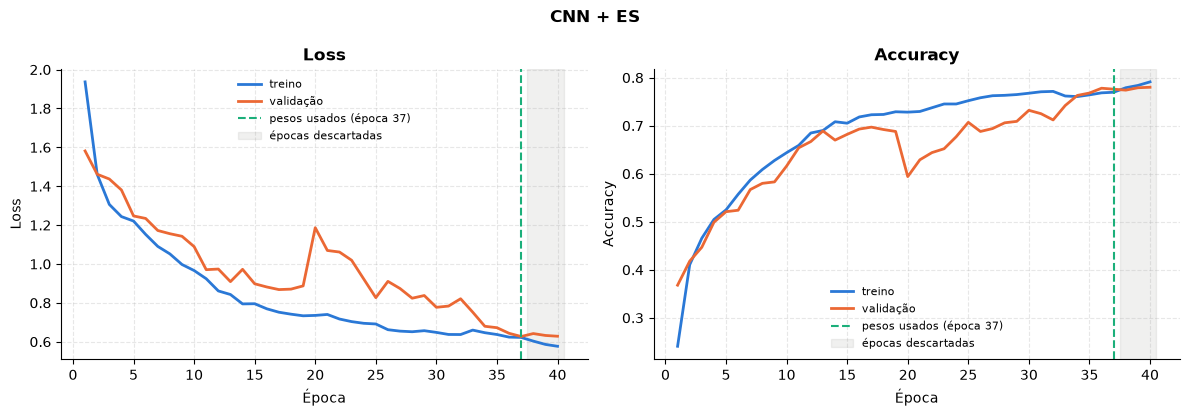

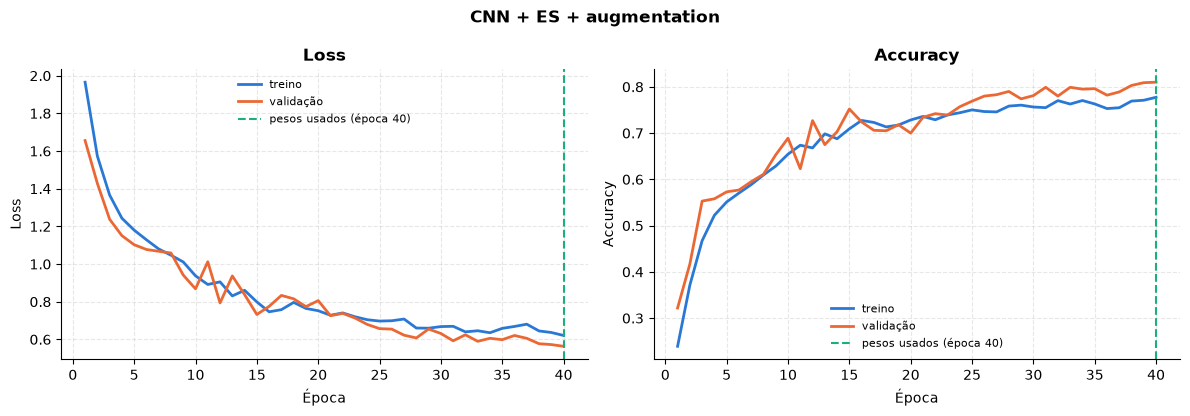

In [32]:
for nome, treino in treinos_cnn.items():
    plot_history(treino, nome)


**Interpretação das curvas:**
- **CNN + ES (sem augmentation): ainda aprendendo no fim do orçamento, sem overfitting claro.** A `val_loss` cai quase até o fim e atinge o mínimo na época 37 (0,627); o early stopping não chega a parar o treino. No meio há um episódio de instabilidade: da época 19 para a 20, a `val_loss` salta de 0,89 para 1,19 e a accuracy de validação cai de 0,69 para 0,59, e as duas levam umas cinco épocas para se recuperar. No fim, treino e validação ficam próximos (accuracy ~0,79 × ~0,78). A CNN ajusta o treino bem melhor que a MLP (~0,79 contra ~0,56) e ainda não decora as imagens.
- **CNN + ES + augmentation: também sem sinal de overfitting em 40 épocas.** Treino e validação andam juntos, a `val_loss` desce até 0,563 na última época e a accuracy de validação fica entre 0,78 e 0,81 nas últimas 10 épocas. A accuracy de treino aparece abaixo da de validação porque é medida nas imagens aumentadas (A4).
- **O regime mudou em relação à MLP:** a MLP ficava em underfitting porque não consegue representar as imagens; a CNN ajusta bem o treino e só é limitada pelo orçamento de 40 épocas (as duas variantes ainda melhoravam no fim). Aqui o augmentation não está corrigindo overfitting: ele mostra versões giradas e espelhadas das cenas e ensina a CNN a reconhecê-las em qualquer orientação.

### CNN × MLP

**O que:** as métricas das duas CNNs ao lado da MLP escolhida na A6, e a escolha da CNN que vai para a comparação final.
**Por quê:** é a comparação pedida pelo enunciado (accuracy e F1 da CNN contra a MLP, com os mesmos dados). A escolha da variante da CNN usa **só o F1-macro da validação**, como na MLP. As colunas de teste mostram o desempenho reportado e não influenciam nenhuma escolha.


In [33]:
for nome, modelo in modelos_cnn.items():
    evaluate_model(modelo, nome, treinos_cnn[nome], relatorio=False)

MELHOR_CNN = tabela_resultados().loc[list(VARIANTES_CNN), "val_f1_macro"].idxmax()  # só validação
print(f"MLP da A6: {MELHOR_MLP} · CNN escolhida (maior F1-macro na validação): {MELHOR_CNN}")

# 2×2 arquitetura × augmentation: separa o efeito da arquitetura do efeito do augmentation.
comparacao_cnn = tabela_resultados().loc[["MLP + ES", "MLP + ES + augmentation", *VARIANTES_CNN], [
    "val_accuracy", "val_f1_macro", "test_accuracy", "test_f1_macro",
    "params_totais", "epocas", "pesos_da_epoca", "tempo_treino_s"]]
comparacao_cnn["tempo por época (s)"] = comparacao_cnn["tempo_treino_s"] / comparacao_cnn["epocas"]
comparacao_cnn.rename(columns={
    "val_accuracy": "accuracy val", "val_f1_macro": "F1-macro val",
    "test_accuracy": "accuracy teste", "test_f1_macro": "F1-macro teste",
    "params_totais": "parâmetros", "epocas": "épocas rodadas", "pesos_da_epoca": "pesos da época",
    "tempo_treino_s": "tempo de treino (s)",
}).round(3)


MLP da A6: MLP + ES + augmentation · CNN escolhida (maior F1-macro na validação): CNN + ES + augmentation


,accuracy val,F1-macro val,accuracy teste,F1-macro teste,parâmetros,épocas rodadas,pesos da época,tempo de treino (s),tempo por época (s)
MLP + ES,0.474,0.469,0.486,0.479,3180170,39,31,66.303,1.700
MLP + ES + augmentation,0.529,0.507,0.518,0.498,3180170,40,39,80.660,2.016
CNN + ES,0.776,0.761,0.770,0.758,111050,40,37,174.860,4.371
CNN + ES + augmentation,0.810,0.797,0.792,0.778,111050,40,40,188.523,4.713


**Interpretação:**
- **Efeito da arquitetura, isolado nas duas situações:** sem augmentation, a CNN passa de 0,469 (MLP + ES) para **0,761** de F1 na validação (+29 pontos); com augmentation, de 0,507 para **0,797** (+29 pontos). As duas escolhidas (MLP e CNN) usam augmentation, então a comparação final não mistura arquitetura com augmentation.
- **Efeito do augmentation, isolado:** praticamente o mesmo nos dois modelos: +3,8 pontos na MLP (0,469 → 0,507) e **+3,6 na CNN** (0,761 → 0,797), pouco mais de 2× o erro-padrão (~1,6 ponto, A3). No teste a direção se repete (+1,9 e +2,0). Pelo critério da validação, a CNN escolhida é a **CNN + ES + augmentation**: F1-macro 0,797 na validação e **0,778 no teste**, contra 0,498 da melhor MLP no teste.
- **Tamanho das diferenças:** os 29 pontos da arquitetura estão muito acima do ruído de amostragem. O experimento usa uma única semente, mas a diferença também aparece época a época: nas últimas 10 épocas, a accuracy de validação das duas CNNs fica entre 0,71 e 0,81, e a das MLPs nunca passa de 0,54 em todo o treino.
- **Com ~29× menos parâmetros** (111.050 contra 3.180.170): mais parâmetros não significam mais desempenho; o que importa é como eles são usados.
- **Custo de treino:** a CNN gasta ~4,4–4,7 s por época, contra ~1,7–2,3 s da MLP, porque cada convolução faz muitas multiplicações por posição da imagem. No total, ~175–190 s contra ~65–90 s, cerca de 2–2,5×. Os tempos variam entre execuções e entre máquinas, então a comparação vale em ordem de grandeza.
- **Orçamento:** as duas CNNs e a MLP com augmentation usaram os pesos de épocas no fim do orçamento (CNNs: 37 e 40 de 40; MLP: 39 de 40). A comparação é justa (mesmo orçamento para todos), mas nenhuma convergiu completamente, então os números valem "em 40 épocas".


### Onde a CNN erra, comparada à MLP

**O que:** a matriz de confusão da CNN escolhida (teste) e os mesmos pares de classes analisados na A5, agora com a fração de erro da MLP e da CNN lado a lado. Abaixo, o F1 de cada classe nos dois modelos.
**Por quê:** testa a hipótese deixada na A5. Se a MLP erra por classificar pela **cor**, a CNN, que enxerga textura e forma, deveria reduzir justamente as confusões entre classes de cor parecida. É uma análise **descritiva** do teste: nenhuma escolha sai daqui.


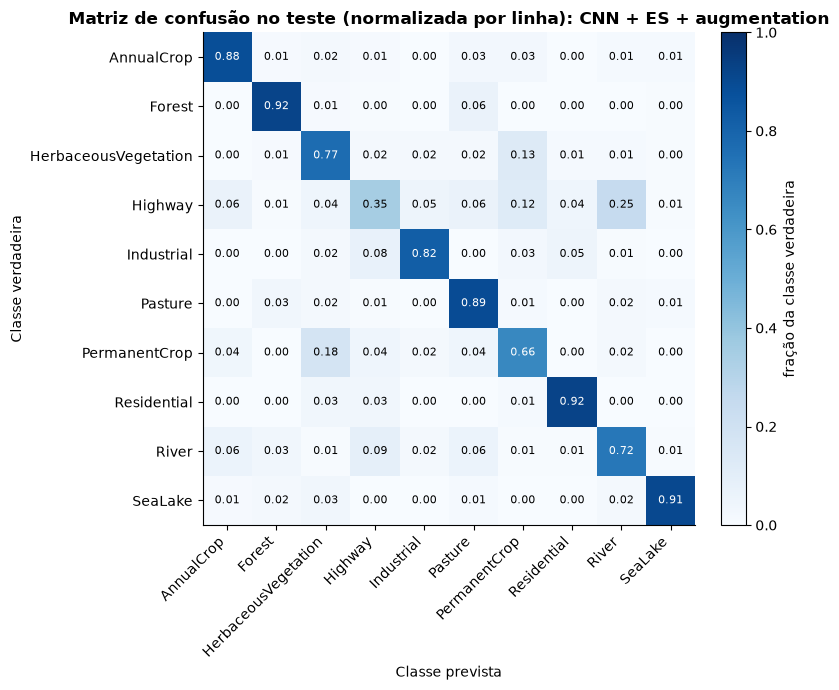

In [34]:
plot_confusion_matrix(MELHOR_CNN)


In [35]:
mlp, cnn = MATRIZES[MELHOR_MLP]["test"], MATRIZES[MELHOR_CNN]["test"]
linhas = []
for grupo, pares in pares_a2.items():
    for a, b in pares:
        i, j = posicao[a], posicao[b]
        linhas.append({"grupo": grupo, "par (A × B)": f"{a} × {b}",
                       "MLP A→B": mlp[i, j], "CNN A→B": cnn[i, j], "MLP B→A": mlp[j, i], "CNN B→A": cnn[j, i]})
print(f"MLP = {MELHOR_MLP} · CNN = {MELHOR_CNN} (matrizes do teste)")
display(pd.DataFrame(linhas).set_index(["grupo", "par (A × B)"]).round(3))

print(f"Principais confusões da CNN ({MELHOR_CNN}):")
display(top_confusions(MELHOR_CNN))

por_classe = pd.DataFrame({
    "recall MLP": np.diag(mlp), "recall CNN": np.diag(cnn),
    "F1 MLP": F1_POR_CLASSE[MELHOR_MLP]["test"].to_numpy(), "F1 CNN": F1_POR_CLASSE[MELHOR_CNN]["test"].to_numpy(),
}, index=CLASSES)
por_classe["ganho de F1"] = por_classe["F1 CNN"] - por_classe["F1 MLP"]
por_classe.sort_values("ganho de F1", ascending=False).round(3)


MLP = MLP + ES + augmentation · CNN = CNN + ES + augmentation (matrizes do teste)


MLP A→B  \
grupo                                par (A × B)                                     
forma/textura (hipótese do A2)       AnnualCrop × PermanentCrop              0.099   
                                     PermanentCrop × HerbaceousVegetation    0.204   
                                     AnnualCrop × Pasture                    0.018   
                                     Pasture × HerbaceousVegetation          0.007   
                                     Highway × River                         0.259   
cor média próxima (tabela RGB do A2) Residential × HerbaceousVegetation      0.090   
                                     Residential × Highway                   0.081   
                                     HerbaceousVegetation × Highway          0.081   
                                     SeaLake × Pasture                       0.054   
                                     SeaLake × Forest                        0.113   
                                     Forest × Pasture                        0.045   
                                     River × Pasture                         0.049   

                                                                           CNN A→B  \
grupo                                par (A × B)                                     
forma/textura (hipótese do A2)       AnnualCrop × PermanentCrop              0.027   
                                     PermanentCrop × HerbaceousVegetation    0.177   
                                     AnnualCrop × Pasture                    0.027   
                                     Pasture × HerbaceousVegetation          0.020   
                                     Highway × River                         0.249   
cor média próxima (tabela RGB do A2) Residential × HerbaceousVegetation      0.031   
                                     Residential × Highway                   0.031   
                                     HerbaceousVegetation × Highway          0.023   
                                     SeaLake × Pasture                       0.014   
                                     SeaLake × Forest                        0.023   
                                     Forest × Pasture                        0.063   
                                     River × Pasture                         0.059   

                                                                           MLP B→A  \
grupo                                par (A × B)                                     
forma/textura (hipótese do A2)       AnnualCrop × PermanentCrop              0.210   
                                     PermanentCrop × HerbaceousVegetation    0.090   
                                     AnnualCrop × Pasture                    0.020   
                                     Pasture × HerbaceousVegetation          0.009   
                                     Highway × River                         0.135   
cor média próxima (tabela RGB do A2) Residential × HerbaceousVegetation      0.153   
                                     Residential × Highway                   0.108   
                                     HerbaceousVegetation × Highway          0.054   
                                     SeaLake × Pasture                       0.142   
                                     SeaLake × Forest                        0.086   
                                     Forest × Pasture                        0.142   
                                     River × Pasture                         0.216   

                                                                           CNN B→A  
grupo                                par (A × B)                                    
forma/textura (hipótese do A2)       AnnualCrop × PermanentCrop              0.038  
                                     PermanentCrop × HerbaceousVegetation    0.126  
                                     AnnualCrop × Pasture                    0.000  
                                   

Principais confusões da CNN (CNN + ES + augmentation):


,classe verdadeira,prevista como,fração da classe verdadeira
0,Highway,River,0.249
1,PermanentCrop,HerbaceousVegetation,0.177
2,HerbaceousVegetation,PermanentCrop,0.126
3,Highway,PermanentCrop,0.124
4,River,Highway,0.086


,recall MLP,recall CNN,F1 MLP,F1 CNN,ganho de F1
Residential,0.552,0.924,0.548,0.916,0.368
HerbaceousVegetation,0.329,0.766,0.373,0.738,0.364
AnnualCrop,0.509,0.883,0.515,0.871,0.356
Pasture,0.385,0.892,0.463,0.779,0.315
PermanentCrop,0.290,0.661,0.359,0.653,0.294
SeaLake,0.649,0.905,0.661,0.931,0.270
Industrial,0.843,0.822,0.595,0.849,0.254
River,0.541,0.724,0.476,0.702,0.225
Highway,0.189,0.351,0.217,0.428,0.210
Forest,0.820,0.919,0.771,0.913,0.142


**Interpretação: o que a CNN corrige e o que não corrige**

A MLP de referência aqui é a escolhida na A6 (com augmentation). Nela, Pasture é a principal **origem** de erros (Pasture → River 0,216, → SeaLake 0,142, → Forest 0,142), como já acontecia no baseline (Pasture → River 0,196, A5). São de novo erros entre classes de cor média próxima (Pasture × River: 62/89/94 × 67/87/97 no A2).

- **A CNN melhora todas as 10 classes.** Os maiores ganhos de F1 são em Residential (+0,37), HerbaceousVegetation (+0,36) e AnnualCrop (+0,36).
- **As confusões de cor caem bastante,** para no máximo ~0,06. Exemplos:
  - HerbaceousVegetation → Residential: 0,153 → 0,014;
  - SeaLake → Forest: 0,113 → 0,023;
  - Pasture → River: 0,216 → 0,020.

  Sobram resíduos pequenos, como Forest → Pasture (0,045 → 0,063) e River → Pasture (0,049 → 0,059). O resultado é consistente com a CNN separando essas classes pela **textura** (o padrão denso das casas, a superfície lisa da água), e não só pela cor.
- **Parte das confusões de forma também é resolvida:** AnnualCrop × PermanentCrop cai de 0,099 e 0,210 para 0,027 e 0,038. A diferença entre lavoura temporária e permanente está na textura dos talhões, e a CNN a captura.
- **Duas confusões não melhoram e passam a ser as maiores da CNN:**
  - **Highway → River (0,249).** Um quarto das rodovias vira rio, e o recall de Highway é só 0,351, o pior da CNN. Highway também vai para PermanentCrop (0,124).
  - **PermanentCrop → HerbaceousVegetation (0,177)**, e no sentido inverso HerbaceousVegetation → PermanentCrop (0,126).

  Na MLP esses dois pares já eram altos (0,259 e 0,204). As quedas de 1 e 3 pontos estão dentro dos ~5 pontos de ruído por classe (A3), então a leitura correta é "não melhoraram". Uma hipótese: são casos em que a diferença está numa estrutura fina, como a largura e a cor de uma faixa linear ou as fileiras de um pomar, difícil de ver em 64×64 pixels. Testar isso exigiria mais resolução, o que fica fora do escopo.


### Por que a CNN superou a MLP

| O que mudou | Evidência neste notebook |
|---|---|
| **A CNN consegue ajustar o treino.** A MLP ficava em underfitting; a CNN extrai features úteis dos pixels | MLP: ~56% de accuracy no treino (A5). CNN sem augmentation: ~79% no treino e 0,761 de F1 na validação |
| **Os erros deixam de ser guiados pela cor** | As confusões entre classes de cor parecida caem para no máximo ~0,06, e AnnualCrop × PermanentCrop, separadas pela textura, quase desaparecem |
| **Muito menos parâmetros, melhor desempenho** | 111.050 contra 3.180.170 (~29× menos), com F1 ~29 pontos maior |
| **O ganho vem da arquitetura, não do augmentation** | O augmentation rende quase o mesmo nos dois modelos (+3,8 pontos na MLP, +3,6 na CNN); trocar a MLP pela CNN rende +29 pontos, com ou sem ele |

**O mecanismo** por trás desses resultados é o **viés indutivo** da convolução:
- **filtros locais** olham vizinhanças de pixels;
- **pesos compartilhados** aplicam o mesmo detector em toda a imagem;
- o **pooling** combina padrões locais em estruturas maiores.

A CNN já "parte do princípio" de que pixels vizinhos se relacionam, assim como uma árvore de decisão parte do princípio de que a resposta muda por cortes em cada variável. A MLP precisaria aprender essa estrutura a partir dos dados, e 5.000 imagens não bastam: ela acaba usando o sinal mais fácil, a cor.

### Resumo da B1

| Item | Resultado |
|---|---|
| Arquitetura | 3 blocos conv (32 → 64 → 128) + GAP + Dense(128) + softmax, **111.050 parâmetros** |
| CNN + ES | F1-macro 0,761 (val) · sem overfitting claro; ainda melhorava na época 37 de 40 |
| **CNN + ES + augmentation** (escolhida) | F1-macro **0,797 (val) · 0,778 (teste)**, sem sinal de overfitting em 40 épocas |
| Ganho sobre a MLP | +29 pontos de F1 (com e sem augmentation), com ~29× menos parâmetros e ~2–2,5× o tempo de treino |
| Erros restantes | Highway → River (recall de Highway 0,351) e PermanentCrop → HerbaceousVegetation |


## B2. Transfer Learning: feature extraction (MobileNetV2)

### A ideia: reaproveitar features aprendidas em outro problema

A CNN da B1 aprendeu seus filtros do zero, com só 5.000 imagens. O **Transfer Learning** parte de uma rede que já aprendeu a "ver" em um dataset enorme (a **MobileNetV2**, treinada no **ImageNet**: ~1,3 milhão de fotos, 1.000 classes) e reaproveita os filtros dela. As primeiras camadas detectam bordas, texturas e formas, padrões úteis para quase qualquer imagem, inclusive de satélite.

**Analogia com o tabular:** é como montar um `Pipeline([("features", extrator_ja_ajustado), ("clf", LogisticRegression())])` em que o primeiro passo **já veio ajustado** de outro dataset e você só dá `fit` no último. Nesta etapa 1 (**feature extraction**), a MobileNetV2 inteira fica **congelada** e só a camada final aprende. Na B3 (**fine-tuning**), as últimas camadas da base também passam a ser ajustadas.

**Vazamento?** Não. Os pesos da base vêm do ImageNet, um dataset sem nenhuma imagem do EuroSAT, e não são ajustados aqui. A única coisa **ajustada** nesta etapa é a camada final, e só com o conjunto de treino; a validação escolhe a variante e o teste só é reportado.

### Arquitetura

| Camada | Saída | Parâmetros | Treinável? |
|---|---|---|---|
| Entrada (o mesmo array `uint8` 64×64×3 dos outros modelos) | 64×64×3 | 0 | — |
| `Resizing(96, 96)` | 96×96×3 | 0 | — |
| `Rescaling(1/127.5, offset=-1)` | 96×96×3, em [−1, 1] | 0 | — |
| **MobileNetV2** sem o topo, pesos ImageNet | 3×3×1280 | 2.257.984 | **não (congelada)** |
| `GlobalAveragePooling2D` | 1.280 | 0 | — |
| `Dense(10, softmax)` | 10 | 12.810 | **sim** |
| **Total** | | **2.270.794** | **12.810 treináveis (0,6%)** |

| Decisão | Escolha | Por quê |
|---|---|---|
| **Modelo pré-treinado** | MobileNetV2 (recomendada no enunciado) | Feita para celulares: usa **convoluções separáveis em profundidade**, bem mais baratas que as comuns, e cabe em CPU |
| **Redimensionamento** | `Resizing(96)` **dentro** do modelo | 96×96 é a menor resolução com pesos ImageNet publicados. Ampliar não cria informação, mas põe os objetos numa escala mais próxima da que os filtros viram no pré-treino. Por estar dentro do modelo, todos os modelos recebem o mesmo array 64×64 |
| **Normalização** | `Rescaling` para **[−1, 1]**, não `/255` | É a escala com que a MobileNetV2 foi treinada; com [0, 1] os filtros receberiam valores diferentes dos que esperam |
| **Congelamento** | `base.trainable = False` | O otimizador não altera nenhum peso da base |
| **Modo da base** | chamada com `training=False` | A base tem **BatchNormalization**. Em modo de inferência, ela usa as médias e variâncias do ImageNet em vez das do lote atual. Com a base congelada (`trainable=False`), o Keras já faz isso sozinho. O `training=False` deixa a intenção explícita, mas no Keras 3 **não basta** no fine-tuning (demonstração no início da B3) |
| **Cabeça** | `GlobalAveragePooling2D` → `Dense(10, softmax)` | É literalmente "treinar apenas a camada final" do enunciado. O GAP resume cada um dos 1.280 mapas da base num número (como na CNN da B1), e a softmax é a mesma dos outros modelos |
| **Treino** | Adam lr 1e-3, até **15 épocas**, early stopping com paciência **4** (A1) | A cabeça começa do zero, então usa a lr padrão. As features já prontas fazem o treino convergir rápido, e cada época custa mais (a base processa 5.000 imagens 96×96) |

**Variantes:** como na MLP e na CNN, treinamos **com e sem data augmentation** (as duas com early stopping) e escolhemos pela validação a melhor etapa 1. As duas seguem para o fine-tuning da B3 (decisão dos alunos), e a escolha final do TL compara as etapas 1 e 2 pela validação. O augmentation é aplicado na imagem 64×64, antes do `Resizing`, exatamente como nos outros modelos. Nos nomes, **TL-FE** quer dizer "Transfer Learning, etapa de feature extraction".


In [36]:
def construir_tl(nome, *, augmentation=False):
    """MobileNetV2 (ImageNet) congelada + GAP + Dense(10, softmax): só a camada final treina."""
    keras.utils.set_random_seed(SEED)  # mesma inicialização da cabeça nas duas variantes
    base = keras.applications.MobileNetV2(
        input_shape=(TL_IMG_SIZE, TL_IMG_SIZE, 3), include_top=False, weights="imagenet",
        name="mobilenetv2")  # nome fixo: a B3 busca a base por ele para descongelar
    base.trainable = False  # o otimizador não altera nenhum peso da base

    # API funcional (em vez de Sequential) para poder chamar a base com training=False.
    # Entrada float32 (padrão), não uint8: assim o Resizing interpola sem arredondar.
    entrada = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = make_augmentation()(entrada) if augmentation else entrada
    x = layers.Resizing(TL_IMG_SIZE, TL_IMG_SIZE)(x)
    x = layers.Rescaling(1 / 127.5, offset=-1)(x)  # [0, 255] → [−1, 1], a escala do pré-treino
    # Intenção: BatchNorm em modo de inferência. Quem garante isso é o trainable=False das BatchNorm
    # (aqui, a base inteira; na B3, também as descongeladas), pois o fit do Keras 3 sobrescreve este training.
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    saida = layers.Dense(len(CLASSES), activation="softmax")(x)
    return keras.Model(entrada, saida, name=nome)


tl_demo = construir_tl("tl_fe")
tl_demo.summary()

# Prova do congelamento: a base não tem nenhum peso treinável; só a cabeça treina.
partes = {"base MobileNetV2 (congelada)": tl_demo.get_layer("mobilenetv2"),
          "cabeça Dense(10, softmax)": tl_demo.layers[-1], "modelo inteiro": tl_demo}
congelamento = pd.DataFrame({
    "parâmetros totais": [p.count_params() for p in partes.values()],
    "parâmetros treináveis": [int(sum(np.prod(w.shape) for w in p.trainable_weights)) for p in partes.values()],
}, index=list(partes))
assert congelamento["parâmetros treináveis"].tolist() == [0, 1280 * 10 + 10, 1280 * 10 + 10]
del tl_demo, partes  # o modelo de demonstração não é mais usado
congelamento


      0/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

  16384/9406464 ━━━━━━━━━━━━━━━━━━━━ 43s 5us/step

  49152/9406464 ━━━━━━━━━━━━━━━━━━━━ 38s 4us/step

  81920/9406464 ━━━━━━━━━━━━━━━━━━━━ 37s 4us/step

 131072/9406464 ━━━━━━━━━━━━━━━━━━━━ 27s 3us/step

 163840/9406464 ━━━━━━━━━━━━━━━━━━━━ 24s 3us/step

... (28 outputs left out)

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

,parâmetros totais,parâmetros treináveis
base MobileNetV2 (congelada),2257984,0
"cabeça Dense(10, softmax)",12810,12810
modelo inteiro,2270794,12810


### Treino das duas variantes (etapa 1)

**O que:** treinar só a cabeça, com e sem augmentation, com o mesmo `train_model` dos outros modelos (Adam, lr 1e-3, batch 64), até 15 épocas e early stopping com paciência 4.
**Por quê:** é o mesmo protocolo dos outros modelos, só com o orçamento do TL definido no A1. Duas conferências acompanham o treino:
- **a cabeça começa com os mesmos pesos nas duas variantes,** então a única diferença entre elas é o augmentation;
- **a base não muda:** guardamos uma cópia de todos os pesos dela antes do treino (inclusive as médias e variâncias da BatchNorm) e comparamos depois, na avaliação.

**Custo:** nesta implementação, a base congelada recalcula as mesmas features a cada época. Sem augmentation, daria para calcular as features **uma única vez** e treinar a `Dense` sobre elas em segundos (como dar `fit` só no último passo de um `Pipeline` já transformado). Mantemos o treino ponta a ponta por dois motivos: é o mesmo `train_model` de todos os modelos, e com augmentation as imagens mudam a cada época, o que impede esse atalho.


In [37]:
VARIANTES_TL = {
    "TL-FE + ES": {},
    "TL-FE + ES + augmentation": {"augmentation": True},
}

modelos_tl, treinos_tl, pesos_base_antes, cabeca_inicial = {}, {}, {}, {}
for nome, opcoes in VARIANTES_TL.items():
    print(f"\n===== {nome} =====")
    modelos_tl[nome] = construir_tl(nome.lower().replace("-", "_").replace(" + ", "_"), **opcoes)
    cabeca_inicial[nome] = [w.copy() for w in modelos_tl[nome].layers[-1].get_weights()]
    # Cópia de todos os pesos da base (inclusive os da BatchNorm) antes do treino.
    pesos_base_antes[nome] = [w.copy() for w in modelos_tl[nome].get_layer("mobilenetv2").get_weights()]
    treinos_tl[nome] = train_model(modelos_tl[nome], epochs=TL_EPOCHS, patience=TL_PATIENCE)

# As duas variantes partiram da mesma cabeça: a diferença entre elas é só o augmentation.
assert all(np.array_equal(a, b) for a, b in zip(*cabeca_inicial.values()))



===== TL-FE + ES =====


Epoch 1/15


79/79 - 15s - 186ms/step - accuracy: 0.7120 - loss: 0.8913 - val_accuracy: 0.8670 - val_loss: 0.4208


Epoch 2/15


79/79 - 10s - 132ms/step - accuracy: 0.8884 - loss: 0.3485 - val_accuracy: 0.8950 - val_loss: 0.3343


Epoch 3/15


... (53 outputs left out)

79/79 - 11s - 137ms/step - accuracy: 0.9162 - loss: 0.2347 - val_accuracy: 0.8990 - val_loss: 0.2836


Epoch 15/15


79/79 - 11s - 138ms/step - accuracy: 0.9256 - loss: 0.2193 - val_accuracy: 0.9050 - val_loss: 0.2816


→ 15 épocas em 169.0 s · menor val_loss na época 13 (0.2796) · pesos finais da época 13


### Curvas de treino × validação

**O que:** as curvas das duas variantes da etapa 1, no mesmo formato da MLP e da CNN.
**Por quê:** mostram se a cabeça treinada sobre as features congeladas sofre de underfitting (as features do ImageNet não separam bem as classes do EuroSAT) ou de overfitting (a cabeça decora o treino). Com augmentation, a accuracy de treino é medida nas imagens aumentadas e pode ficar abaixo da de validação (A4).


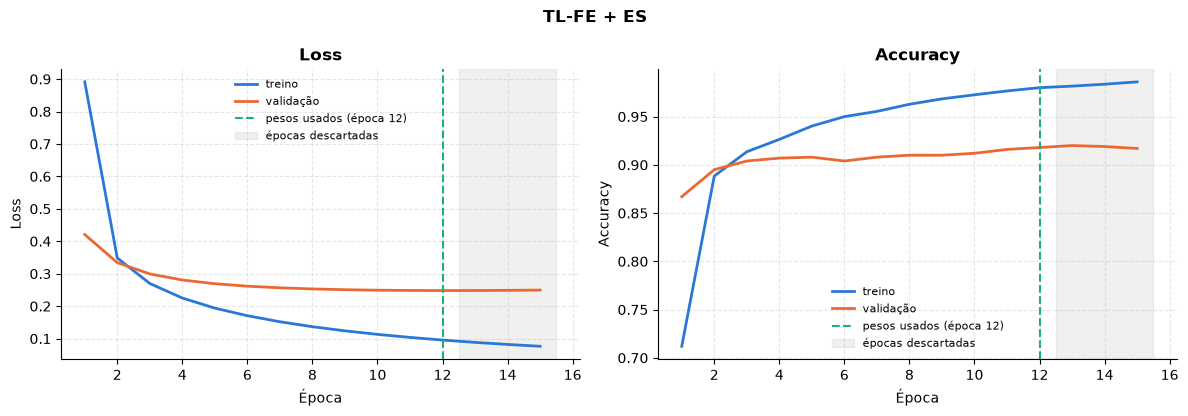

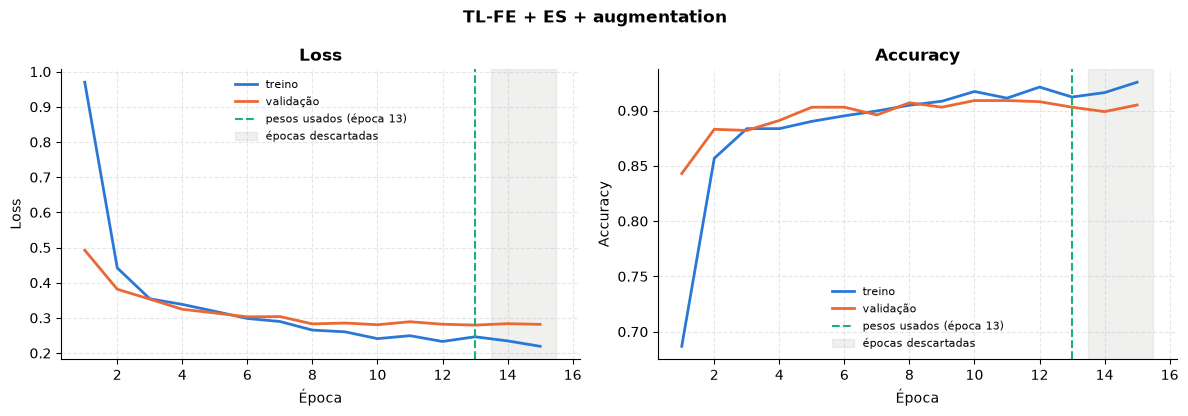

In [38]:
for nome, treino in treinos_tl.items():
    plot_history(treino, nome)


**Interpretação das curvas:**
- **As features prontas aparecem já na 1ª época.** Depois de uma única passada, a accuracy de validação é de 0,867 (sem augmentation) e 0,843 (com). A CNN da B1 levou dezenas de épocas para chegar a ~0,80. Nenhum filtro foi ajustado: as features que a MobileNetV2 aprendeu no ImageNet já separam bem as classes do EuroSAT, e a camada final só precisa aprender a combiná-las.
- **TL-FE + ES: sem underfitting e com um início de overfitting da cabeça.**
  - A accuracy de treino sobe até 0,986, enquanto a de validação estaciona em 0,91–0,92 a partir da época 8.
  - A `val_loss` atinge o mínimo na época 12 (0,2481) e depois fica praticamente parada (0,2482 a 0,2496), enquanto a loss de treino continua caindo (0,096 → 0,076). No fim, o vão de accuracy entre treino e validação é de ~7 pontos.
  - O early stopping não chegou a parar o treino: só 3 épocas sem melhora, contra uma paciência de 4. Os pesos usados são os da época 12. Como a `val_loss` já tinha estacionado, o limite de 15 épocas não cortou nenhuma melhora relevante.
- **TL-FE + ES + augmentation: sem overfitting, mas também sem ganho.**
  - A accuracy de treino, medida nas imagens aumentadas (A4), fica perto da de validação (~0,92 × ~0,90).
  - A `val_loss` desce devagar e oscila (0,283 na época 8 → 0,280 na época 13, a usada). Mais épocas talvez melhorassem a loss em milésimos, mas a accuracy de validação já estava parada em 0,90–0,91 desde a época 5.
- **O que isso diz para a B3:** a cabeça já ajusta quase todo o treino, então o limite não é a capacidade da camada final, e sim as **features**. Elas foram aprendidas em fotos tiradas de lado (ImageNet), e não em cenas vistas de cima. O fine-tuning ataca exatamente isso, adaptando as últimas camadas da base ao domínio. O risco é ampliar o overfitting que já começou, e por isso a taxa de aprendizado é 100× menor.


### Etapa 1 × CNN × MLP

**O que:** confere que a base ficou intacta, avalia as duas variantes, escolhe a que segue para a B3 e compara o TL com a MLP escolhida e as duas CNNs, em duas tabelas: **desempenho** (accuracy, precision, recall e F1 macro) e **custo**.
**Por quê:**
- A etapa 1 é avaliada **sozinha, antes do fine-tuning**. A B3 vai continuar treinando este mesmo modelo, e o early stopping da etapa 2 não conhece a `val_loss` da etapa 1. Precisamos do resultado da etapa 1 registrado (e dos seus pesos guardados) para decidir na B3, pela validação, se o fine-tuning compensa.
- A escolha da variante usa **só o F1-macro da validação**, como na MLP e na CNN. As duas CNNs aparecem para comparar o efeito do augmentation no TL com o efeito na CNN.
- A tabela de custo inclui **parâmetros treináveis** e **tempo de inferência**. No TL, o número de parâmetros totais não mede o esforço do treino (só 0,6% deles é treinado), mas toda a base roda em cada previsão.


In [39]:
for nome, modelo in modelos_tl.items():
    evaluate_model(modelo, nome, treinos_tl[nome], relatorio=False)
    # Prova de que a base ficou congelada: todos os pesos iguais aos de antes do treino.
    pesos_depois = modelo.get_layer("mobilenetv2").get_weights()
    assert all(np.array_equal(a, d) for a, d in zip(pesos_base_antes[nome], pesos_depois)), nome
print("Base congelada conferida: nenhum peso da MobileNetV2 (inclusive da BatchNorm) mudou no treino.")

MELHOR_TL_FE = tabela_resultados().loc[list(VARIANTES_TL), "val_f1_macro"].idxmax()  # só validação
# Pesos da etapa 1 das duas variantes: a B3 parte deles em modelos novos, sem alterar estes.
PESOS_TL_FE = {nome: modelo.get_weights() for nome, modelo in modelos_tl.items()}
print(f"MLP: {MELHOR_MLP} · CNN: {MELHOR_CNN} · TL da etapa 1 (maior F1-macro na validação): {MELHOR_TL_FE}")

# MLP escolhida + as duas CNNs (leitura 2×2 do augmentation) + as duas variantes do TL.
desempenho, custo = tabelas_comparacao([MELHOR_MLP, *VARIANTES_CNN, *VARIANTES_TL])
print("\nDesempenho (precision, recall e F1 em média macro):")
display(desempenho)
print("Custo:")
custo


Base congelada conferida: nenhum peso da MobileNetV2 (inclusive da BatchNorm) mudou no treino.
MLP: MLP + ES + augmentation · CNN: CNN + ES + augmentation · TL da etapa 1 (maior F1-macro na validação): TL-FE + ES

Desempenho (precision, recall e F1 em média macro):


validação                            teste  \
                           accuracy precision recall     F1 accuracy   
MLP + ES + augmentation       0.529     0.519  0.520  0.507    0.518   
CNN + ES                      0.776     0.775  0.766  0.761    0.770   
CNN + ES + augmentation       0.810     0.801  0.803  0.797    0.792   
TL-FE + ES                    0.918     0.919  0.916  0.916    0.906   
TL-FE + ES + augmentation     0.903     0.902  0.900  0.900    0.904   

                                                   
                          precision recall     F1  
MLP + ES + augmentation       0.509  0.511  0.498  
CNN + ES                      0.769  0.760  0.758  
CNN + ES + augmentation       0.778  0.785  0.778  
TL-FE + ES                    0.903  0.901  0.902  
TL-FE + ES + augmentation     0.902  0.900  0.900

Custo:


,parâmetros,treináveis,épocas rodadas,pesos da época,tempo de treino (s),tempo por época (s),inferência (ms/imagem)
MLP + ES + augmentation,3180170,3180170,40,39,80.660,2.016,0.069
CNN + ES,111050,111050,40,37,174.860,4.371,0.272
CNN + ES + augmentation,111050,111050,40,40,188.523,4.713,0.278
TL-FE + ES,2270794,12810,15,12,162.236,10.816,1.764
TL-FE + ES + augmentation,2270794,12810,15,13,169.003,11.267,1.749


**Interpretação:**
- **Escolha da etapa 1:** **TL-FE + ES** (sem augmentation), com F1-macro de **0,916** na validação, contra 0,900 com augmentation. A diferença de 1,6 ponto está no nível do ruído de amostragem (~1,6 ponto, A3), então a leitura correta é que **as duas empatam**. O critério da validação escolhe a sem augmentation, e no teste elas também ficam juntas (0,902 × 0,900).
- **Efeito do augmentation, comparado à CNN:** na CNN ele valeu **+3,6 pontos** (0,761 → 0,797, B1); no TL-FE, **nenhum ganho** (−1,6). Isso é coerente com o que as curvas mostram. O augmentation ensina o modelo a reconhecer a mesma cena girada ou espelhada, mas aqui a única parte treinável é uma camada linear sobre features fixas. Ela não consegue tornar essas features invariantes à rotação; só a B3, ao ajustar a base, consegue. Além disso, o overfitting da cabeça é leve, então há pouco para regularizar.
- **TL × CNN × MLP:** F1-macro de validação de **0,916 × 0,797 × 0,507**; no teste, **0,902 × 0,778 × 0,498**. O TL ganha da CNN por ~12 pontos nos dois conjuntos, bem acima do ruído. Precision e recall macro acompanham o F1 (TL: 0,919 e 0,916 na validação), então o ganho não vem de trocar um tipo de erro pelo outro. O teste só confirma: nenhuma escolha usou essas colunas.
- **Por que o TL ganha:** a CNN aprendeu seus filtros com 5.000 imagens; a MobileNetV2 aprendeu os dela com ~1,3 milhão. Bordas, texturas e formas genéricas transferem bem, mesmo vindo de fotos tiradas de lado. É o mesmo raciocínio de usar um extrator de features ajustado num dataset grande quando o seu é pequeno.
- **Parâmetros totais × treináveis:** o TL tem **2,27 milhões** de parâmetros, mas treina só **12.810**, ~9× menos que os 111.050 da CNN. Ele vence com o menor número de parâmetros treinados entre os três modelos.
- **Custo de treino** (faixa entre as variantes de cada modelo):
  - TL: **~160–170 s** (15 épocas × ~11 s);
  - CNN: ~175–190 s (40 × ~4,4–4,7 s);
  - MLP: ~65–90 s (40 × ~1,7–2,3 s).

  Cada época do TL custa ~2,5× a da CNN, porque a base inteira processa 5.000 imagens de 96×96. Mas o TL roda menos épocas, e o total fica na mesma ordem de grandeza (nesta execução, até um pouco abaixo do da CNN).
  - Quase todo esse custo é a passada pela base congelada, repetida a cada época. Sem augmentation, as features poderiam ser calculadas uma única vez, e o treino cairia de ~160 s para algo próximo do custo de uma época (~11 s). É uma **estimativa**, não medida aqui, e esse atalho é impossível com augmentation.
  - O custo do pré-treino no ImageNet não entra na conta: ele foi pago por quem publicou os pesos.
- **Custo de inferência:** é aqui que o TL é mais caro. Ele leva **~1,75–1,8 ms por imagem**, contra ~0,28 ms da CNN (~6×) e ~0,07 ms da MLP (~25×), porque cada previsão passa pela base inteira. Para classificar 2.000 imagens isso ainda dá ~3,5 s em CPU.
- **Orçamento:** as duas variantes usaram os pesos de épocas perto do fim das 15 (12 e 13), mas com a `val_loss` estacionada. Os números valem "em 15 épocas", com pouca margem esperada de melhora só na cabeça.


### Onde o TL erra, comparado à CNN

**O que:** a matriz de confusão do TL escolhido (teste), as principais confusões dele, as três maiores confusões que restaram na CNN (B1) e o F1 de cada classe nos dois modelos.
**Por quê:** a CNN deixou três confusões grandes, Highway → River (0,249), Highway → PermanentCrop (0,124) e PermanentCrop → HerbaceousVegetation (0,177), provavelmente porque dependem de estruturas finas. A pergunta é se as features do ImageNet, aprendidas em ~1,3 milhão de fotos, separam esses pares melhor que filtros aprendidos com 5.000 imagens. É uma análise **descritiva** do teste: nenhuma escolha sai daqui.


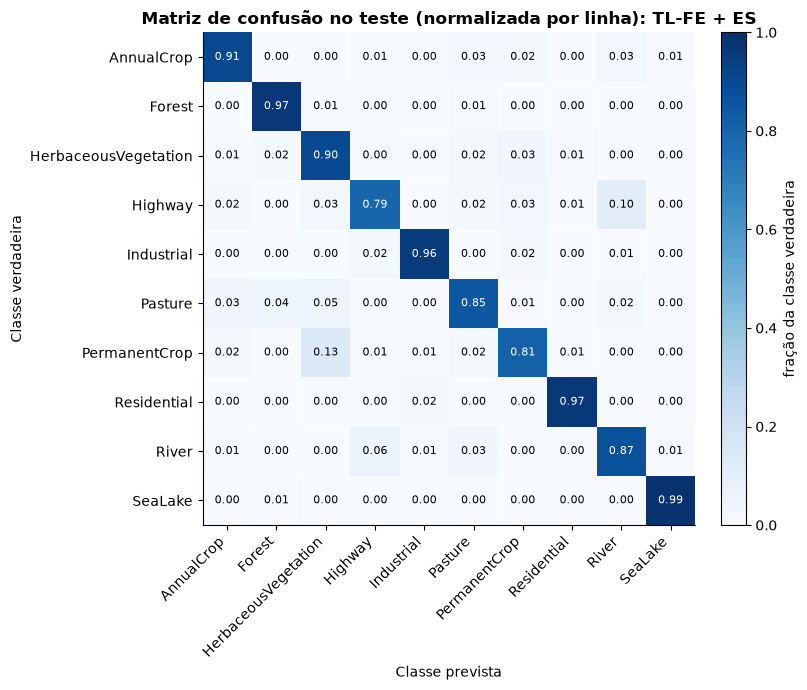

In [40]:
plot_confusion_matrix(MELHOR_TL_FE)


In [41]:
cnn, tl = MATRIZES[MELHOR_CNN]["test"], MATRIZES[MELHOR_TL_FE]["test"]
print(f"CNN = {MELHOR_CNN} · TL = {MELHOR_TL_FE} (matrizes do teste)")

print(f"Principais confusões do TL ({MELHOR_TL_FE}):")
display(top_confusions(MELHOR_TL_FE))

# As maiores confusões que sobraram na CNN (B1), agora lado a lado.
pares_cnn = [("Highway", "River"), ("Highway", "PermanentCrop"), ("PermanentCrop", "HerbaceousVegetation")]
display(pd.DataFrame(
    [{"verdadeira → prevista": f"{a} → {b}", "CNN": cnn[posicao[a], posicao[b]], "TL": tl[posicao[a], posicao[b]]}
     for a, b in pares_cnn]).set_index("verdadeira → prevista").round(3))

por_classe_tl = pd.DataFrame({
    "recall CNN": np.diag(cnn), "recall TL": np.diag(tl),
    "F1 CNN": F1_POR_CLASSE[MELHOR_CNN]["test"].to_numpy(), "F1 TL": F1_POR_CLASSE[MELHOR_TL_FE]["test"].to_numpy(),
}, index=CLASSES)
por_classe_tl["ganho de F1"] = por_classe_tl["F1 TL"] - por_classe_tl["F1 CNN"]
por_classe_tl.sort_values("ganho de F1", ascending=False).round(3)


CNN = CNN + ES + augmentation · TL = TL-FE + ES (matrizes do teste)
Principais confusões do TL (TL-FE + ES):


,classe verdadeira,prevista como,fração da classe verdadeira
0,PermanentCrop,HerbaceousVegetation,0.134
1,Highway,River,0.103
2,River,Highway,0.065
3,Pasture,HerbaceousVegetation,0.047
4,Pasture,Forest,0.041


,CNN,TL
verdadeira → prevista,,
Highway → River,0.249,0.103
Highway → PermanentCrop,0.124,0.027
PermanentCrop → HerbaceousVegetation,0.177,0.134


,recall CNN,recall TL,F1 CNN,F1 TL,ganho de F1
Highway,0.351,0.795,0.428,0.826,0.398
PermanentCrop,0.661,0.812,0.653,0.846,0.193
River,0.724,0.870,0.702,0.859,0.157
HerbaceousVegetation,0.766,0.901,0.738,0.864,0.126
Industrial,0.822,0.957,0.849,0.954,0.105
Pasture,0.892,0.851,0.779,0.837,0.058
Residential,0.924,0.969,0.916,0.973,0.057
SeaLake,0.905,0.986,0.931,0.984,0.054
Forest,0.919,0.968,0.913,0.958,0.045
AnnualCrop,0.883,0.905,0.871,0.916,0.045


**Interpretação: o que o TL corrige e o que não corrige**

- **O TL melhora as 10 classes.** Os maiores ganhos de F1 são justamente nas classes que a CNN mais errava:
  - **Highway: +0,40.** O recall sobe de 0,351 para **0,795**: a rodovia deixa de ser confundida com rio na maioria dos casos.
  - **PermanentCrop: +0,19.**
  - **River: +0,16.**

  Os menores ganhos (~+0,05) ficam em classes que a CNN já acertava bem: AnnualCrop, Forest, SeaLake e Residential.
- **As duas confusões da Highway caem bastante; a das vegetações cai pouco:**
  - Highway → River: 0,249 → 0,103;
  - Highway → PermanentCrop: 0,124 → 0,027;
  - PermanentCrop → HerbaceousVegetation: 0,177 → 0,134.

  As duas primeiras caem 10 a 15 pontos, bem acima dos ~5 pontos de ruído por classe (A3); a terceira cai 4 pontos, dentro do ruído. **Resposta à pergunta acima: em parte.** Detectores de linhas e bordas aprendidos em ~1,3 milhão de fotos distinguem uma faixa de asfalto de um rio com muito mais precisão que filtros aprendidos com 5.000 imagens. Já um pomar e um campo de vegetação rasteira continuam se confundindo quase tanto quanto na CNN.
- **O que continua difícil são os mesmos pares.** As principais confusões do TL são PermanentCrop → HerbaceousVegetation (0,134), Highway → River (0,103) e River → Highway (0,065, contra 0,086 na CNN). Pasture → HerbaceousVegetation sobe um pouco (0,020 → 0,047) e entra no top-5, dentro do ruído por classe. Esses pares parecem difíceis por natureza em 64×64 pixels: uma estrada e um rio estreito são faixas lineares parecidas, e um pomar jovem se parece com vegetação rasteira. O fine-tuning (B3) é a próxima tentativa de reduzi-los.


### Resumo da B2

| Item | Resultado |
|---|---|
| Arquitetura | MobileNetV2 (ImageNet) congelada + GAP + Dense(10, softmax): **2.270.794 parâmetros, só 12.810 treináveis** (0,6%) |
| Congelamento | Comprovado: 0 parâmetros treináveis na base e todos os pesos dela (inclusive os da BatchNorm) idênticos antes e depois do treino |
| TL-FE + ES + augmentation | F1-macro 0,900 (val): empate com a variante sem augmentation, dentro do ruído |
| **TL-FE + ES** (escolhida) | F1-macro **0,916 (val) · 0,902 (teste)**, já 0,867 de accuracy de validação na 1ª época; leve overfitting da cabeça (treino 0,986) |
| Ganho sobre a CNN e a MLP | +12 pontos de F1 sobre a CNN (0,797) e +41 sobre a MLP (0,507), na validação |
| Custo | Treino de ~160–170 s (~11 s/época × 15), na mesma ordem da CNN (~175–190 s). Inferência de ~1,75–1,8 ms/imagem, ~6× a da CNN |
| Erros restantes | PermanentCrop → HerbaceousVegetation (0,134) e Highway → River (0,103): os mesmos pares da CNN. Highway → River cai para menos da metade (0,249 → 0,103); PermanentCrop → HerbaceousVegetation cai pouco (0,177 → 0,134). River → Highway: 0,086 → 0,065 |
| Segue para a B3 | As duas variantes (decisão dos alunos), a partir dos pesos da etapa 1 guardados em `PESOS_TL_FE`. Etapa 1 escolhida: `MELHOR_TL_FE` = TL-FE + ES |


## B3. Transfer Learning: fine-tuning

### A ideia: ajustar as últimas camadas da base ao nosso domínio

A B2 mostrou que o limite está nas **features**: a camada final já ajusta quase todo o treino, mas as features foram aprendidas em fotos tiradas de lado, não em cenas vistas de cima. No **fine-tuning**, as últimas convoluções da base voltam a ser treinadas, partindo dos pesos que já têm, para se adaptarem às imagens de satélite.

**Analogia com o tabular:** é como continuar o `fit` de um modelo já ajustado com `warm_start=True` e uma taxa de aprendizado bem menor, em vez de treinar do zero. Os pesos do ImageNet são o ponto de partida, e os passos pequenos ajustam sem apagar o que já foi aprendido.

### Decisões

| Decisão | Escolha | Por quê |
|---|---|---|
| **Ponto de partida** | Os pesos da etapa 1 de cada variante (`PESOS_TL_FE`), carregados num modelo novo | Começar com a cabeça já treinada evita que gradientes grandes de uma cabeça aleatória destruam as features da base nos primeiros passos. O modelo novo deixa os da B2 intactos |
| **O que descongela** | As **10 convoluções** a partir de `block_14_expand`: os blocos 14, 15 e 16 e a `Conv_1`. São **1.510.720 parâmetros, ~67% da base** | É o último estágio da rede, depois da última redução de resolução (mapas 3×3). As primeiras camadas detectam bordas e texturas genéricas, úteis para qualquer imagem; as últimas combinam essas peças em padrões específicos do ImageNet, e são elas que precisam se adaptar. Esse estágio concentra a maior parte dos pesos, daí o cuidado com a taxa de aprendizado e com o overfitting |
| **BatchNormalization** | **Continuam congeladas**, também na região descongelada: as médias e variâncias e também os fatores γ e β (15.360 parâmetros, fora da contagem acima) | Com lotes de 64 imagens de satélite, as médias e variâncias do ImageNet seriam trocadas por estimativas ruidosas. O `training=False` não basta no Keras 3; a demonstração abaixo mostra por quê |
| **Taxa de aprendizado** | Adam com **lr 1e-5**, 100× menor que na etapa 1 | Pesos já bons pedem passos pequenos; com a lr 1e-3 da etapa 1, poucos passos bastariam para desfazer o pré-treino |
| **Compilação** | O modelo novo é compilado pela primeira vez (pelo `train_model`) **depois** de definido o que treina | No Keras, `trainable` só vale a partir da compilação seguinte. O otimizador começa do zero |
| **Variantes** | Fine-tuning das **duas** variantes da B2 (decisão dos alunos): **TL-FT + ES** e **TL-FT + ES + augmentation**. Mesmo orçamento da etapa 1 (A1) | Testa a hipótese da B2: o augmentation não ajudou uma cabeça linear sobre features fixas, mas pode ajudar quando a base se adapta. Ele também regulariza um treino com ~120× mais parâmetros treináveis que a etapa 1 |
| **Escolha do TL final** | Maior F1-macro na validação entre a etapa 1 escolhida (`MELHOR_TL_FE`) e as duas variantes de fine-tuning | Mesmo critério de todos os modelos: o fine-tuning só entra se melhorar a validação |


### Por que congelar as BatchNorm: o `training=False` não basta no Keras 3

**O que:** um modelo de brinquedo com a mesma estrutura do nosso TL: um submodelo com uma BatchNorm, chamado com `training=False` dentro de um modelo funcional. Treinamos uma época com a BatchNorm treinável e outra com ela congelada, e olhamos as médias móveis (`moving_mean`). Os dados têm média 5, e a média móvel começa em 0.
**Por quê:** o guia oficial de transfer learning do Keras recomenda chamar a base com `training=False` para manter a BatchNorm em modo de inferência no fine-tuning. Essa recomendação vem do Keras 2. No Keras 3, o `fit` repassa o seu próprio `training=True` para todas as camadas internas do modelo funcional (função `operation_fn` em `keras/src/models/functional.py`) e **sobrescreve** o `training=False`. A saída abaixo mostra o efeito: só o `trainable=False` impede a BatchNorm de trocar as estatísticas do ImageNet pelas dos nossos lotes.


In [42]:
# Modelo de brinquedo com a mesma estrutura do TL: um submodelo com BatchNorm, chamado com training=False.
gerador = np.random.default_rng(SEED)
X_brinquedo, y_brinquedo = gerador.normal(5, 2, (256, 4)).astype("float32"), np.zeros(256)
demonstracao = {}
for bn_treinavel in [True, False]:
    keras.utils.set_random_seed(SEED)
    submodelo = keras.Sequential([keras.Input(shape=(4,)), layers.BatchNormalization()], name="submodelo")
    entrada = keras.Input(shape=(4,))
    brinquedo = keras.Model(entrada, layers.Dense(1)(submodelo(entrada, training=False)))
    bn = submodelo.layers[0]
    bn.trainable = bn_treinavel
    brinquedo.compile(optimizer="adam", loss="mse")
    media_antes = bn.moving_mean.numpy().copy()  # começa em 0
    brinquedo.fit(X_brinquedo, y_brinquedo, epochs=1, batch_size=64, verbose=0)
    demonstracao[f"BatchNorm com trainable={bn_treinavel}"] = {
        "chamada com training=False?": "sim", "moving_mean antes": float(media_antes.mean()),
        "moving_mean depois do fit": float(bn.moving_mean.numpy().mean()),
        "estatísticas mudaram?": "sim" if not np.array_equal(media_antes, bn.moving_mean.numpy()) else "não"}
del brinquedo, submodelo
pd.DataFrame(demonstracao).T.round(3)


,chamada com training=False?,moving_mean antes,moving_mean depois do fit,estatísticas mudaram?
BatchNorm com trainable=True,sim,0.0,0.194667,sim
BatchNorm com trainable=False,sim,0.0,0.0,não


### Preparação dos modelos de fine-tuning

**O que:** para cada variante da B2, construir um modelo novo, carregar os pesos da etapa 1, descongelar as convoluções a partir de `block_14_expand` (mantendo todas as BatchNorm congeladas) e contar os parâmetros treináveis.
**Por quê:** a tabela mostra quanto o fine-tuning amplia o que é treinado em relação à etapa 1. A conferência das previsões garante que cada modelo parte **exatamente** do ponto em que a sua etapa 1 terminou, com a mesma cabeça treinada.


In [43]:
VARIANTES_FT = {  # variante de fine-tuning → variante da etapa 1 de onde ela parte
    "TL-FT + ES": "TL-FE + ES",
    "TL-FT + ES + augmentation": "TL-FE + ES + augmentation",
}

modelos_ft, bns_ft, contagem_ft = {}, {}, {}
for nome_ft, nome_fe in VARIANTES_FT.items():
    modelo = construir_tl(nome_ft.lower().replace("-", "_").replace(" + ", "_"), **VARIANTES_TL[nome_fe])
    # Carregamos antes de mexer no trainable, com os dois modelos no mesmo estado (base congelada).
    modelo.set_weights(PESOS_TL_FE[nome_fe])
    # Parte da etapa 1: mesmas previsões que o modelo da B2 (prova que a cabeça treinada veio junto).
    amostra_val = X_val[:256]
    assert np.allclose(modelo.predict(amostra_val, verbose=0), modelos_tl[nome_fe].predict(amostra_val, verbose=0))

    base = modelo.get_layer("mobilenetv2")
    base.trainable = True
    corte = [camada.name for camada in base.layers].index(FINE_TUNE_FROM)
    for i, camada in enumerate(base.layers):
        # Congeladas: tudo antes do corte e TODAS as BatchNorm (o fit do Keras 3 ignora o training=False).
        camada.trainable = i >= corte and not isinstance(camada, layers.BatchNormalization)
    modelos_ft[nome_ft] = modelo
    bns_ft[nome_ft] = [c for c in base.layers[corte:] if isinstance(c, layers.BatchNormalization)]
    contagem_ft[nome_ft] = {
        "convoluções descongeladas": sum(c.trainable and len(c.weights) > 0 for c in base.layers),
        "treináveis na base": int(sum(np.prod(w.shape) for w in base.trainable_weights)),
        "treináveis no modelo": int(sum(np.prod(w.shape) for w in modelo.trainable_weights)),
        "parâmetros totais": modelo.count_params(),
    }

contagem_ft = pd.DataFrame(contagem_ft).T
contagem_ft.loc["etapa 1 (B2), para comparar"] = [
    0, 0, RESULTS[MELHOR_TL_FE]["params_treinaveis"], modelos_tl[MELHOR_TL_FE].count_params()]
assert contagem_ft["parâmetros totais"].nunique() == 1           # mesma arquitetura: só muda o que treina
assert (contagem_ft["treináveis na base"].iloc[:2] == 1_510_720).all()  # os 10 kernels, sem bias
print(f"Descongeladas a partir de {FINE_TUNE_FROM} (camada {corte} de {len(base.layers)}); "
      f"as {len(bns_ft[nome_ft])} BatchNorm dessa região continuam congeladas.")
contagem_ft


Descongeladas a partir de block_14_expand (camada 125 de 154); as 10 BatchNorm dessa região continuam congeladas.


,convoluções descongeladas,treináveis na base,treináveis no modelo,parâmetros totais
TL-FT + ES,10,1510720,1523530,2270794
TL-FT + ES + augmentation,10,1510720,1523530,2270794
"etapa 1 (B2), para comparar",0,0,12810,2270794


### Treino das duas variantes (etapa 2)

**O que:** continuar o treino de cada variante com o mesmo `train_model`, agora com **lr 1e-5**, até 15 épocas e early stopping com paciência 4 (A1).
**Por quê:** é o protocolo comum, só com a taxa de aprendizado do fine-tuning. Antes do treino guardamos as médias e variâncias das BatchNorm da região descongelada, para provar depois que não mudaram.

Atenção ao ler a saída:
- A primeira época parte do ponto em que a etapa 1 parou, então a `val_loss` deve começar perto do valor da **época usada** na B2. Um salto indicaria problema na BatchNorm ou na taxa de aprendizado.
- O early stopping desta etapa só compara épocas da etapa 2 entre si. Ele **não sabe** se o fine-tuning ficou abaixo da etapa 1; isso é decidido pela validação, na avaliação mais abaixo.


In [44]:
treinos_ft, estatisticas_bn_antes = {}, {}
for nome_ft, modelo in modelos_ft.items():
    # Trava: rodar esta célula de novo sem a anterior faria um 2º fine-tuning sobre pesos já ajustados.
    assert not modelo.compiled, "reexecute a célula de preparação antes de treinar de novo"
    print(f"\n===== {nome_ft} (parte de {VARIANTES_FT[nome_ft]}) =====")
    estatisticas_bn_antes[nome_ft] = [(bn.moving_mean.numpy().copy(), bn.moving_variance.numpy().copy())
                                      for bn in bns_ft[nome_ft]]
    treinos_ft[nome_ft] = train_model(modelo, epochs=TL_EPOCHS, patience=TL_PATIENCE, lr=LR_FINE_TUNE)



===== TL-FT + ES (parte de TL-FE + ES) =====
Epoch 1/15


79/79 - 18s - 225ms/step - accuracy: 0.9774 - loss: 0.0829 - val_accuracy: 0.9170 - val_loss: 0.2589


Epoch 2/15


79/79 - 12s - 153ms/step - accuracy: 0.9868 - loss: 0.0579 - val_accuracy: 0.9180 - val_loss: 0.2648


Epoch 3/15


79/79 - 12s - 152ms/step - accuracy: 0.9906 - loss: 0.0449 - val_accuracy: 0.9190 - val_loss: 0.2692


... (13 outputs left out)

79/79 - 12s - 158ms/step - accuracy: 0.9332 - loss: 0.1868 - val_accuracy: 0.9150 - val_loss: 0.2711


Epoch 6/15


79/79 - 13s - 158ms/step - accuracy: 0.9356 - loss: 0.1855 - val_accuracy: 0.9130 - val_loss: 0.2837


→ 6 épocas em 80.1 s · menor val_loss na época 2 (0.2629) · pesos finais da época 2


### Curvas das duas etapas encadeadas

**O que:** para cada variante, as curvas da etapa 1 (B2) seguidas das da etapa 2, num único gráfico. A linha pontilhada marca a troca de etapa e as linhas verdes marcam os pesos usados em cada etapa.
**Por quê:** mostram se o fine-tuning melhora a validação além do patamar da etapa 1 ou se só aprofunda o overfitting (a loss de treino cai e a de validação não acompanha). A etapa 2 parte dos pesos da **melhor** época da etapa 1. Quando a etapa 1 rodou épocas além da melhor (área cinza), a primeira época da etapa 2 continua da linha verde da etapa 1, não do fim da área cinza.


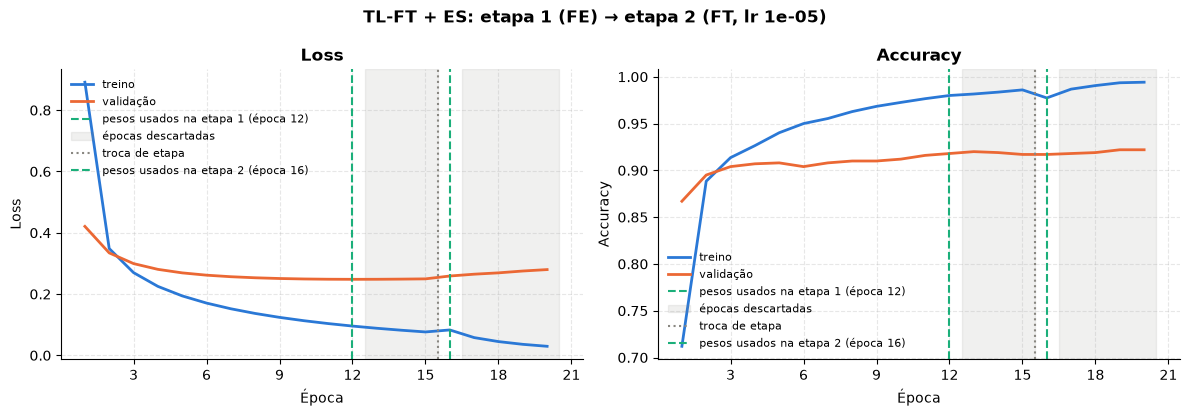

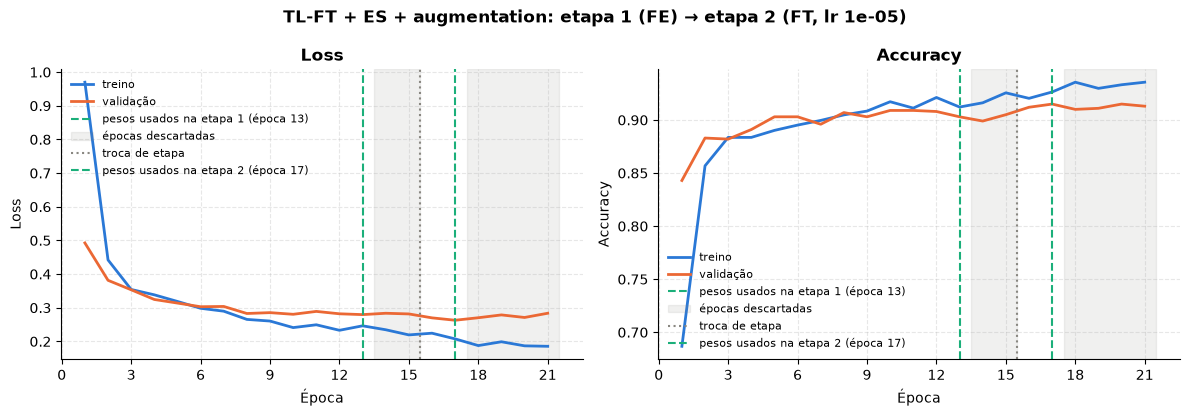

In [45]:
for nome_ft, nome_fe in VARIANTES_FT.items():
    plot_history([treinos_tl[nome_fe], treinos_ft[nome_ft]], f"{nome_ft}: etapa 1 (FE) → etapa 2 (FT, lr {LR_FINE_TUNE:g})")


**Interpretação das curvas:**
- **A troca de etapa é suave, sem salto.** A 1ª época do fine-tuning termina com `val_loss` 0,259 (sem augmentation; a época usada da etapa 1 tinha 0,248) e 0,270 (com augmentation; antes, 0,280). Um problema na BatchNorm ou uma taxa de aprendizado alta demais apareceria como um salto grande aqui.
- **TL-FT + ES (sem augmentation): o fine-tuning só aprofunda o overfitting.**
  - A loss de treino cai de 0,083 para 0,030 e a accuracy de treino vai de 0,977 a 0,994.
  - A `val_loss` **sobe** a cada época, de 0,259 para 0,280, e nunca volta ao mínimo da etapa 1 (0,248). A accuracy de validação quase não se move (0,917 → 0,922).
  - Esse é o padrão de um modelo que decora o treino e fica mais confiante, e não mais certo, na validação. O vão de accuracy treino × validação fica em ~6–7 pontos, como na etapa 1: o sinal de overfitting está na **loss**, não na accuracy.
  - O early stopping para na 5ª época e restaura a 1ª. O orçamento de 15 épocas não cortou nenhuma melhora.
- **TL-FT + ES + augmentation: um ganho pequeno.**
  - A `val_loss` melhora de 0,280 (etapa 1) para **0,263** na 2ª época e depois oscila entre 0,27 e 0,28. A accuracy de validação fica em 0,910–0,915, contra ~0,90 no fim da etapa 1.
  - A accuracy de treino, medida nas imagens aumentadas, fica em ~0,93: sem sinal de overfitting.
  - O early stopping para na 6ª época e restaura a 2ª.
- **A lr 1e-5 foi adequada:** as curvas se movem (a loss de treino cai rápido sem augmentation), mas sem instabilidade. O limite não é a taxa de aprendizado. Com 1,5 milhão de parâmetros livres e 5.000 imagens, o fine-tuning encontra rápido um jeito de reduzir a loss de treino que não generaliza, e o augmentation é o que freia isso.


### Etapa 1 × etapa 2 e escolha do TL final

**O que:**
- **Confere o fine-tuning, camada por camada, contra o modelo da etapa 1:**
  - as camadas congeladas (antes de `block_14_expand` e todas as BatchNorm) estão iguais;
  - as convoluções descongeladas mudaram;
  - como prova explícita, as médias e variâncias das BatchNorm não mudaram.
- **Avalia as duas variantes de fine-tuning.**
- **Escolhe o TL que segue para a B4.**

**Por quê:** a escolha entre feature extraction e fine-tuning usa **só o F1-macro da validação**, como todas as outras escolhas do trabalho. As tabelas trazem a MLP e a CNN escolhidas e as quatro variantes do TL (2 etapas × com/sem augmentation), o que permite separar o efeito do fine-tuning do efeito do augmentation.

**Como ler o custo do fine-tuning:**
- O tempo de treino e as épocas **somam as duas etapas**.
- O "tempo por época" é a média das duas etapas.
- "Pesos da época" conta as épocas da etapa 1 e depois a época usada na etapa 2.
- O custo da etapa 2 sozinha está na saída do treino, acima.


In [46]:
for nome_ft, nome_fe in VARIANTES_FT.items():
    modelo = modelos_ft[nome_ft]
    evaluate_model(modelo, nome_ft, [treinos_tl[nome_fe], treinos_ft[nome_ft]], relatorio=False)

    # Conferências, camada por camada, contra o modelo da etapa 1 (intacto desde a B2).
    camadas_ft = modelo.get_layer("mobilenetv2").layers
    camadas_fe = modelos_tl[nome_fe].get_layer("mobilenetv2").layers
    iguais = [all(np.array_equal(a, b) for a, b in zip(ft.get_weights(), fe.get_weights()))
              for ft, fe in zip(camadas_ft, camadas_fe) if ft.weights]
    descongeladas = [ft.trainable for ft in camadas_ft if ft.weights]
    assert all(igual for igual, treinou in zip(iguais, descongeladas) if not treinou), nome_ft
    assert not any(igual for igual, treinou in zip(iguais, descongeladas) if treinou), nome_ft
    for bn, (media, variancia) in zip(bns_ft[nome_ft], estatisticas_bn_antes[nome_ft]):
        assert np.array_equal(media, bn.moving_mean.numpy()) and np.array_equal(variancia, bn.moving_variance.numpy())
print("Fine-tuning conferido: camadas congeladas intactas, convoluções descongeladas alteradas, "
      "estatísticas das BatchNorm intactas.")

MELHOR_TL_FT = tabela_resultados().loc[list(VARIANTES_FT), "val_f1_macro"].idxmax()        # só validação
MELHOR_TL = tabela_resultados().loc[[MELHOR_TL_FE, *VARIANTES_FT], "val_f1_macro"].idxmax()  # só validação
print(f"Melhor fine-tuning: {MELHOR_TL_FT} · TL para a B4 (maior F1-macro na validação "
      f"entre {MELHOR_TL_FE} e as duas FT): {MELHOR_TL}")

desempenho, custo = tabelas_comparacao([MELHOR_MLP, MELHOR_CNN, *VARIANTES_TL, *VARIANTES_FT])
print("\nDesempenho (precision, recall e F1 em média macro):")
display(desempenho)
print("Custo (no fine-tuning, tempo e épocas somam as duas etapas):")
custo


Fine-tuning conferido: camadas congeladas intactas, convoluções descongeladas alteradas, estatísticas das BatchNorm intactas.
Melhor fine-tuning: TL-FT + ES · TL para a B4 (maior F1-macro na validação entre TL-FE + ES e as duas FT): TL-FE + ES

Desempenho (precision, recall e F1 em média macro):


validação                            teste  \
                           accuracy precision recall     F1 accuracy   
MLP + ES + augmentation       0.529     0.519  0.520  0.507    0.518   
CNN + ES + augmentation       0.810     0.801  0.803  0.797    0.792   
TL-FE + ES                    0.918     0.919  0.916  0.916    0.906   
TL-FE + ES + augmentation     0.903     0.902  0.900  0.900    0.904   
TL-FT + ES                    0.917     0.919  0.914  0.915    0.910   
TL-FT + ES + augmentation     0.915     0.914  0.912  0.912    0.908   

                                                   
                          precision recall     F1  
MLP + ES + augmentation       0.509  0.511  0.498  
CNN + ES + augmentation       0.778  0.785  0.778  
TL-FE + ES                    0.903  0.901  0.902  
TL-FE + ES + augmentation     0.902  0.900  0.900  
TL-FT + ES                    0.909  0.904  0.906  
TL-FT + ES + augmentation     0.906  0.904  0.904

Custo (no fine-tuning, tempo e épocas somam as duas etapas):


,parâmetros,treináveis,épocas rodadas,pesos da época,tempo de treino (s),tempo por época (s),inferência (ms/imagem)
MLP + ES + augmentation,3180170,3180170,40,39,80.660,2.016,0.069
CNN + ES + augmentation,111050,111050,40,40,188.523,4.713,0.278
TL-FE + ES,2270794,12810,15,12,162.236,10.816,1.764
TL-FE + ES + augmentation,2270794,12810,15,13,169.003,11.267,1.749
TL-FT + ES,2270794,1523530,20,16,228.371,11.419,1.797
TL-FT + ES + augmentation,2270794,1523530,21,17,249.068,11.860,1.789


**Interpretação:**
- **Escolha do TL final:** F1-macro de validação **0,916** (etapa 1, TL-FE + ES) × **0,915** (TL-FT + ES) × **0,912** (TL-FT + ES + augmentation). Todas as diferenças estão abaixo do ruído (~1,6 ponto, A3): **o fine-tuning empata com a etapa 1**. Pelo critério da validação, o TL que segue para a B4 é o **TL-FE + ES**. Num empate, ficar com a etapa 1 também é a escolha mais simples e mais barata.
- **Leitura 2×2 (etapa × augmentation), na validação:**

  | | sem augmentation | com augmentation |
  |---|---|---|
  | etapa 1 (FE) | 0,916 | 0,900 |
  | etapa 2 (FT) | 0,915 | 0,912 |

  - Efeito do fine-tuning: **−0,1** sem augmentation e **+1,2** com augmentation.
  - Efeito do augmentation: **−1,6** na etapa 1 e **−0,3** na etapa 2.

  Todos estão dentro do ruído. A hipótese da B2 (o augmentation só ajuda quando a base se adapta) aparece **na direção prevista**, porque com augmentation o fine-tuning melhorou a `val_loss` e o F1, e sem ele piorou a `val_loss`. Mas o efeito é pequeno demais para ser afirmado com uma única semente e 1.000 imagens de validação.
- **Precision e recall macro acompanham o F1** nas quatro variantes (0,900–0,920 na validação). O teste só confirma o empate: 0,902 (FE), 0,906 e 0,904 (FT), sem nenhuma escolha feita por ele.
- **Por que o fine-tuning não ajudou aqui:**
  - as features da etapa 1 já separavam bem as classes (a cabeça ajustava 98,6% do treino);
  - os erros que sobram são de pares parecidos por natureza (análise abaixo);
  - com 5.000 imagens, 1,5 milhão de parâmetros livres tendem a decorar o treino, como as curvas mostraram.
- **Custo:**
  - **Etapa 2 sozinha:** 66 s (5 épocas, sem augmentation) e 80 s (6 épocas, com augmentation), ~13 s por época. Só ~20% a mais que uma época da etapa 1 (~11 s), porque o gradiente só atravessa o último estágio da rede, em mapas 3×3.
  - **Total:** 228 s e 249 s, contra ~160–170 s da etapa 1: ~40–50% a mais de tempo de treino.
  - **Treináveis:** 1.523.530 contra 12.810, ~119× mais.
  - **Inferência:** a mesma da etapa 1 (~1,8 ms por imagem), porque a arquitetura não muda.
- **Vale a pena para este dataset?** Não. O fine-tuning custa ~40–50% mais tempo de treino e ~119× mais parâmetros treinados sem ganho mensurável na validação. Para o EuroSAT com 5.000 imagens em CPU, a feature extraction já captura quase tudo o que a MobileNetV2 tem a oferecer.


### Onde o fine-tuning muda os erros

**O que:** a matriz de confusão do melhor fine-tuning (teste), as principais confusões dele, as três confusões acompanhadas desde a B1 e o F1 de cada classe antes e depois do fine-tuning. "Antes" é a etapa 1 **da mesma variante** (com ou sem augmentation), não a etapa 1 escolhida na B2.
**Por quê:** comparar com a mesma variante isola o efeito do fine-tuning; senão, a diferença mediria fine-tuning e augmentation juntos. A análise mostra se adaptar a base ao domínio resolve os pares difíceis que sobraram ou se o ganho, quando existe, vem de outras classes. É **descritiva** (teste): nenhuma escolha sai daqui.


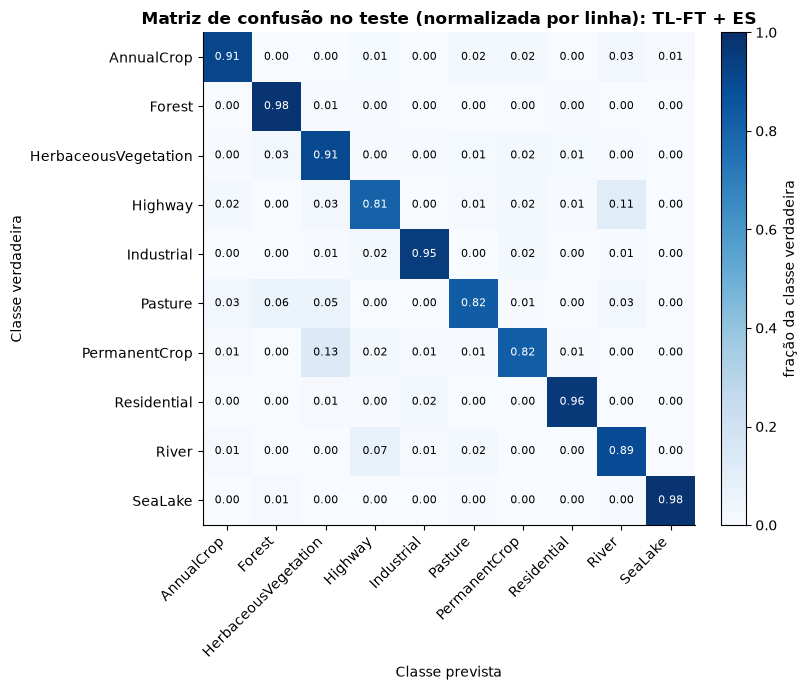

In [47]:
plot_confusion_matrix(MELHOR_TL_FT)


In [48]:
origem_ft = VARIANTES_FT[MELHOR_TL_FT]  # etapa 1 da mesma variante: isola o efeito do fine-tuning
cnn, fe, ft = (MATRIZES[nome]["test"] for nome in [MELHOR_CNN, origem_ft, MELHOR_TL_FT])
print(f"CNN = {MELHOR_CNN} · etapa 1 = {origem_ft} · etapa 2 = {MELHOR_TL_FT} (matrizes do teste)")
if MELHOR_TL != MELHOR_TL_FT:
    print(f"Atenção: o TL que segue para a B4 é {MELHOR_TL}, não o fine-tuning analisado aqui.")

print(f"Principais confusões de {MELHOR_TL_FT}:")
display(top_confusions(MELHOR_TL_FT))

display(pd.DataFrame(
    [{"verdadeira → prevista": f"{a} → {b}", "CNN": cnn[posicao[a], posicao[b]],
      "etapa 1 (FE)": fe[posicao[a], posicao[b]], "etapa 2 (FT)": ft[posicao[a], posicao[b]]}
     for a, b in pares_cnn]).set_index("verdadeira → prevista").round(3))

por_classe_ft = pd.DataFrame({
    "recall FE": np.diag(fe), "recall FT": np.diag(ft),
    "F1 FE": F1_POR_CLASSE[origem_ft]["test"].to_numpy(), "F1 FT": F1_POR_CLASSE[MELHOR_TL_FT]["test"].to_numpy(),
}, index=CLASSES)
por_classe_ft["ganho de F1"] = por_classe_ft["F1 FT"] - por_classe_ft["F1 FE"]
por_classe_ft.sort_values("ganho de F1", ascending=False).round(3)


CNN = CNN + ES + augmentation · etapa 1 = TL-FE + ES · etapa 2 = TL-FT + ES (matrizes do teste)
Atenção: o TL que segue para a B4 é TL-FE + ES, não o fine-tuning analisado aqui.
Principais confusões de TL-FT + ES:


,classe verdadeira,prevista como,fração da classe verdadeira
0,PermanentCrop,HerbaceousVegetation,0.134
1,Highway,River,0.114
2,River,Highway,0.070
3,Pasture,Forest,0.061
4,Pasture,HerbaceousVegetation,0.054


,CNN,etapa 1 (FE),etapa 2 (FT)
verdadeira → prevista,,,
Highway → River,0.249,0.103,0.114
Highway → PermanentCrop,0.124,0.027,0.022
PermanentCrop → HerbaceousVegetation,0.177,0.134,0.134


,recall FE,recall FT,F1 FE,F1 FT,ganho de F1
Pasture,0.851,0.824,0.837,0.859,0.022
PermanentCrop,0.812,0.823,0.846,0.860,0.014
AnnualCrop,0.905,0.914,0.916,0.929,0.013
SeaLake,0.986,0.982,0.984,0.986,0.002
Highway,0.795,0.805,0.826,0.828,0.002
River,0.870,0.892,0.859,0.859,0.001
HerbaceousVegetation,0.901,0.905,0.864,0.863,-0.001
Industrial,0.957,0.951,0.954,0.951,-0.003
Forest,0.968,0.982,0.958,0.954,-0.004
Residential,0.969,0.964,0.973,0.968,-0.005


**Interpretação: o fine-tuning não muda o padrão de erros**

O melhor fine-tuning (TL-FT + ES) é comparado com a etapa 1 da mesma variante (TL-FE + ES). Lembrete: **o modelo que segue para a B4 é a etapa 1**, porque as duas empataram na validação. A matriz acima é a do fine-tuning.

- **Nenhuma classe muda de forma relevante.** O ganho de F1 por classe fica entre −0,005 e +0,022, bem abaixo dos ~5 pontos de ruído por classe (A3).
- **Os três pares acompanhados desde a B1 ficam onde estavam:**
  - Highway → River: CNN 0,249 → etapa 1 0,103 → etapa 2 0,114;
  - Highway → PermanentCrop: 0,124 → 0,027 → 0,022;
  - PermanentCrop → HerbaceousVegetation: 0,177 → 0,134 → 0,134.

  O grande salto veio da troca de arquitetura (CNN → features do ImageNet), não do fine-tuning.
- **Não aparece nenhuma confusão nova.** As principais continuam sendo PermanentCrop → HerbaceousVegetation, Highway ↔ River e Pasture → Forest/HerbaceousVegetation.
- **O que isso sugere:** adaptar as últimas camadas ao domínio não resolveu os pares difíceis. Isso reforça a hipótese de que eles são ambíguos **na própria imagem 64×64**: uma estrada e um rio estreito são faixas lineares parecidas, e um pomar jovem se parece com vegetação rasteira. Reduzi-los provavelmente exigiria mais resolução ou mais informação (as bandas infravermelhas do EuroSAT multiespectral), não mais ajuste do modelo. Isso fica como limitação do trabalho.


### Resumo da B3

| Item | Resultado |
|---|---|
| Descongelamento | 10 convoluções a partir de `block_14_expand` (blocos 14–16 e `Conv_1`): **1.510.720 parâmetros, ~67% da base**. Treináveis: **1.523.530** (~119× a etapa 1) |
| BatchNorm | Congeladas também na região descongelada, porque no Keras 3 o `fit` sobrescreve o `training=False` (demonstrado). Estatísticas conferidas: intactas |
| Treino | Adam lr 1e-5, partindo dos pesos da etapa 1 de cada variante (conferido pelas previsões) |
| TL-FT + ES | F1-macro 0,915 (val) · 0,906 (teste). A `val_loss` piora desde a 1ª época; o early stopping restaura a época 1 da etapa 2. O fine-tuning só aprofunda o overfitting |
| TL-FT + ES + augmentation | F1-macro 0,912 (val) · 0,904 (teste): +1,2 ponto sobre a sua etapa 1, dentro do ruído, na direção da hipótese da B2 |
| Escolha do TL final | **Empate** entre etapa 1 e fine-tuning (0,916 × 0,915). Pelo critério da validação, segue a etapa 1, também a mais simples e barata |
| Custo do fine-tuning | Etapa 2: 66–80 s (~13 s/época). Total: 228–249 s, contra ~160–170 s da etapa 1 (~40–50% a mais). Inferência igual (~1,8 ms/imagem) |
| Erros | Inalterados (variações ≤ 0,022 de F1 por classe). Highway ↔ River e PermanentCrop → HerbaceousVegetation continuam os pares difíceis |
| Segue para a B4 | `MELHOR_TL` = **TL-FE + ES** (MobileNetV2 congelada + Dense(10)) |


## B4. Comparação final e recomendação

### Por que a comparação é justa

Cada abordagem chegou aqui pelo **mesmo processo**: variantes com e sem regularização, escolha da melhor **só pelo F1-macro da validação**, e o teste usado apenas para reportar.

| Item do protocolo | Como foi garantido |
|---|---|
| Mesmos dados | Um único split estratificado (A3): os mesmos 5.000 / 1.000 / 2.000 arrays `uint8` 64×64 para todos; o pré-processamento fica dentro de cada modelo |
| Mesmo treino | `train_model` comum: Adam, entropia cruzada, batch 64, early stopping na `val_loss` com restauração da melhor época |
| Mesma seleção | Variantes com e sem augmentation nas três abordagens (na MLP, também dropout e L2; no TL, também etapa 1 × fine-tuning). Vence o maior F1-macro na validação; em empate, fica a opção listada primeiro, a mais simples |
| Mesma avaliação | `evaluate_model` comum: métricas macro na validação e no teste, tempo de treino medido em volta do `fit`, inferência = mediana de 3 medições |
| Mesmo hardware | Tudo em CPU (GPU desligada no A1) |

**Diferenças assumidas** (todas definidas no A1 e justificadas nas seções de cada modelo):
- **Orçamento do TL:** 15 épocas por etapa (até 30 com fine-tuning) e paciência 4, contra 40 épocas e paciência 8 na MLP e na CNN. O TL parte de pesos treinados e cada época custa mais.
- **Taxa de aprendizado:** 1e-5 no fine-tuning (B3), contra 1e-3 em todos os outros treinos.
- **Resolução interna:** o TL recebe o mesmo array 64×64, mas o amplia para 96×96 dentro do modelo, o que encarece cada imagem processada.
- **Pré-treino:** o TL herda um treino no ImageNet cujo custo não entra na conta. É justamente a vantagem que o Transfer Learning oferece.
- **Convergência:** a MLP e a CNN escolhidas ainda melhoravam perto do fim das 40 épocas (o early stopping não parou nenhuma delas). Os números delas valem "no orçamento de 40 épocas"; a coluna "pesos da época" da tabela mostra isso.

### Tabela comparativa

**O que:** os três modelos escolhidos lado a lado, com os quatro itens pedidos no enunciado (accuracy, F1-score, tempo de treinamento e número de parâmetros), mais parâmetros treináveis, épocas, tempo por época e tempo de inferência.
**Por quê:** é a base da discussão final. O F1-macro é a métrica principal (cada classe pesa igual, A1), e a comparação entre abordagens se lê no **teste**. A coluna da validação aparece porque foi ela que escolheu cada modelo. Por isso mesmo ela é levemente otimista para o vencedor de cada abordagem.


In [49]:
FINALISTAS = {"MLP": MELHOR_MLP, "CNN própria": MELHOR_CNN, "Transfer Learning": MELHOR_TL}
escolhidos = list(FINALISTAS.values())
ABORDAGEM = {  # variante → abordagem (usado no anexo e na exportação)
    **{nome: "MLP" for nome in ["MLP baseline", *VARIANTES_MLP]},
    **{nome: "CNN própria" for nome in VARIANTES_CNN},
    **{nome: "Transfer Learning" for nome in [*VARIANTES_TL, *VARIANTES_FT]},
}
assert set(ABORDAGEM) == set(RESULTS)  # nenhuma variante fica de fora

finais = tabela_resultados().loc[escolhidos]
tabela_final = pd.DataFrame({
    "variante escolhida": escolhidos,
    "accuracy (teste)": finais["test_accuracy"].to_numpy(),
    "F1-macro (teste)": finais["test_f1_macro"].to_numpy(),
    "F1-macro (validação)": finais["val_f1_macro"].to_numpy(),
    "tempo de treino (s)": finais["tempo_treino_s"].to_numpy(),
    "épocas": finais["epocas"].to_numpy(),
    "pesos da época": finais["pesos_da_epoca"].to_numpy(),
    "tempo por época (s)": (finais["tempo_treino_s"] / finais["epocas"]).to_numpy(),
    "parâmetros totais": finais["params_totais"].to_numpy(),
    "parâmetros treináveis": finais["params_treinaveis"].to_numpy(),
    "inferência (ms/imagem)": finais["tempo_inferencia_ms_por_imagem"].to_numpy(),
}, index=pd.Index(list(FINALISTAS), name="abordagem"))

br = {"decimal": ",", "thousands": "."}  # números no padrão brasileiro, como no texto
(tabela_final.style
 .format(precision=3, subset=["accuracy (teste)", "F1-macro (teste)", "F1-macro (validação)"], **br)
 .format(precision=0, subset=["tempo de treino (s)", "parâmetros totais", "parâmetros treináveis"], **br)
 .format(precision=1, subset=["tempo por época (s)"], **br)
 .format(precision=2, subset=["inferência (ms/imagem)"], **br))


,variante escolhida,accuracy (teste),F1-macro (teste),F1-macro (validação),tempo de treino (s),épocas,pesos da época,tempo por época (s),parâmetros totais,parâmetros treináveis,inferência (ms/imagem)
abordagem,,,,,,,,,,,
MLP,MLP + ES + augmentation,"0,518","0,498","0,507",81,40,39,"2,0",3.180.170,3.180.170,"0,07"
CNN própria,CNN + ES + augmentation,"0,791","0,778","0,797",189,40,40,"4,7",111.050,111.050,"0,28"
Transfer Learning,TL-FE + ES,"0,906","0,902","0,916",162,15,12,"10,8",2.270.794,12.810,"1,76"


**Interpretação:**
- **Ranking claro e estável:** TL > CNN > MLP, na validação e no teste. No teste, o F1-macro vai de **0,498** (MLP) a **0,778** (CNN) e a **0,902** (TL). São vãos de +28 e +12 pontos, muito acima do ruído de amostragem (~1,6 ponto, A3).
- **Validação e teste concordam:** em cada abordagem, o teste fica no máximo ~1,9 ponto abaixo da validação. É o pequeno otimismo esperado de quem foi escolhido pela validação, sem sinal de que a seleção tenha se ajustado demais a ela.
- **Accuracy ≈ F1-macro** nos três (0,518 × 0,498; 0,791 × 0,778; 0,906 × 0,902). O vão é de ~2 pontos na MLP, ~1,4 na CNN e ~0,4 no TL.
- **Convergência:** a MLP e a CNN usaram os pesos das épocas 39 e 40 de 40, e o TL os da época 12 de 15. Só o TL convergiu dentro do orçamento.
- **Tempo:** o TL e a CNN treinam na **mesma ordem de tempo** (~160 s × ~190 s nesta execução, com o TL um pouco mais rápido). A CNN roda 40 épocas de ~4,7 s; o TL, 15 épocas de ~11 s.


### Desempenho × custo

**O que:** o F1-macro no teste de cada modelo contra dois custos, em painéis separados que dividem o mesmo eixo de F1: o **tempo de treino** e o **tempo de inferência** (escala logarítmica, porque vai de centésimos a alguns milissegundos). Os três modelos escolhidos aparecem em verde; as outras variantes de cada abordagem, em cinza, mostram o resto do caminho.
**Por quê:** o enunciado pede para pesar o resultado contra o custo computacional em CPU. O ideal é o canto superior esquerdo de cada painel (F1 alto, custo baixo).


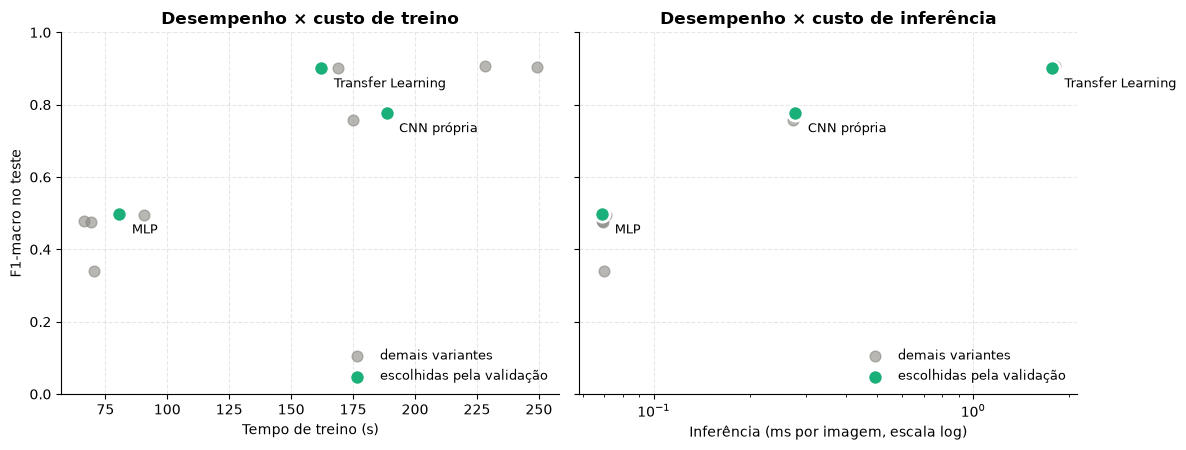

In [50]:
tabela = tabela_resultados()
outras = tabela.drop(index=escolhidos)

fig, eixos = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
paineis = [("tempo_treino_s", "Tempo de treino (s)", "Desempenho × custo de treino"),
           ("tempo_inferencia_ms_por_imagem", "Inferência (ms por imagem, escala log)", "Desempenho × custo de inferência")]
for ax, (coluna, rotulo, titulo) in zip(eixos, paineis):
    ax.scatter(outras[coluna], outras["test_f1_macro"], s=60, color=CORES["neutro"], alpha=0.6,
               label="demais variantes", zorder=2)
    ax.scatter(tabela.loc[escolhidos, coluna], tabela.loc[escolhidos, "test_f1_macro"], s=120,
               color=CORES["destaque"], edgecolor="white", linewidth=2, label="escolhidas pela validação", zorder=3)
    for abordagem, nome in FINALISTAS.items():
        ax.annotate(abordagem, (tabela.loc[nome, coluna], tabela.loc[nome, "test_f1_macro"]),
                    textcoords="offset points", xytext=(9, -14), fontsize=9)
    ax.set_xlabel(rotulo)
    ax.set_title(titulo)
eixos[1].set_xscale("log")
eixos[0].set_ylabel("F1-macro no teste")
eixos[0].set_ylim(0, 1)
for ax in eixos:
    ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
plt.show()


**Interpretação:**
- **No custo de treino, o TL domina a CNN:** um pouco menos tempo (~160 s × ~190 s) e 12 pontos de F1 a mais. A MLP é a mais barata (~80 s), mas fica muito abaixo. Os pontos cinza do TL à direita são o fine-tuning: ~40–50% mais tempo de treino para o mesmo F1 (B3).
- **No custo de inferência, a ordem se inverte:** é o único eixo em que o TL paga mais. Ele leva ~1,8 ms por imagem, contra ~0,28 ms da CNN (~6×) e ~0,07 ms da MLP (~25×), porque cada previsão atravessa a MobileNetV2 inteira em 96×96.
- **Nenhuma variante descartada (cinza) muda a conclusão:** todas as MLPs ficam entre 0,34 e 0,50; a CNN sem augmentation fica abaixo da escolhida (0,758 × 0,778); as variantes do TL ficam todas em ~0,90.


### F1 por classe

**O que:** o F1 de cada classe no teste para os três modelos escolhidos, com as classes ordenadas da mais difícil para a mais fácil segundo o TL.
**Por quê:** o F1-macro é uma média. Este mapa mostra **onde** cada abordagem ganha e quais classes continuam difíceis para todas. É uma leitura **descritiva** do teste: nenhuma escolha sai daqui.


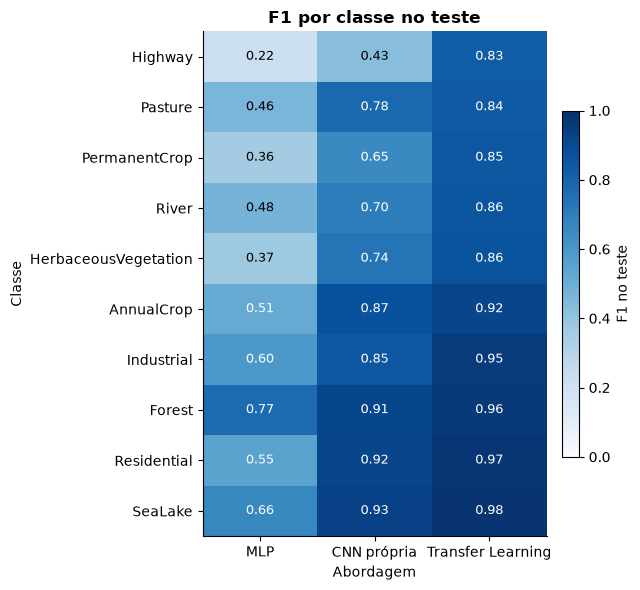

In [51]:
f1_finalistas = pd.DataFrame({abordagem: F1_POR_CLASSE[nome]["test"] for abordagem, nome in FINALISTAS.items()})
f1_finalistas = f1_finalistas.sort_values("Transfer Learning")  # mais difícil para o TL no topo

fig, ax = plt.subplots(figsize=(6.5, 6))
imagem = ax.imshow(f1_finalistas.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
for i in range(len(f1_finalistas)):
    for j in range(f1_finalistas.shape[1]):
        valor = f1_finalistas.iat[i, j]
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=9,
                color="white" if valor > 0.5 else "black")
ax.set_xticks(range(f1_finalistas.shape[1]), f1_finalistas.columns)
ax.set_yticks(range(len(f1_finalistas)), f1_finalistas.index)
ax.set_xlabel("Abordagem")
ax.set_ylabel("Classe")
ax.set_title("F1 por classe no teste")
ax.grid(False)
fig.colorbar(imagem, ax=ax, fraction=0.046, pad=0.04, label="F1 no teste")
fig.tight_layout()
plt.show()


**Interpretação:**
- **TL ≥ CNN ≥ MLP em todas as 10 classes.** Nenhuma abordagem perde, em nenhuma classe, para uma mais simples.
- **As mesmas 5 classes são as mais difíceis para os três modelos:** Highway, PermanentCrop, River, HerbaceousVegetation e Pasture. A arquitetura muda o nível do acerto, não a ordem de dificuldade. São os pares de aparência parecida discutidos desde a A2: faixas lineares (Highway × River) e vegetações (PermanentCrop × HerbaceousVegetation × Pasture).
- **A MLP desaba justamente nessas classes:** F1 de 0,22 em Highway e 0,36 em PermanentCrop. Com a imagem achatada, sobra a cor média, que não separa essas classes. É a limitação vista na A6.
- **O desbalanceamento não explica a dificuldade**, apesar de 4 das 5 classes mais difíceis estarem entre as 5 menores. Três evidências indicam a semelhança visual como causa:
  - a diferença de exemplos é pequena (370 contra 556 imagens de treino, no máximo 1,5×);
  - Industrial, do mesmo tamanho de Highway, tem F1 de 0,95 no TL, enquanto Highway é a pior nos três modelos;
  - na A5, Pasture, a menor classe, foi prevista **mais** vezes do que existe pela MLP baseline (93 previsões para 74 imagens reais na validação), o oposto do que o desbalanceamento causaria.

  Isso confirma o diagnóstico da A5: não havia razão para usar `class_weight`.


### Anexo: todas as variantes treinadas

**O que:** as 11 variantes treinadas no notebook, com a abordagem de cada uma e a marca das três que entraram na comparação final.
**Por quê:** transparência da seleção. Cada escolha veio do F1-macro da **validação**, e o teste não decidiu nada. O caso mais visível é o fine-tuning: o TL-FT + ES tem F1 de teste um pouco maior que o TL-FE + ES escolhido (0,906 × 0,902), mas perdeu na validação por 0,0013. A MLP baseline aparece na tabela, mas não era candidata: é o "antes" do diagnóstico, sem early stopping (A6).


In [52]:
todas = tabela_resultados()[["val_f1_macro", "test_f1_macro", "epocas", "tempo_treino_s", "params_treinaveis"]]
todas.insert(0, "abordagem", [ABORDAGEM[nome] for nome in todas.index])
todas["na comparação final"] = ["✔" if nome in escolhidos else "" for nome in todas.index]
todas = todas.rename(columns={
    "val_f1_macro": "F1-macro val", "test_f1_macro": "F1-macro teste", "epocas": "épocas",
    "tempo_treino_s": "tempo de treino (s)", "params_treinaveis": "parâmetros treináveis",
})
(todas.style
 .format(precision=3, subset=["F1-macro val", "F1-macro teste"], **br)
 .format(precision=0, subset=["tempo de treino (s)", "parâmetros treináveis"], **br))


,abordagem,F1-macro val,F1-macro teste,épocas,tempo de treino (s),parâmetros treináveis,na comparação final
MLP baseline,MLP,"0,482","0,477",40,69,3.180.170,
MLP + ES,MLP,"0,469","0,479",39,66,3.180.170,
MLP + ES + dropout,MLP,"0,339","0,340",40,70,3.180.170,
MLP + ES + L2,MLP,"0,489","0,496",40,91,3.180.170,
MLP + ES + augmentation,MLP,"0,507","0,498",40,81,3.180.170,✔
CNN + ES,CNN própria,"0,761","0,758",40,175,111.050,
CNN + ES + augmentation,CNN própria,"0,797","0,778",40,189,111.050,✔
TL-FE + ES,Transfer Learning,"0,916","0,902",15,162,12.810,✔
TL-FE + ES + augmentation,Transfer Learning,"0,900","0,900",15,169,12.810,
TL-FT + ES,Transfer Learning,"0,915","0,906",20,228,1.523.530,


### Exportação dos resultados

**O que:** gravar três tabelas em `outputs/`:
- `resultados_eurosat.csv`: uma linha por variante, com todas as métricas, a abordagem e a marca das três da comparação final;
- `f1_por_classe_eurosat.csv`: o F1 de cada classe, por variante e por conjunto (validação e teste);
- `execucao_eurosat.csv`: de qual execução vieram os números (modo, tamanhos do split, assinatura do split, processador, versões e modelos escolhidos).

**Por quê:** o `relatorio.ipynb` carrega essas tabelas em vez de copiar números à mão, e confere pela terceira que leu uma execução completa. No modo smoke, os arquivos ganham o sufixo `_smoke` e nunca sobrescrevem os resultados reais (A1).


In [53]:
resultados = tabela_resultados()
resultados.insert(0, "abordagem", [ABORDAGEM[nome] for nome in resultados.index])
resultados.insert(1, "na_comparacao_final", resultados.index.isin(escolhidos))
resultados.index.name = "modelo"
resultados.to_csv(RESULTS_CSV)

f1_longo = pd.DataFrame(
    [(modelo, ABORDAGEM[modelo], classe, conjunto, f1) for modelo, f1_modelo in F1_POR_CLASSE.items()
     for conjunto in f1_modelo for classe, f1 in f1_modelo[conjunto].items()],
    columns=["modelo", "abordagem", "classe", "conjunto", "f1"])
f1_longo.to_csv(F1_CLASSES_CSV, index=False)

# De qual execução vieram os números: o relatório confere isto antes de usar as tabelas.
execucao = pd.DataFrame([{
    "modo": "smoke" if SMOKE_TEST else "completo", "data": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"),
    "n_treino": len(y_train), "n_validacao": len(y_val), "n_teste": len(y_test),
    "assinatura_split": assinatura.hexdigest()[:12], "processador": nome_do_processador(),
    "tensorflow": tf.__version__, "keras": keras.__version__,
    "melhor_mlp": MELHOR_MLP, "melhor_cnn": MELHOR_CNN, "melhor_tl": MELHOR_TL,
}])
execucao.to_csv(EXECUCAO_CSV, index=False)

pd.DataFrame({"linhas": [len(resultados), len(f1_longo), len(execucao)],
              "colunas": [resultados.shape[1], f1_longo.shape[1], execucao.shape[1]]},
             index=[RESULTS_CSV.as_posix(), F1_CLASSES_CSV.as_posix(), EXECUCAO_CSV.as_posix()])


,linhas,colunas
outputs/resultados_eurosat.csv,11,16
outputs/f1_por_classe_eurosat.csv,220,5
outputs/execucao_eurosat.csv,1,12


### Discussão: qual abordagem valeu mais a pena

**Veredito: o Transfer Learning com feature extraction (MobileNetV2 congelada + `Dense(10)`) é a abordagem recomendada para este problema.**

| Critério | MLP | CNN própria | **Transfer Learning (FE)** |
|---|---|---|---|
| **Resultado** (F1-macro no teste) | 0,498 | 0,778 | **0,902** |
| **Custo de treino em CPU** | ~80 s | ~175–190 s | **~160–170 s** |
| **Custo de inferência** | ~0,07 ms/imagem | ~0,28 ms/imagem | ~1,8 ms/imagem |
| **Parâmetros** (totais / treinados) | 3.180.170 / todos | 111.050 / todos | 2.270.794 / **12.810** |
| **Dependência do tamanho do dataset** | não aprende o suficiente com 5.000 imagens | ainda melhorava na última época (40) | aproveita ~1,3 milhão de imagens do ImageNet |

**Por que o TL vale mais a pena, critério por critério:**
- **Resultado:** +12 pontos de F1 sobre a CNN e +40 sobre a MLP. O ranking se repete na validação e no teste, e a ordem das classes difíceis é a mesma nos três modelos. A diferença é de nível, não de sorte.
- **Custo de treino em CPU:** o TL treina na **mesma ordem de tempo** que a CNN (nesta execução, até um pouco mais rápido). Esse custo vem da passada pela base congelada em cada época, não dos 12.810 parâmetros treinados. Sem augmentation, calcular as features uma única vez cortaria o treino para a ordem de ~11 s (estimativa, não medida, B2). O treino de todas as variantes do TL (B2 + B3) levou ~8 min, dentro da estimativa de ~10 min feita no A3.
- **Custo de inferência:** é o único ponto fraco medido: ~6× a CNN (e o modelo inteiro é ~20× maior). Em termos absolutos, porém, classificar as 2.000 imagens do teste leva ~3,5 s em CPU, aceitável para mapear uso do solo em lote. Só pesaria em tempo real ou num dispositivo muito limitado.
- **Parâmetros:** mais parâmetros não significam melhor resultado. A MLP tem o maior número e o pior F1. O que conta é o **viés indutivo**: a convolução enxerga vizinhanças, e o pré-treino traz features prontas.
- **Tamanho do dataset:** é o fator decisivo.
  - Com 5.000 imagens, filtros aprendidos do zero ficam limitados: a CNN ainda melhorava na 40ª e última época, 12 pontos abaixo do TL.
  - As features do ImageNet transferem bem mesmo vindo de fotos tiradas de lado.
  - Ajustá-las com fine-tuning não compensa neste volume: empate na validação, ~40–50% mais tempo e ~119× mais parâmetros treinados (B3).
  - Hipótese não testada: com o EuroSAT completo (~27 mil imagens), a CNN teria mais dados para aprender filtros próprios, e o vão para o TL tenderia a diminuir.

**Recomendação:**
1. **TL com feature extraction** (TL-FE + ES): melhor resultado, mesmo custo de treino da CNN e o treino mais simples (só a camada final).
2. **CNN própria** só se a inferência for o gargalo (tempo real, dispositivo embarcado) ou se não for possível usar pesos pré-treinados. O preço é ~12 pontos de F1, concentrados em Highway, PermanentCrop e River.
3. **Fine-tuning** não se paga neste dataset: mais custo sem ganho.
4. **MLP** descartada: achatar a imagem destrói a vizinhança entre pixels, e o modelo fica em underfitting, guiado pela cor média (A5 e A6).

**Limitações:**
- **Uma única semente e uma única máquina:** pequenas variações numéricas entre CPUs mudam a trajetória do treino (A1). Os vãos entre abordagens (12 e 28 pontos) estão muito acima do ruído, mas as diferenças entre variantes de uma mesma abordagem (1–2 pontos) não devem ser lidas como ranking.
- **Correlação espacial:** a checagem MD5 só remove duplicatas exatas. Recortes vizinhos da mesma região podem cair em conjuntos diferentes, o que deixa as métricas um pouco otimistas para **todos** os modelos; o ranking não deve mudar.
- **Tempos ruidosos:** os tempos variam entre execuções e entre máquinas, e cada variante foi medida uma vez. Valem as ordens de grandeza, não diferenças de poucos segundos (como TL × CNN nesta execução).
- **Orçamento de épocas:** a MLP e a CNN talvez melhorassem um pouco com mais de 40 épocas, mas não o bastante para fechar 12 pontos.
- **Pares ambíguos em 64×64 RGB:** Highway ↔ River e PermanentCrop → HerbaceousVegetation continuam sendo os maiores erros mesmo no melhor modelo. Mais resolução ou as bandas infravermelhas do EuroSAT multiespectral ficaram fora do escopo.
- **Pré-treino fora da conta:** o custo de treinar a MobileNetV2 no ImageNet não entra na comparação. Ele foi pago por quem publicou os pesos.
